In [1]:
import os
import re
from collections import defaultdict, deque
from functools import lru_cache
from pathlib import Path
import matplotlib as mpl
from matplotlib import gridspec
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import pandas as pd
import numpy as np

plt.rcParams['svg.fonttype'] = 'none'

In [2]:
contacts_df = pd.read_csv("contacts-all13pf.csv")
hbonds_df = pd.read_csv("hbonds-all13pf.csv")

contacts_df.head(), hbonds_df.head()
contacts_df.keys(), hbonds_df.keys()

(Index(['source_pdb', 'atom1', 'atom2', 'overlap', 'distance',
        'atom1_source_pdb', 'atom1_model', 'atom1_chain', 'atom1_residue',
        'atom1_residue_number', 'atom1_atom', 'atom1_altloc',
        'atom2_source_pdb', 'atom2_model', 'atom2_chain', 'atom2_residue',
        'atom2_residue_number', 'atom2_atom', 'atom2_altloc'],
       dtype='str'),
 Index(['source_pdb', 'donor', 'acceptor', 'hydrogen', 'd_a_dist', 'd_h_a_dist',
        'donor_source_pdb', 'donor_model', 'donor_chain', 'donor_residue',
        'donor_residue_number', 'donor_atom', 'donor_altloc',
        'acceptor_source_pdb', 'acceptor_model', 'acceptor_chain',
        'acceptor_residue', 'acceptor_residue_number', 'acceptor_atom',
        'acceptor_altloc', 'hydrogen_source_pdb', 'hydrogen_model',
        'hydrogen_chain', 'hydrogen_residue', 'hydrogen_residue_number',
        'hydrogen_atom', 'hydrogen_altloc', 'hbond_flavor', 'hbond_file'],
       dtype='str'))

In [3]:
# Build a unified interaction-edge table from contacts + hbonds.
# Tracks source and category for downstream plotting/analysis.


def _hbond_category(value):
    s = str(value).lower()
    if "saltbridges" in s or "_salt" in s or "salt" in s:
        return "salt"
    if "strict" in s:
        return "strict"
    if 'loose' in s:
        return "relaxed"
    return "other_hbond"


def _first_existing(df, candidates, default=None):
    for col in candidates:
        if col in df.columns:
            return col
    return default


def _derive_dataset_folder(source_pdb):
    return str(source_pdb).replace(".pdb", "") if pd.notna(source_pdb) else None


def build_unified_interaction_edges(contacts_df, hbonds_df):
    # Fallback if atom_node is defined in a later cell.
    node_fn = globals().get("atom_node")
    if node_fn is None:
        def node_fn(chain, residue, residue_number, atom):
            return f"{chain}:{residue}:{int(float(residue_number))}:{atom}"

    # --- contacts edges ---
    c = contacts_df.copy()
    c = c.dropna(
        subset=[
            "atom1_chain",
            "atom1_residue",
            "atom1_residue_number",
            "atom1_atom",
            "atom2_chain",
            "atom2_residue",
            "atom2_residue_number",
            "atom2_atom",
        ]
    )

    # Ensure contact category exists even if classification cell was not run.
    if "contact_category" not in c.columns:
        def _atom_family(atom_name):
            if pd.isna(atom_name):
                return None
            a = str(atom_name).strip().upper()
            if not a:
                return None
            first = a[0]
            return first if first in {"C", "N", "O", "S", "P", "B", "A", "F", "M"} else None

        def _classify_contact_local(a1, a2):
            f1 = _atom_family(a1)
            f2 = _atom_family(a2)
            if f1 == "C" and f2 == "C":
                return "hydrophobic"
            if f1 in {"N", "O", "S", "P", "B", "A", "F", "M"} and f2 in {"N", "O", "S", "P", "B", "A", "F", "M"}:
                return "polar"
            return "other"

        c["contact_category"] = c.apply(
            lambda r: _classify_contact_local(r["atom1_atom"], r["atom2_atom"]),
            axis=1,
        )

    c["node1"] = c.apply(
        lambda r: node_fn(r["atom1_chain"], r["atom1_residue"], r["atom1_residue_number"], r["atom1_atom"]),
        axis=1,
    )
    c["node2"] = c.apply(
        lambda r: node_fn(r["atom2_chain"], r["atom2_residue"], r["atom2_residue_number"], r["atom2_atom"]),
        axis=1,
    )

    contacts_edges = c[["source_pdb", "node1", "node2", "distance", "overlap", "contact_category"]].copy()
    contacts_edges["interaction_source"] = "contacts"
    contacts_edges["interaction_category"] = contacts_edges["contact_category"].fillna("other")
    contacts_edges["dataset_folder"] = contacts_edges["source_pdb"].map(_derive_dataset_folder)
    contacts_edges["interface_type"] = None
    contacts_edges["hbond_file"] = None
    contacts_edges = contacts_edges.drop(columns=["contact_category"])

    # --- hbonds edges (donor-acceptor) ---
    if hbonds_df is not None and not hbonds_df.empty:
        h = hbonds_df.copy()
        h = h.dropna(
            subset=[
                "donor_chain",
                "donor_residue",
                "donor_residue_number",
                "donor_atom",
                "acceptor_chain",
                "acceptor_residue",
                "acceptor_residue_number",
                "acceptor_atom",
            ]
        )

        h["node1"] = h.apply(
            lambda r: node_fn(r["donor_chain"], r["donor_residue"], r["donor_residue_number"], r["donor_atom"]),
            axis=1,
        )
        h["node2"] = h.apply(
            lambda r: node_fn(r["acceptor_chain"], r["acceptor_residue"], r["acceptor_residue_number"], r["acceptor_atom"]),
            axis=1,
        )

        dist_col = _first_existing(h, ["d_a_dist", "distance"])
        category_col = _first_existing(h, ["contact_set", "hbond_flavor", "hbond_file"])

        if dist_col is None:
            h["distance"] = None
            dist_col = "distance"

        hbonds_edges = h[["source_pdb", "node1", "node2", dist_col]].copy()
        hbonds_edges = hbonds_edges.rename(columns={dist_col: "distance"})

        if "dataset_folder" in h.columns:
            hbonds_edges["dataset_folder"] = h["dataset_folder"]
        else:
            hbonds_edges["dataset_folder"] = h["source_pdb"].map(_derive_dataset_folder)

        hbonds_edges["interface_type"] = h["interface_type"] if "interface_type" in h.columns else None
        hbonds_edges["hbond_file"] = h["hbond_file"] if "hbond_file" in h.columns else None
        hbonds_edges["overlap"] = None
        hbonds_edges["interaction_source"] = "hbonds"

        if category_col is None:
            hbonds_edges["interaction_category"] = "other_hbond"
        else:
            hbonds_edges["interaction_category"] = h[category_col].map(_hbond_category)
    else:
        hbonds_edges = pd.DataFrame(
            columns=[
                "source_pdb",
                "node1",
                "node2",
                "distance",
                "dataset_folder",
                "interface_type",
                "hbond_file",
                "overlap",
                "interaction_source",
                "interaction_category",
            ]
        )

    # --- unify ---
    unified_edges = pd.concat([contacts_edges, hbonds_edges], ignore_index=True, sort=False)

    # Keep a stable undirected key for downstream grouping.
    unified_edges["edge_key"] = unified_edges.apply(
        lambda r: tuple(sorted((r["node1"], r["node2"]))),
        axis=1,
    )

    return unified_edges


unified_edges_df = build_unified_interaction_edges(contacts_df, hbonds_df)

print(f"Unified interaction rows: {len(unified_edges_df):,}")

display(
    unified_edges_df.groupby(["interaction_source", "interaction_category"])
    .size()
    .rename("count")
    .reset_index()
    .sort_values(["interaction_source", "interaction_category"])
)

display(
    unified_edges_df.groupby(["source_pdb", "interaction_source", "interaction_category"])
    .size()
    .rename("count")
    .reset_index()
    .sort_values(["source_pdb", "interaction_source", "interaction_category"])
)

unified_edges_df.head()

Unified interaction rows: 124,043


,interaction_source,interaction_category,count
0,contacts,hydrophobic,6651
1,contacts,other,75005
2,contacts,polar,16265
3,hbonds,strict,26122


,source_pdb,interaction_source,interaction_category,count
0,AlF3_6mer_swapAtoms.pdb,contacts,hydrophobic,1617
1,AlF3_6mer_swapAtoms.pdb,contacts,other,19397
2,AlF3_6mer_swapAtoms.pdb,contacts,polar,4886
3,AlF3_6mer_swapAtoms.pdb,hbonds,strict,7415
4,BeF3_6mer_swapAtoms.pdb,contacts,hydrophobic,1509
5,BeF3_6mer_swapAtoms.pdb,contacts,other,18089
6,BeF3_6mer_swapAtoms.pdb,contacts,polar,4140
7,BeF3_6mer_swapAtoms.pdb,hbonds,strict,7440
8,GDP_13pf_6mer_fitted.pdb,contacts,hydrophobic,1557
9,GDP_13pf_6mer_fitted.pdb,contacts,other,17562


,source_pdb,node1,node2,distance,overlap,interaction_source,interaction_category,dataset_folder,interface_type,hbond_file,edge_key
0,AlF3_6mer_swapAtoms.pdb,X:HOH:410:O,W:HOH:364:O,0.318,2.202,contacts,polar,AlF3_6mer_swapAtoms,None,None,"(W:HOH:364:O, X:HOH:410:O)"
1,AlF3_6mer_swapAtoms.pdb,O:HOH:1:O,F:AF3:503:AL01,1.694,1.866,contacts,polar,AlF3_6mer_swapAtoms,None,None,"(F:AF3:503:AL01, O:HOH:1:O)"
2,AlF3_6mer_swapAtoms.pdb,N:HOH:1:O,C:AF3:503:AL01,1.694,1.866,contacts,polar,AlF3_6mer_swapAtoms,None,None,"(C:AF3:503:AL01, N:HOH:1:O)"
3,AlF3_6mer_swapAtoms.pdb,F:AF3:503:AL01,F:GDP:501:O2B,2.339,1.261,contacts,polar,AlF3_6mer_swapAtoms,None,None,"(F:AF3:503:AL01, F:GDP:501:O2B)"
4,AlF3_6mer_swapAtoms.pdb,C:AF3:503:AL01,C:GDP:501:O2B,2.339,1.261,contacts,polar,AlF3_6mer_swapAtoms,None,None,"(C:AF3:503:AL01, C:GDP:501:O2B)"


In [4]:
unified_edges_df.to_csv("unified_edges_df-13pf-swapAtoms.csv")

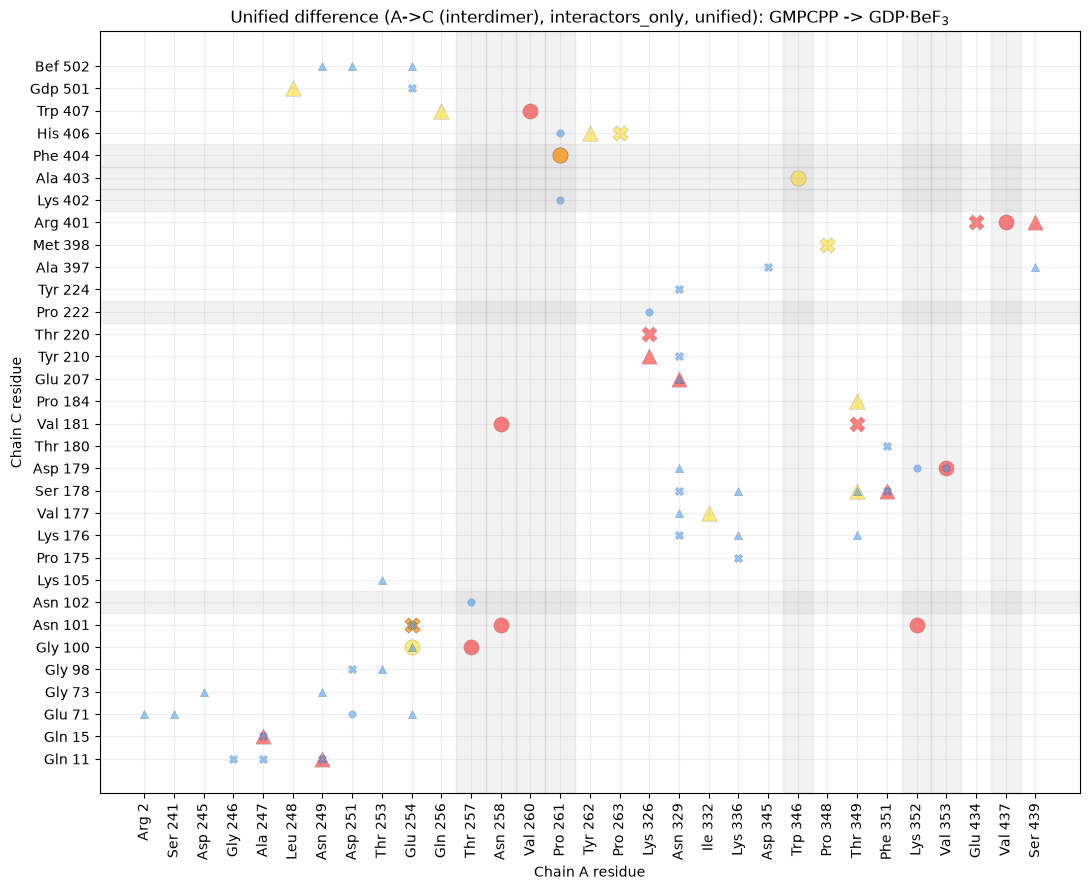

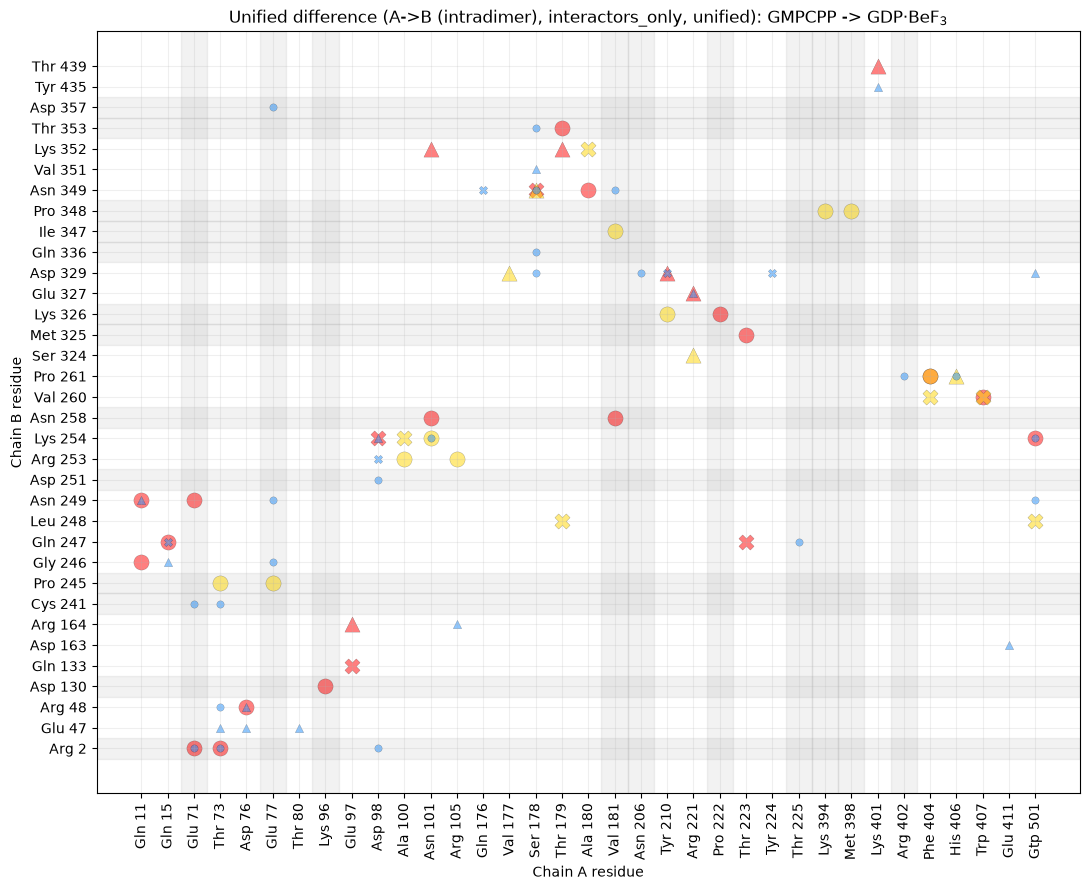

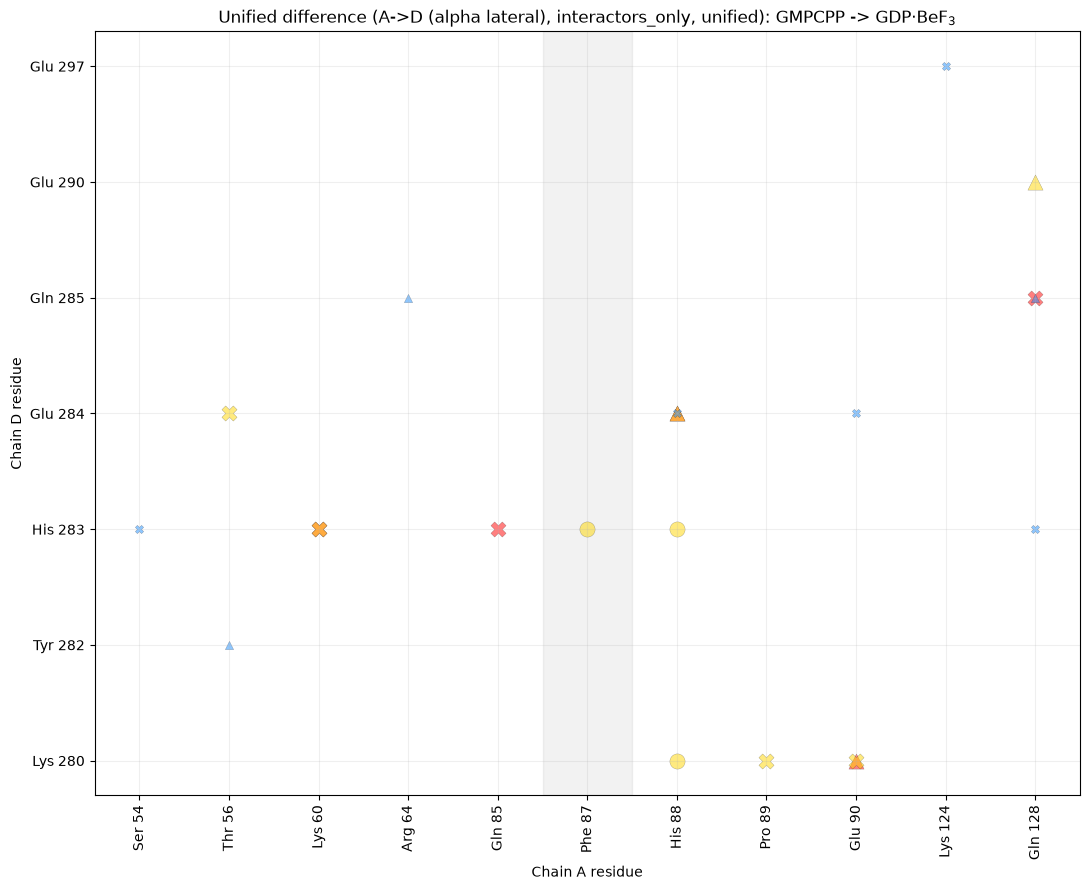

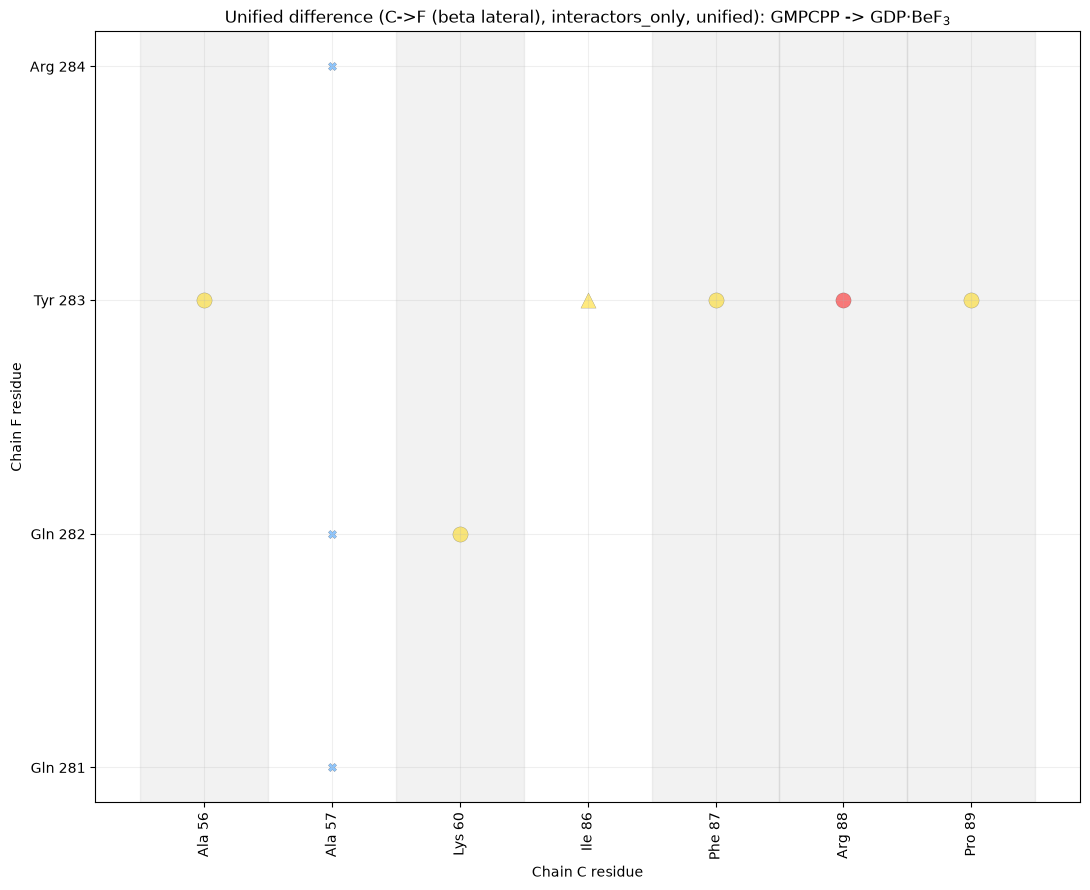

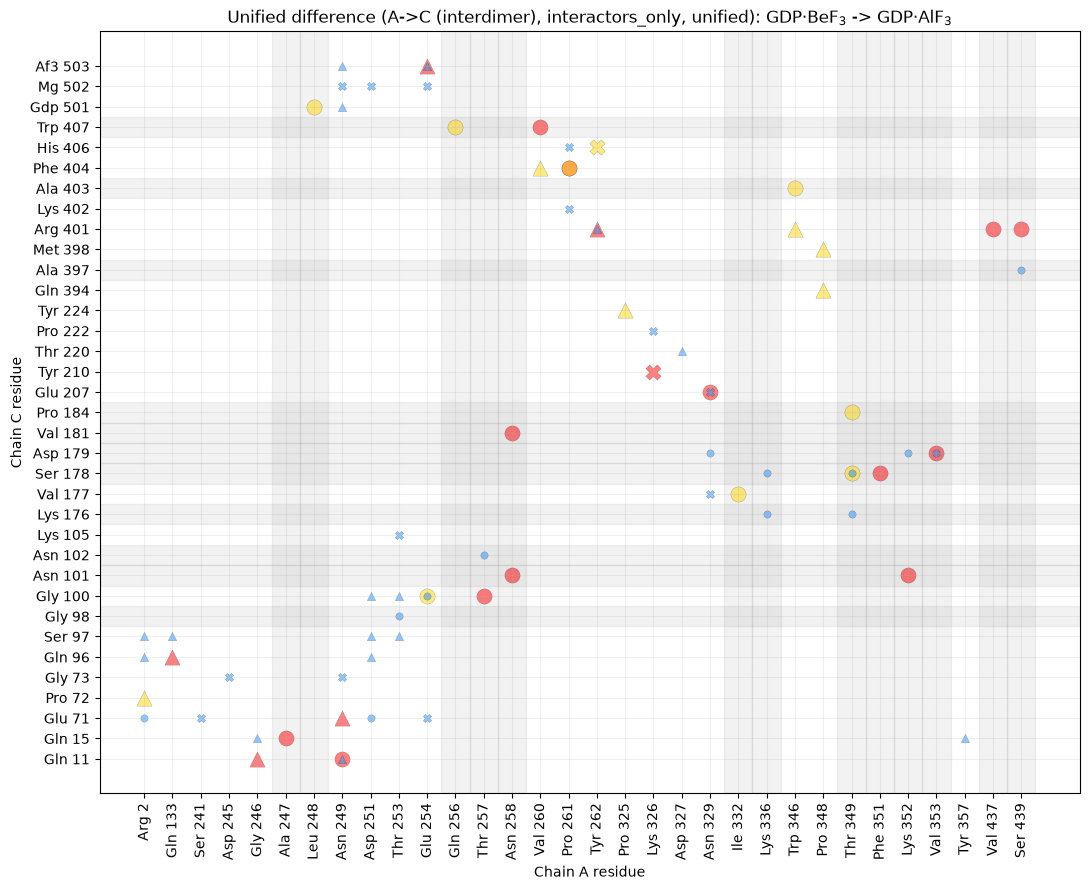

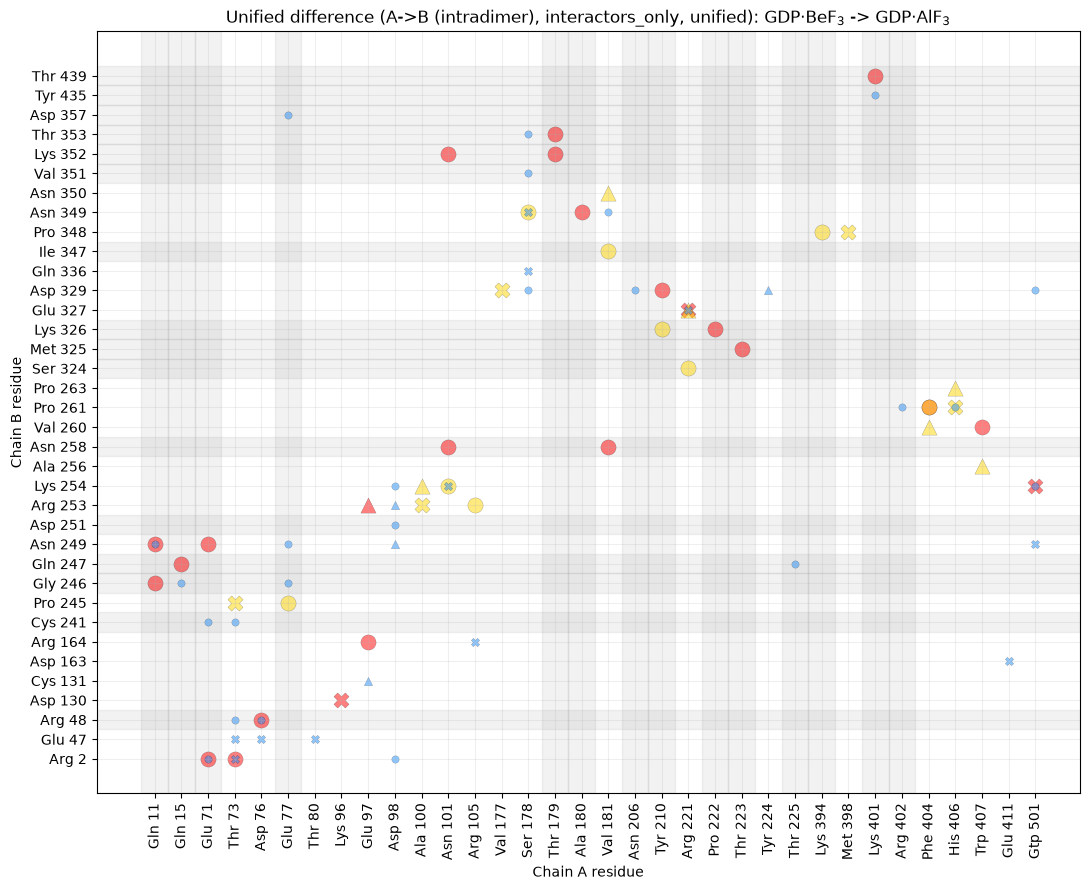

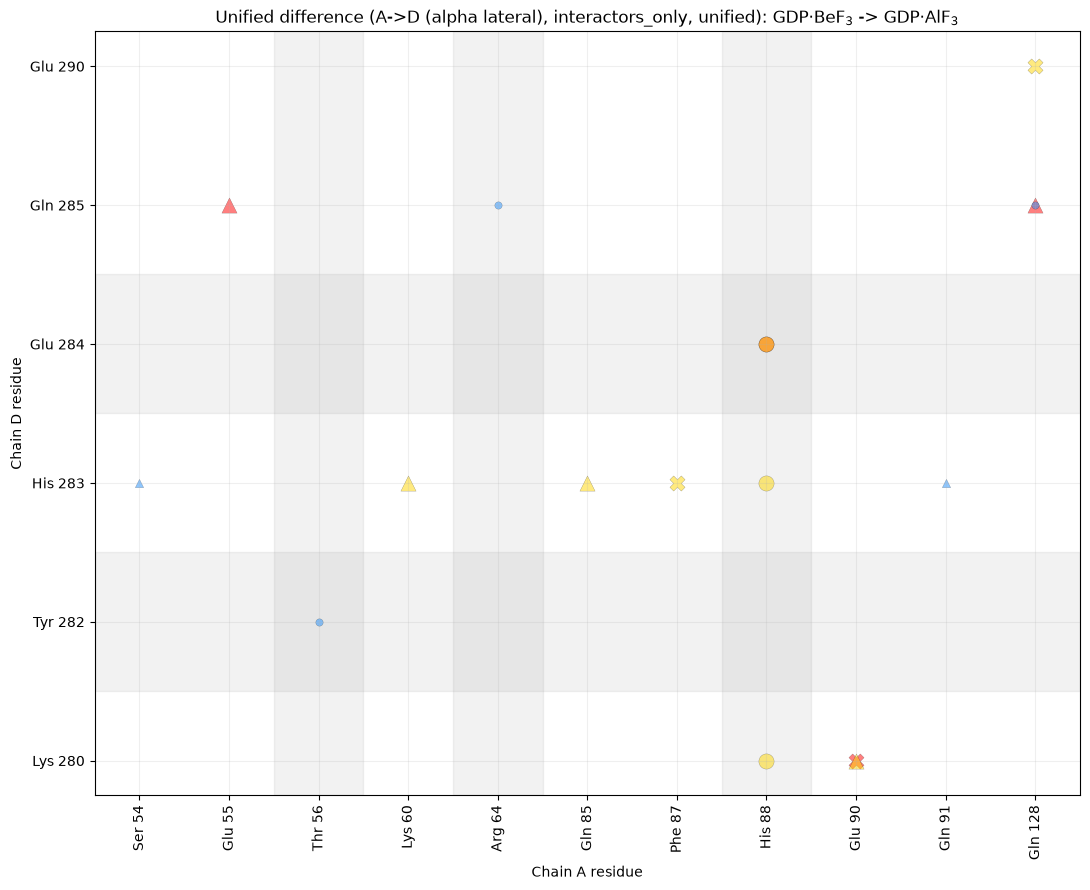

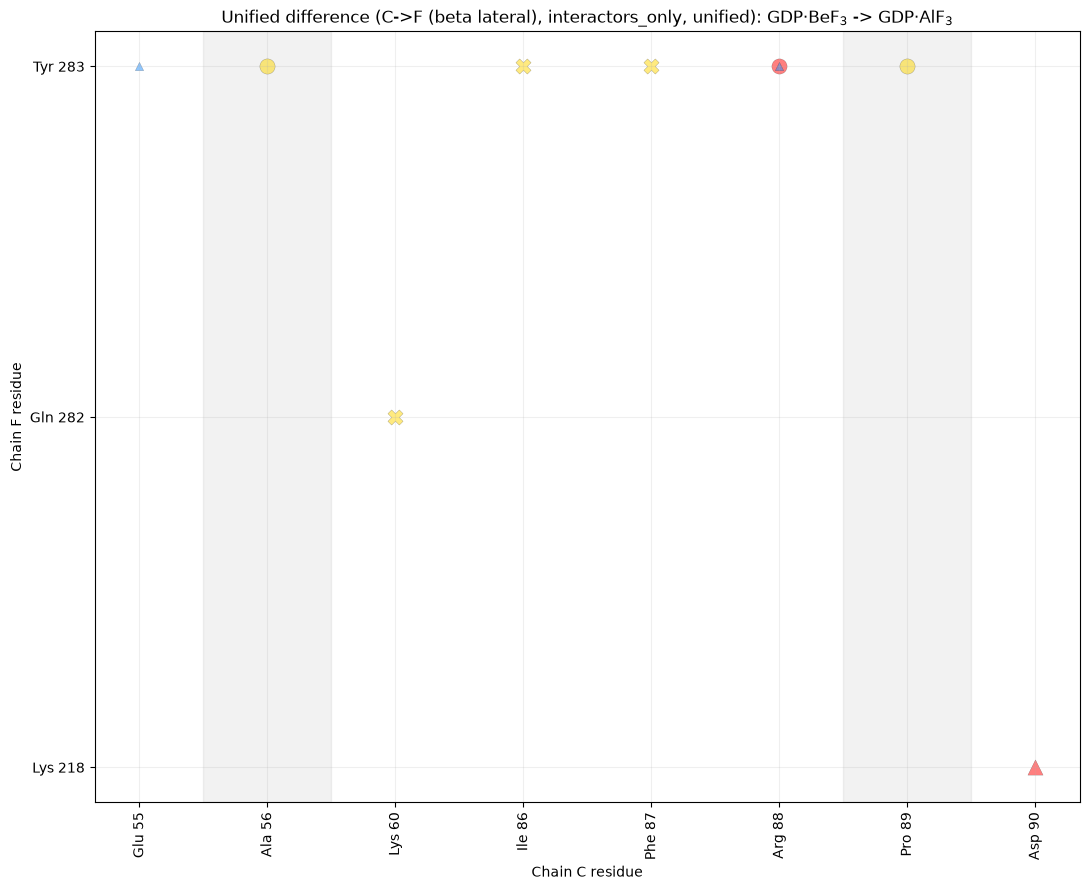

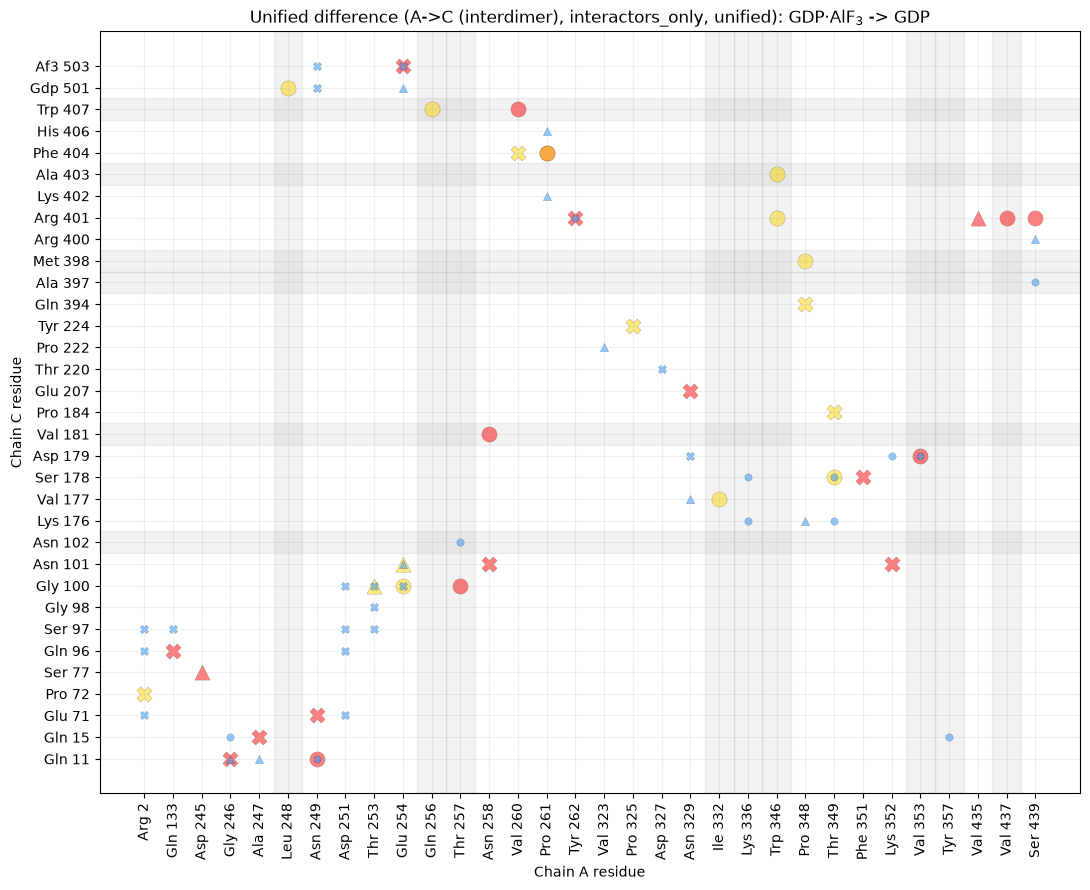

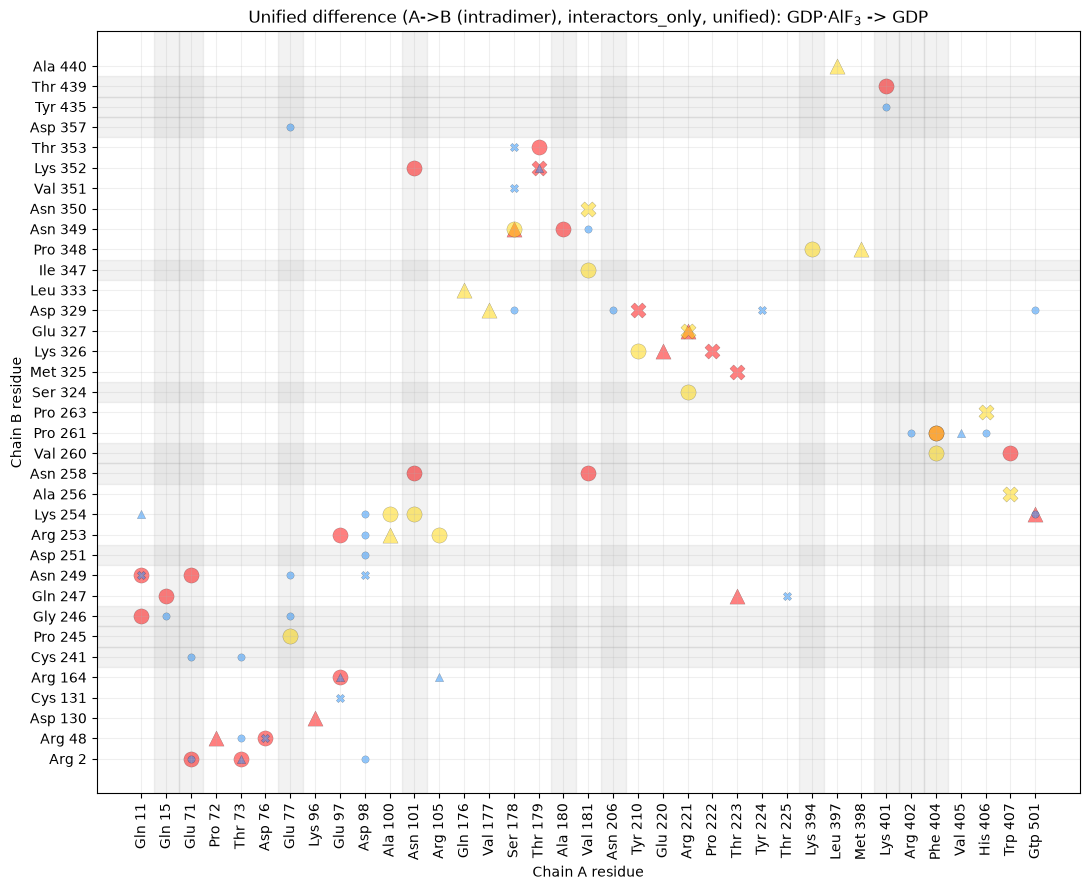

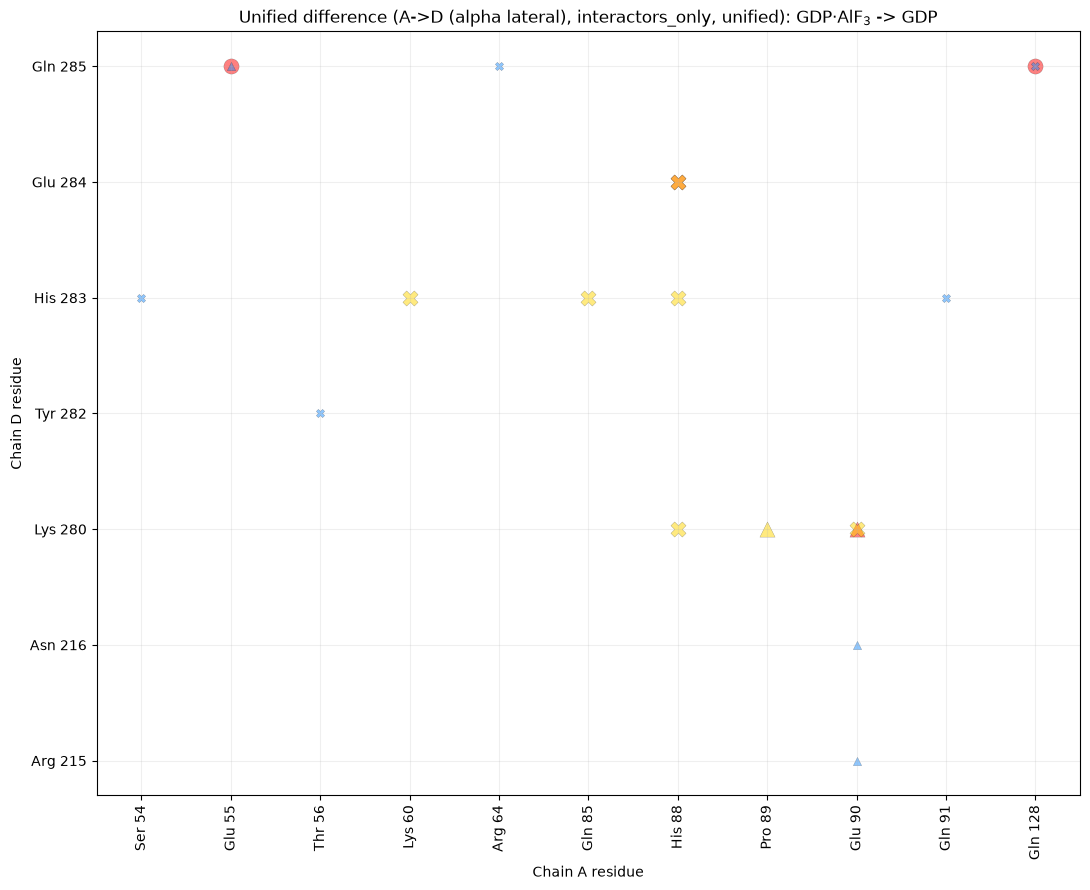

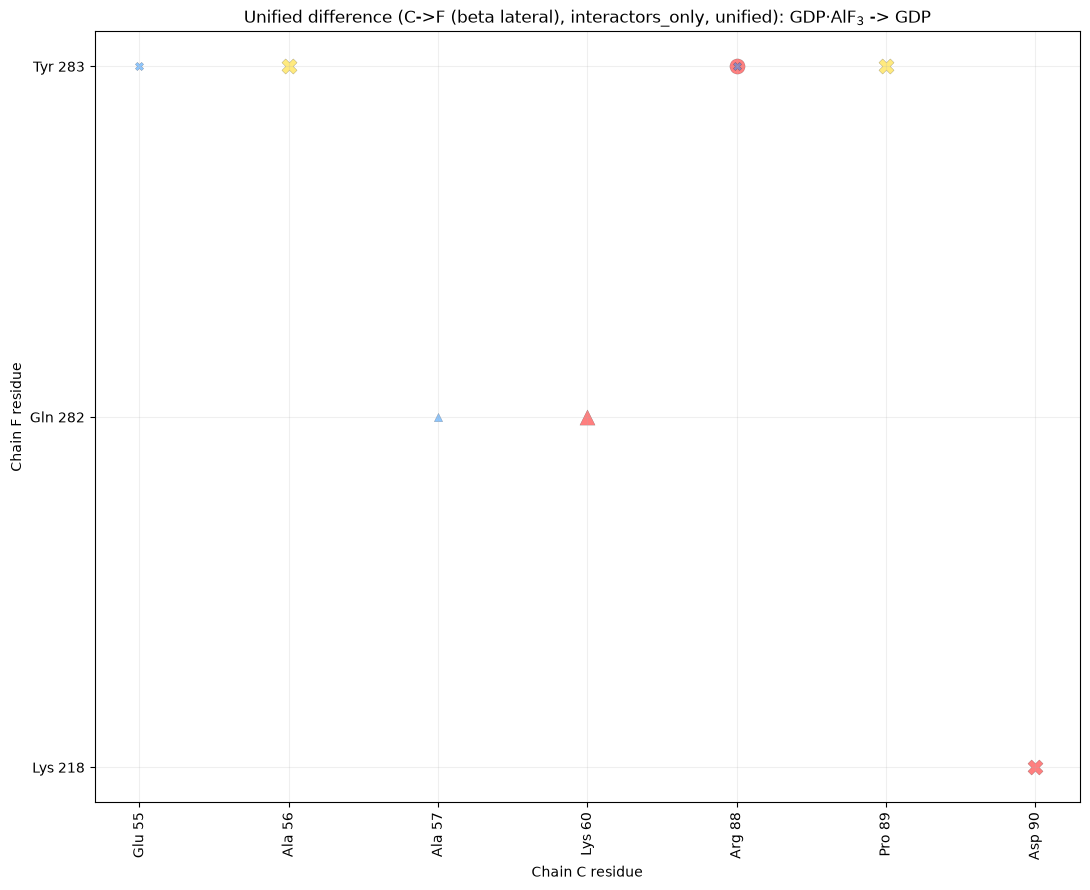

,model_a,model_b,model_a_display,model_b_display,interaction_mode,interface,saved_path,polar_conserved,polar_gained,polar_lost,non-polar_conserved,non-polar_gained,non-polar_lost,indirect_conserved,indirect_gained,indirect_lost
0,GMPCPP_13pf_6mer_fitted.pdb,BeF3_6mer_swapAtoms.pdb,GMPCPP,GDP$\cdot$BeF$_3$,unified,A->C (interdimer),contact_maps_differences/GMPCPP_13pf_6mer_fitt...,8,6,4,3,6,3,7,19,15
1,GMPCPP_13pf_6mer_fitted.pdb,BeF3_6mer_swapAtoms.pdb,GMPCPP,GDP$\cdot$BeF$_3$,unified,A->B (intradimer),contact_maps_differences/GMPCPP_13pf_6mer_fitt...,17,6,4,10,4,6,22,13,5
2,GMPCPP_13pf_6mer_fitted.pdb,BeF3_6mer_swapAtoms.pdb,GMPCPP,GDP$\cdot$BeF$_3$,unified,A->D (alpha lateral),contact_maps_differences/GMPCPP_13pf_6mer_fitt...,0,2,3,3,2,4,0,3,5
3,GMPCPP_13pf_6mer_fitted.pdb,BeF3_6mer_swapAtoms.pdb,GMPCPP,GDP$\cdot$BeF$_3$,unified,C->F (beta lateral),contact_maps_differences/GMPCPP_13pf_6mer_fitt...,1,0,0,4,1,0,0,0,3
4,BeF3_6mer_swapAtoms.pdb,AlF3_6mer_swapAtoms.pdb,GDP$\cdot$BeF$_3$,GDP$\cdot$AlF$_3$,unified,A->C (interdimer),contact_maps_differences/BeF3_6mer_swapAtoms_t...,13,5,1,8,6,1,13,16,13
5,BeF3_6mer_swapAtoms.pdb,AlF3_6mer_swapAtoms.pdb,GDP$\cdot$BeF$_3$,GDP$\cdot$AlF$_3$,unified,A->B (intradimer),contact_maps_differences/BeF3_6mer_swapAtoms_t...,20,1,3,9,6,5,24,4,11
6,BeF3_6mer_swapAtoms.pdb,AlF3_6mer_swapAtoms.pdb,GDP$\cdot$BeF$_3$,GDP$\cdot$AlF$_3$,unified,A->D (alpha lateral),contact_maps_differences/BeF3_6mer_swapAtoms_t...,1,2,1,3,3,2,3,2,0
7,BeF3_6mer_swapAtoms.pdb,AlF3_6mer_swapAtoms.pdb,GDP$\cdot$BeF$_3$,GDP$\cdot$AlF$_3$,unified,C->F (beta lateral),contact_maps_differences/BeF3_6mer_swapAtoms_t...,1,1,0,2,0,3,0,2,0
8,AlF3_6mer_swapAtoms.pdb,GDP_13pf_6mer_fitted.pdb,GDP$\cdot$AlF$_3$,GDP,unified,A->C (interdimer),contact_maps_differences/AlF3_6mer_swapAtoms_t...,8,2,10,9,2,5,12,10,17
9,AlF3_6mer_swapAtoms.pdb,GDP_13pf_6mer_fitted.pdb,GDP$\cdot$AlF$_3$,GDP,unified,A->B (intradimer),contact_maps_differences/AlF3_6mer_swapAtoms_t...,17,7,4,11,5,4,20,6,8


Saved unified difference figures in: /Users/filipc_p/Documents/work/PSI/Papers/GTP_cycle/ContactsAnalysis3/contact_maps_differences


In [5]:

UNIFIED_DIFF_OUT_DIR = Path("contact_maps_differences")
UNIFIED_DIFF_OUT_DIR.mkdir(exist_ok=True)
mpl.rcParams["path.simplify"] = True
mpl.rcParams["path.simplify_threshold"] = 0.5  # try 0.1–1.0; higher = simpler
mpl.rcParams["agg.path.chunksize"] = 10000
mpl.rcParams["svg.fonttype"] = "none"  

model_order = ['GMPCPP_13pf_6mer_fitted.pdb', 'BeF3_6mer_swapAtoms.pdb', 'AlF3_6mer_swapAtoms.pdb', 'GDP_13pf_6mer_fitted.pdb']

def _build_axis_mapping(residue_numbers, axis_style="interactors_only", gap_threshold=20, compressed_gap=5):
    values = sorted(set(int(v) for v in residue_numbers))
    if not values:
        return {}, []

    if axis_style == "all_residues":
        vmin, vmax = values[0], values[-1]
        full = list(range(vmin, vmax + 1))
        mapped = {v: v for v in full}
        return mapped, values

    if axis_style == "squashed_axes":
        mapped = {values[0]: values[0]}
        prev_orig = values[0]
        prev_map = values[0]
        for curr in values[1:]:
            delta = curr - prev_orig
            step = compressed_gap if delta > gap_threshold else delta
            prev_map += step
            mapped[curr] = prev_map
            prev_orig = curr
        return mapped, values

    if axis_style == "interactors_only":
        mapped = {v: i for i, v in enumerate(values)}
        return mapped, values

    raise ValueError("axis_style must be one of: 'all_residues', 'squashed_axes', 'interactors_only'")


def _choose_tick_labels(
    orig_values,
    mapped_dict,
    axis_style="interactors_only",
    gap_threshold=20,
    residue_name_map=None,
    include_residue_name=False,
):
    if not orig_values:
        return [], []

    vals = sorted(orig_values)

    if axis_style == "all_residues":
        vmin, vmax = vals[0], vals[-1]
        chosen = list(range(vmin, vmax + 1, 10))
        if vmin not in chosen:
            chosen = [vmin] + chosen
        if vmax not in chosen:
            chosen = chosen + [vmax]
        chosen = sorted(set(chosen))
    elif axis_style == "squashed_axes":
        stretches = []
        start = vals[0]
        prev = vals[0]
        for v in vals[1:]:
            if v - prev > gap_threshold:
                stretches.append((start, prev))
                start = v
            prev = v
        stretches.append((start, prev))

        chosen = []
        for s, e in stretches:
            ticks = list(range(s, e + 1, 5))
            if s not in ticks:
                ticks = [s] + ticks
            if e not in ticks:
                ticks = ticks + [e]
            chosen.extend(ticks)
        chosen = sorted(set(chosen))
    else:
        chosen = vals

    chosen = [v for v in chosen if v in mapped_dict]
    tick_pos = [mapped_dict[v] for v in chosen]

    if include_residue_name and residue_name_map is not None:
        tick_lab = [f"{residue_name_map[v]} {v}" if v in residue_name_map else str(v) for v in chosen]
    else:
        tick_lab = [str(v) for v in chosen]

    return tick_pos, tick_lab


MODEL_DISPLAY_ALIAS = {
    "BeF3_6mer_swapAtoms.pdb": r"GDP$\cdot$BeF$_3$",
    "AlF3_6mer_swapAtoms.pdb": r"GDP$\cdot$AlF$_3$",
    "GMPCPP_13pf_6mer_fitted.pdb": "GMPCPP",
    "GDP_13pf_6mer_fitted.pdb": "GDP",
}


def display_model_name(model_name):
    return MODEL_DISPLAY_ALIAS.get(model_name, model_name)


def _split_node(node):
    parts = str(node).split(":", 3)
    if len(parts) != 4:
        return None, None, None, None
    return parts[0], parts[1], parts[2], parts[3]


def _collect_unified_points_for_interface(df_model_edges, chain_x, chain_y, interaction_mode="unified"):
    valid_modes = {"unified", "contacts-only", "hbonds-only"}
    if interaction_mode not in valid_modes:
        raise ValueError(f"interaction_mode must be one of {valid_modes}")

    points = {"polar": set(), "non-polar": set(), "indirect": set()}
    include_contacts = interaction_mode in {"unified", "contacts-only"}
    include_hbonds = interaction_mode in {"unified", "hbonds-only"}

    for _, r in df_model_edges.iterrows():
        c1, res1, rn1, _ = _split_node(r["node1"])
        c2, res2, rn2, _ = _split_node(r["node2"])
        if None in {c1, res1, rn1, c2, res2, rn2}:
            continue
        if {c1, c2} != {chain_x, chain_y}:
            continue
        if res1 == "HOH" or res2 == "HOH":
            continue

        pair = (int(rn1), int(rn2)) if c1 == chain_x else (int(rn2), int(rn1))
        src = r.get("interaction_source", None)
        cat = r.get("interaction_category", None)

        if include_hbonds and src == "hbonds":
            points["polar"].add(pair)
        elif include_contacts and src == "contacts" and cat in {"hydrophobic"}:
            #elif include_contacts and src == "contacts" and cat in {"hydrophobic", "other"}:
            points["non-polar"].add(pair)

    water_to_x = defaultdict(set)
    water_to_y = defaultdict(set)

    for _, r in df_model_edges.iterrows():
        src = r.get("interaction_source", None)
        #if src == "contacts" and not include_contacts:
        if src == "contacts": #here' take water only from Hbonds
            continue
        if src == "hbonds" and not include_hbonds:
            continue

        c1, res1, rn1, _ = _split_node(r["node1"])
        c2, res2, rn2, _ = _split_node(r["node2"])
        if None in {c1, res1, rn1, c2, res2, rn2}:
            continue

        if res1 == "HOH":
            w = f"{c1}:{rn1}"
            if c2 == chain_x and res2 != "HOH":
                water_to_x[w].add(int(rn2))
            if c2 == chain_y and res2 != "HOH":
                water_to_y[w].add(int(rn2))

        if res2 == "HOH":
            w = f"{c2}:{rn2}"
            if c1 == chain_x and res1 != "HOH":
                water_to_x[w].add(int(rn1))
            if c1 == chain_y and res1 != "HOH":
                water_to_y[w].add(int(rn1))

    for w in set(water_to_x.keys()) & set(water_to_y.keys()):
        for rx in water_to_x[w]:
            for ry in water_to_y[w]:
                points["indirect"].add((rx, ry))

    return points


def _merge_points(*points_dicts):
    merged = {"polar": set(), "non-polar": set(), "indirect": set()}
    for pdict in points_dicts:
        for k in merged:
            merged[k] |= pdict[k]
    return merged


def _union_axis_maps_unified(points_a, points_b):
    x_vals, y_vals = set(), set()
    for k in ["polar", "non-polar", "indirect"]:
        for x, y in (points_a[k] | points_b[k]):
            x_vals.add(int(x))
            y_vals.add(int(y))
    x_map, x_orig = _build_axis_mapping(x_vals, axis_style="interactors_only")
    y_map, y_orig = _build_axis_mapping(y_vals, axis_style="interactors_only")
    return x_map, x_orig, y_map, y_orig


def _residue_name_map_from_contacts(df_contacts_model, chain):
    out = {}
    for _, r in df_contacts_model.iterrows():
        if r["atom1_chain"] == chain and r["atom1_residue"] != "HOH":
            out[int(r["atom1_residue_number"])] = str(r["atom1_residue"]).capitalize()
        if r["atom2_chain"] == chain and r["atom2_residue"] != "HOH":
            out[int(r["atom2_residue_number"])] = str(r["atom2_residue"]).capitalize()
    return out


def save_separate_legend(handles, labels, path, ncol=1, fontsize=8):
    fig_legend = plt.figure(figsize=(2.5 * ncol, 1.3 + 0.45 * (len(labels) // ncol)))
    fig_legend.legend(handles, labels, loc="center", ncol=ncol, fontsize=fontsize, frameon=True)
    plt.axis("off")
    plt.tight_layout()
    fig_legend.savefig(path, dpi=220, bbox_inches="tight")
    plt.close(fig_legend)


def _plot_unified_pair_difference(
    df_edges_a,
    df_edges_b,
    df_contacts_a,
    df_contacts_b,
    model_a,
    model_b,
    interface_pairs,
    interface_label,
    out_dir=None,
    interaction_mode="unified",
):
    pts_a_parts = [_collect_unified_points_for_interface(df_edges_a, cx, cy, interaction_mode=interaction_mode) for cx, cy in interface_pairs]
    pts_b_parts = [_collect_unified_points_for_interface(df_edges_b, cx, cy, interaction_mode=interaction_mode) for cx, cy in interface_pairs]
    pts_a = _merge_points(*pts_a_parts)
    pts_b = _merge_points(*pts_b_parts)

    primary_x, primary_y = interface_pairs[0]
    x_map, x_orig, y_map, y_orig = _union_axis_maps_unified(pts_a, pts_b)

    x_resname = _residue_name_map_from_contacts(pd.concat([df_contacts_a, df_contacts_b], ignore_index=True), primary_x)
    y_resname = _residue_name_map_from_contacts(pd.concat([df_contacts_a, df_contacts_b], ignore_index=True), primary_y)

    plt.figure(figsize=(11, 9))

    model_a_disp = display_model_name(model_a)
    model_b_disp = display_model_name(model_b)

    cats = ["polar", "non-polar", "indirect"]
    union_typed = set()
    conserved_typed = set()
    for cat in cats:
        union_typed |= {(cat, p[0], p[1]) for p in (pts_a[cat] | pts_b[cat])}
        conserved_typed |= {(cat, p[0], p[1]) for p in (pts_a[cat] & pts_b[cat])}

    ax = plt.gca()
    row_all_conserved, col_all_conserved = set(), set()
    for x in sorted({x for (_cat, x, _y) in union_typed}):
        row_events = {e for e in union_typed if e[1] == x}
        if row_events and row_events.issubset(conserved_typed):
            row_all_conserved.add(x)
    for y in sorted({y for (_cat, _x, y) in union_typed}):
        col_events = {e for e in union_typed if e[2] == y}
        if col_events and col_events.issubset(conserved_typed):
            col_all_conserved.add(y)

    used_axis_label = False
    for x in sorted(row_all_conserved):
        if x in x_map:
            xv = x_map[x]
            ax.axvspan(xv - 0.5, xv + 0.5, color="grey", alpha=0.10, zorder=0,
                       label="all interactions conserved" if not used_axis_label else None)
            used_axis_label = True
    for y in sorted(col_all_conserved):
        if y in y_map:
            yv = y_map[y]
            ax.axhspan(yv - 0.5, yv + 0.5, color="grey", alpha=0.10, zorder=0,
                       label="all interactions conserved" if not used_axis_label else None)
            used_axis_label = True

    cat_style = {"polar": "red", "non-polar": "gold", "indirect": "dodgerblue"}

    for cat in cats:
        conserved = pts_a[cat] & pts_b[cat]
        gained = pts_b[cat] - pts_a[cat]
        lost = pts_a[cat] - pts_b[cat]

        def _scatter(points, marker, size, alpha, label):
            if not points:
                return
            valid = [p for p in sorted(points) if p[0] in x_map and p[1] in y_map]
            if not valid:
                return
            xx = [x_map[p[0]] for p in valid]
            yy = [y_map[p[1]] for p in valid]
            plt.scatter(xx, yy, c=cat_style[cat], marker=marker, s=size, alpha=alpha,
                        edgecolors="k", linewidths=0.2, label=label)

        _scatter(conserved, "o", 120 if cat != "indirect" else 28, 0.5, f"{cat} conserved")
        _scatter(gained, "^", 120 if cat != "indirect" else 36, 0.5, f"{cat} gained in {model_b_disp}")
        _scatter(lost, "X", 120 if cat != "indirect" else 36, 0.5, f"{cat} lost from {model_a_disp}")

    xt, xl = _choose_tick_labels(x_orig, x_map, axis_style="interactors_only", residue_name_map=x_resname, include_residue_name=True)
    yt, yl = _choose_tick_labels(y_orig, y_map, axis_style="interactors_only", residue_name_map=y_resname, include_residue_name=True)
    if xt:
        plt.xticks(xt, xl, rotation=90)
    if yt:
        plt.yticks(yt, yl)

    plt.xlabel(f"Chain {primary_x} residue")
    plt.ylabel(f"Chain {primary_y} residue")
    plt.title(f"Unified difference ({interface_label}, interactors_only, {interaction_mode}): {model_a_disp} -> {model_b_disp}")
    plt.grid(alpha=0.2)

    handles, labels = plt.gca().get_legend_handles_labels()
    seen, uh, ul = set(), [], []
    for h, l in zip(handles, labels):
        if l not in seen:
            seen.add(l)
            uh.append(h)
            ul.append(l)

    saved_path = None
    if out_dir is not None:
        safe_a = model_a.replace(".pdb", "").replace("/", "_")
        safe_b = model_b.replace(".pdb", "").replace("/", "_")
        mode_tag = interaction_mode.replace("-", "_")
        iface_tag = interface_label.replace(" ", "_").replace("+", "plus").replace("->", "to")
        legend_path = Path(out_dir) / f"diff_unified_{mode_tag}_{safe_a}_to_{safe_b}_{iface_tag}_legend.png"
        save_separate_legend(uh, ul, legend_path, ncol=1, fontsize=8)

        plt.tight_layout()
        saved_path = Path(out_dir) / f"{safe_a}_to_{safe_b}_{iface_tag}.svg"
        plt.savefig(
            saved_path,
            format="svg",
            bbox_inches="tight",
            facecolor="white",
            edgecolor="none",
            metadata=None,
        )
    plt.show()
    plt.close()

    return {
        "model_a": model_a,
        "model_b": model_b,
        "model_a_display": model_a_disp,
        "model_b_display": model_b_disp,
        "interaction_mode": interaction_mode,
        "interface": interface_label,
        "saved_path": str(saved_path) if saved_path else None,
        "polar_conserved": len(pts_a["polar"] & pts_b["polar"]),
        "polar_gained": len(pts_b["polar"] - pts_a["polar"]),
        "polar_lost": len(pts_a["polar"] - pts_b["polar"]),
        "non-polar_conserved": len(pts_a["non-polar"] & pts_b["non-polar"]),
        "non-polar_gained": len(pts_b["non-polar"] - pts_a["non-polar"]),
        "non-polar_lost": len(pts_a["non-polar"] - pts_b["non-polar"]),
        "indirect_conserved": len(pts_a["indirect"] & pts_b["indirect"]),
        "indirect_gained": len(pts_b["indirect"] - pts_a["indirect"]),
        "indirect_lost": len(pts_a["indirect"] - pts_b["indirect"]),
    }


if "unified_edges_df" not in globals():
    raise RuntimeError("unified_edges_df is not defined. Run the unified-edge construction cell first.")



interaction_modes = ["unified"] #, "contacts-only", "hbonds-only"]
interface_specs = [
    {"label": "A->C (interdimer)", "pairs": [("A", "C")]},
    {"label": "A->B (intradimer)", "pairs": [("A", "B")]},
    {"label": "A->D (alpha lateral)", "pairs": [("A", "D")]},
    {"label": "C->F (beta lateral)", "pairs": [("C", "F")]},
]

pair_summaries_unified = []
for mode in interaction_modes:
    for i in range(len(model_order) - 1):
        a = model_order[i]
        b = model_order[i + 1]

        edges_a = unified_edges_df[unified_edges_df["source_pdb"] == a].copy()
        edges_b = unified_edges_df[unified_edges_df["source_pdb"] == b].copy()

        contacts_a = contacts_df[contacts_df["source_pdb"] == a].copy()
        contacts_b = contacts_df[contacts_df["source_pdb"] == b].copy()

        for spec in interface_specs:
            pair_summaries_unified.append(
                _plot_unified_pair_difference(
                    edges_a,
                    edges_b,
                    contacts_a,
                    contacts_b,
                    a,
                    b,
                    interface_pairs=spec["pairs"],
                    interface_label=spec["label"],
                    out_dir=UNIFIED_DIFF_OUT_DIR,
                    interaction_mode=mode,
                )
            )

pairwise_diff_summary_unified = pd.DataFrame(pair_summaries_unified)
display(pairwise_diff_summary_unified)
print(f"Saved unified difference figures in: {UNIFIED_DIFF_OUT_DIR.resolve()}")

In [6]:
pairwise_diff_summary_unified.to_csv("pairwise_diff_summary_unified.csv")

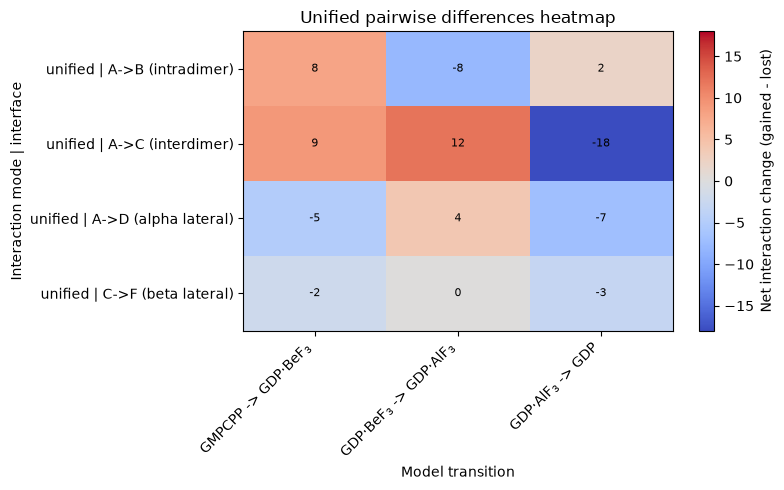

,interaction_mode,interface,transition,net_change,total_abs_change,polar_gained,polar_lost,non-polar_gained,non-polar_lost,indirect_gained,indirect_lost
9,unified,A->B (intradimer),GDP$\cdot$AlF$_3$ -> GDP,2,34,7,4,5,4,6,8
5,unified,A->B (intradimer),GDP$\cdot$BeF$_3$ -> GDP$\cdot$AlF$_3$,-8,30,1,3,6,5,4,11
1,unified,A->B (intradimer),GMPCPP -> GDP$\cdot$BeF$_3$,8,38,6,4,4,6,13,5
8,unified,A->C (interdimer),GDP$\cdot$AlF$_3$ -> GDP,-18,46,2,10,2,5,10,17
4,unified,A->C (interdimer),GDP$\cdot$BeF$_3$ -> GDP$\cdot$AlF$_3$,12,42,5,1,6,1,16,13
0,unified,A->C (interdimer),GMPCPP -> GDP$\cdot$BeF$_3$,9,53,6,4,6,3,19,15
10,unified,A->D (alpha lateral),GDP$\cdot$AlF$_3$ -> GDP,-7,17,1,1,1,6,3,5
6,unified,A->D (alpha lateral),GDP$\cdot$BeF$_3$ -> GDP$\cdot$AlF$_3$,4,10,2,1,3,2,2,0
2,unified,A->D (alpha lateral),GMPCPP -> GDP$\cdot$BeF$_3$,-5,19,2,3,2,4,3,5
11,unified,C->F (beta lateral),GDP$\cdot$AlF$_3$ -> GDP,-3,7,1,1,0,2,1,2


In [7]:
# Heatmap summary of pairwise unified differences
# Metric shown: total net change = (gained - lost) across polar/non-polar/indirect.

if "pairwise_diff_summary_unified" not in globals() or pairwise_diff_summary_unified.empty:
    raise RuntimeError("pairwise_diff_summary_unified is empty/undefined. Run the unified pairwise-difference cell first.")

hm = pairwise_diff_summary_unified.copy()

hm["transition"] = hm["model_a_display"].astype(str) + " -> " + hm["model_b_display"].astype(str)
hm["net_change"] = (
    (hm["polar_gained"] - hm["polar_lost"])
    + (hm["non-polar_gained"] - hm["non-polar_lost"])
    + (hm["indirect_gained"] - hm["indirect_lost"])
)
hm["total_abs_change"] = (
    hm["polar_gained"] + hm["polar_lost"]
    + hm["non-polar_gained"] + hm["non-polar_lost"]
    + hm["indirect_gained"] + hm["indirect_lost"]
)

hm["row"] = hm["interaction_mode"].astype(str) + " | " + hm["interface"].astype(str)

heat = (
    hm.pivot_table(
        index="row",
        columns="transition",
        values="net_change",
        aggfunc="sum",
        fill_value=0,
    )
    .sort_index()
)

# X-axis: same transition order as pairwise maps (pivot sorts columns lexicographically by default)
if "model_order" in globals() and "display_model_name" in globals():
    _transition_order = [
        f"{display_model_name(model_order[i])} -> {display_model_name(model_order[i + 1])}"
        for i in range(len(model_order) - 1)
    ]
    _present = list(heat.columns)
    _ordered = [t for t in _transition_order if t in _present] + [t for t in _present if t not in _transition_order]
    heat = heat.reindex(columns=_ordered, fill_value=0)

plt.figure(figsize=(max(8, 1.6 * len(heat.columns)), max(5, 0.55 * len(heat.index))))
max_abs = float(heat.abs().to_numpy().max()) if heat.size else 1.0
if max_abs == 0:
    max_abs = 1.0

im = plt.imshow(heat.values, aspect="auto", cmap="coolwarm", vmin=-max_abs, vmax=max_abs)
plt.colorbar(im, label="Net interaction change (gained - lost)")

plt.xticks(range(len(heat.columns)), heat.columns, rotation=45, ha="right")
plt.yticks(range(len(heat.index)), heat.index)

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = int(heat.iat[i, j])
        plt.text(j, i, f"{v}", ha="center", va="center", fontsize=8, color="black")

plt.title("Unified pairwise differences heatmap")
plt.xlabel("Model transition")
plt.ylabel("Interaction mode | interface")
plt.tight_layout()
plt.savefig("unified_pairwise_differences_heatmap_waterFromHbondsOnly.png")
plt.show()

display(
    hm[[
        "interaction_mode", "interface", "transition",
        "net_change", "total_abs_change",
        "polar_gained", "polar_lost",
        "non-polar_gained", "non-polar_lost",
        "indirect_gained", "indirect_lost",
    ]].sort_values(["interaction_mode", "interface", "transition"])
)


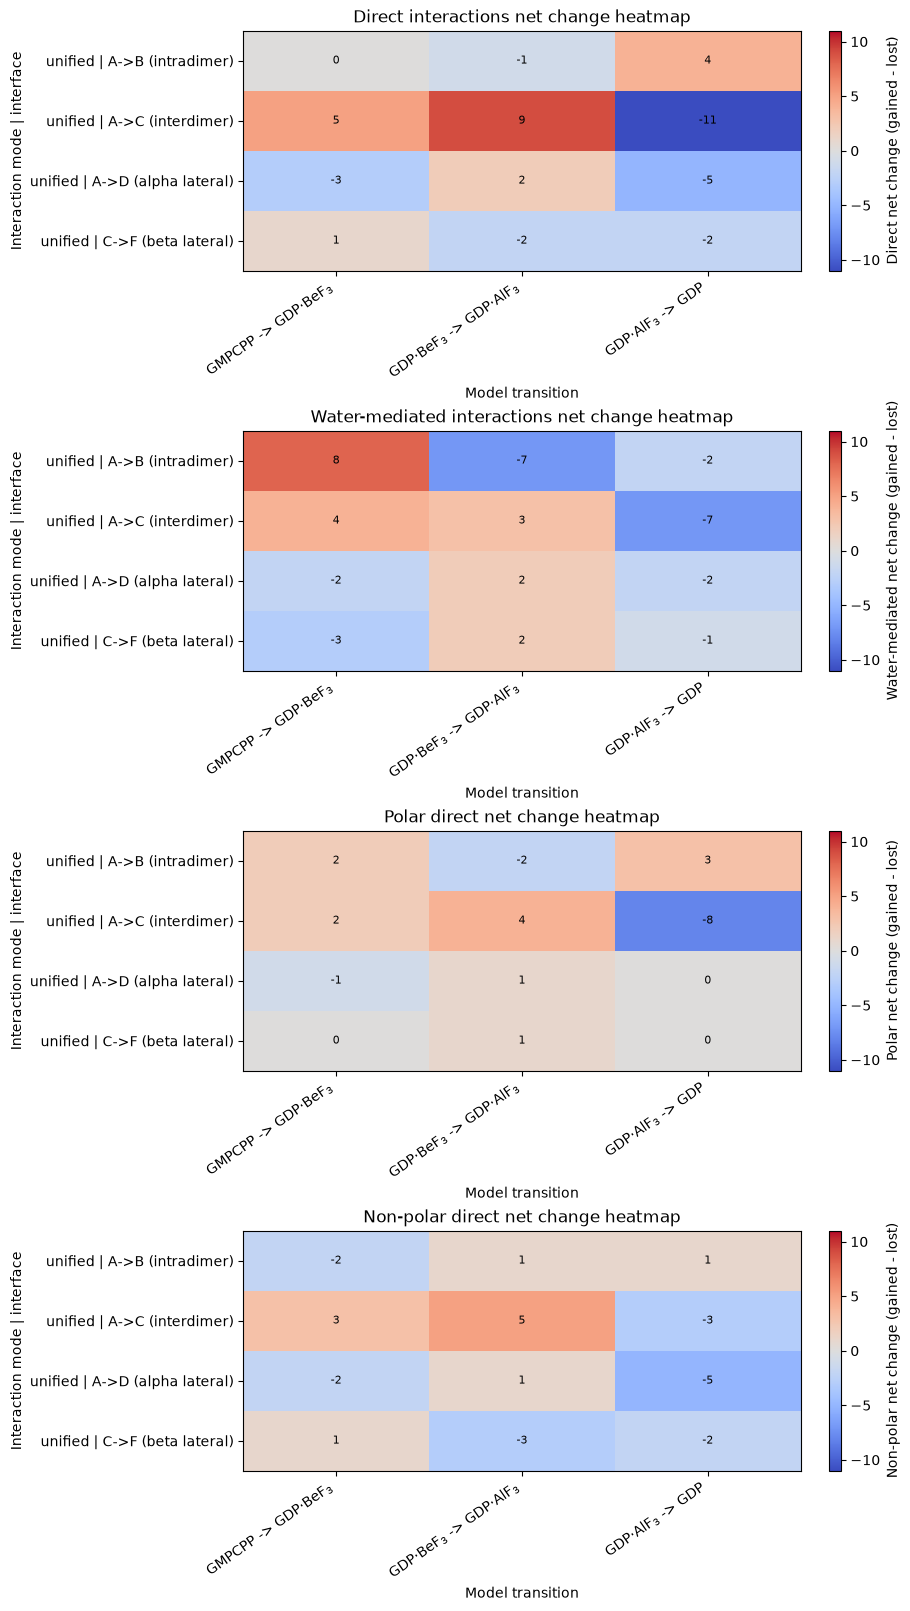

,interaction_mode,interface,transition,polar_net_change,non_polar_net_change,direct_net_change,water_net_change,total_net_change
1,unified,A->B (intradimer),GMPCPP -> GDP$\cdot$BeF$_3$,2,-2,0,8,8
5,unified,A->B (intradimer),GDP$\cdot$BeF$_3$ -> GDP$\cdot$AlF$_3$,-2,1,-1,-7,-8
9,unified,A->B (intradimer),GDP$\cdot$AlF$_3$ -> GDP,3,1,4,-2,2
0,unified,A->C (interdimer),GMPCPP -> GDP$\cdot$BeF$_3$,2,3,5,4,9
4,unified,A->C (interdimer),GDP$\cdot$BeF$_3$ -> GDP$\cdot$AlF$_3$,4,5,9,3,12
8,unified,A->C (interdimer),GDP$\cdot$AlF$_3$ -> GDP,-8,-3,-11,-7,-18
2,unified,A->D (alpha lateral),GMPCPP -> GDP$\cdot$BeF$_3$,-1,-2,-3,-2,-5
6,unified,A->D (alpha lateral),GDP$\cdot$BeF$_3$ -> GDP$\cdot$AlF$_3$,1,1,2,2,4
10,unified,A->D (alpha lateral),GDP$\cdot$AlF$_3$ -> GDP,0,-5,-5,-2,-7
3,unified,C->F (beta lateral),GMPCPP -> GDP$\cdot$BeF$_3$,0,1,1,-3,-2


In [8]:
# Updated heatmaps with requested transition order
# X-axis order: GMPCPP -> BeF, BeF -> Al, Al -> GDP
# Panels:
#   1) Direct interactions net change (polar + non-polar)
#   2) Water-mediated interactions net change (indirect)
#   3) Polar direct net change
#   4) Non-polar direct net change

if "pairwise_diff_summary_unified" not in globals() or pairwise_diff_summary_unified.empty:
    raise RuntimeError("pairwise_diff_summary_unified is empty/undefined. Run the unified pairwise-difference cell first.")

hm = pairwise_diff_summary_unified.copy()
hm["transition"] = hm["model_a_display"].astype(str) + " -> " + hm["model_b_display"].astype(str)


def _transition_rank(t):
    s = str(t).lower()
    if "gmpcpp" in s and "bef" in s:
        return 0
    if "bef" in s and "alf" in s:
        return 1
    if "alf" in s and "gdp" in s:
        return 2
    return 99


transition_order = sorted(hm["transition"].dropna().unique().tolist(), key=_transition_rank)

hm["polar_net_change"] = hm["polar_gained"] - hm["polar_lost"]
hm["non_polar_net_change"] = hm["non-polar_gained"] - hm["non-polar_lost"]
hm["direct_net_change"] = hm["polar_net_change"] + hm["non_polar_net_change"]
hm["water_net_change"] = hm["indirect_gained"] - hm["indirect_lost"]
hm["total_net_change"] = hm["direct_net_change"] + hm["water_net_change"]
hm["row"] = hm["interaction_mode"].astype(str) + " | " + hm["interface"].astype(str)

heat_direct = (
    hm.pivot_table(
        index="row",
        columns="transition",
        values="direct_net_change",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(columns=transition_order)
    .sort_index()
)

heat_water = (
    hm.pivot_table(
        index="row",
        columns="transition",
        values="water_net_change",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(columns=transition_order)
    .sort_index()
)

heat_polar = (
    hm.pivot_table(
        index="row",
        columns="transition",
        values="polar_net_change",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(columns=transition_order)
    .sort_index()
)

heat_nonpolar = (
    hm.pivot_table(
        index="row",
        columns="transition",
        values="non_polar_net_change",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(columns=transition_order)
    .sort_index()
)

shared_max = max(
    float(heat_direct.abs().to_numpy().max()) if heat_direct.size else 0.0,
    float(heat_water.abs().to_numpy().max()) if heat_water.size else 0.0,
    float(heat_polar.abs().to_numpy().max()) if heat_polar.size else 0.0,
    float(heat_nonpolar.abs().to_numpy().max()) if heat_nonpolar.size else 0.0,
)
if shared_max == 0:
    shared_max = 1.0

fig, axes = plt.subplots(
    4,
    1,
    figsize=(
        max(9, 1.8 * len(transition_order)),
        max(16, 0.45 * len(heat_direct.index) * 4 + 8),
    ),
    constrained_layout=True,
)

for ax, heat, title, cbar_label in [
    (axes[0], heat_direct, "Direct interactions net change heatmap", "Direct net change (gained - lost)"),
    (axes[1], heat_water, "Water-mediated interactions net change heatmap", "Water-mediated net change (gained - lost)"),
    (axes[2], heat_polar, "Polar direct net change heatmap", "Polar net change (gained - lost)"),
    (axes[3], heat_nonpolar, "Non-polar direct net change heatmap", "Non-polar net change (gained - lost)"),
]:
    im = ax.imshow(heat.values, aspect="auto", cmap="coolwarm", vmin=-shared_max, vmax=shared_max)
    fig.colorbar(im, ax=ax, label=cbar_label)

    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)

    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            ax.text(j, i, f"{int(heat.iat[i, j])}", ha="center", va="center", fontsize=8, color="black")

    ax.set_title(title)
    ax.set_xlabel("Model transition")
    ax.set_ylabel("Interaction mode | interface")
os.makedirs("heatmaps", exist_ok=True)
plt.savefig("heatmaps/summary_heatmap.svg", format="svg")
plt.show()

display(
    hm[[
        "interaction_mode",
        "interface",
        "transition",
        "polar_net_change",
        "non_polar_net_change",
        "direct_net_change",
        "water_net_change",
        "total_net_change",
    ]].sort_values(
        ["interaction_mode", "interface", "transition"],
        key=lambda s: s.map(_transition_rank) if s.name == "transition" else s,
    )
)

In [9]:
# Annotate unified edges with tubulin secondary-structure elements per residue.
# Residues outside named ranges are labeled as flanking loops, e.g. "S9-S10 loop".



alpha_ss_path = Path("alpha-tubulinSS.txt")
beta_ss_path = Path("beta-tubulinSS.txt")


def _load_ss_ranges(path):
    rows = []
    with open(path, "r", encoding="utf-8") as fh:
        for raw in fh:
            line = raw.strip()
            if not line or line.startswith("Name"):
                continue
            parts = line.split()
            if len(parts) < 3:
                continue
            name = parts[0]
            start = int(parts[1])
            end = int(parts[2])
            if start > end:
                start, end = end, start
            rows.append((name, start, end))
    rows.sort(key=lambda x: x[1])
    return rows


def _label_residue_ss(resnum, ss_ranges):
    if resnum is None:
        return None

    for name, start, end in ss_ranges:
        if start <= resnum <= end:  # ranges include edges
            return name

    # Outside named ranges: build flanking-loop label
    prev_el = None
    next_el = None
    for name, start, end in ss_ranges:
        if end < resnum:
            prev_el = name
        elif start > resnum and next_el is None:
            next_el = name
            break

    if prev_el is None and next_el is not None:
        return f"before {next_el}"
    if next_el is None and prev_el is not None:
        return f"after {prev_el}"
    if prev_el is not None and next_el is not None:
        return f"{prev_el}-{next_el} loop"
    return "unassigned"


def _parse_node(node):
    # Expected format: CHAIN:RES:RESNUM:ATOM
    parts = str(node).split(":", 3)
    if len(parts) != 4:
        return None, None, None, None
    chain, residue, resnum, atom = parts
    try:
        resnum = int(resnum)
    except ValueError:
        resnum = None
    return chain, residue, resnum, atom


# Adjust this mapping if your chain<->subunit assignment differs.
CHAIN_TO_SUBUNIT = {
    "A": "alpha", "D": "alpha", 
    "E": "beta", "B": "beta", "C": "beta", "F": "beta",
}

NUCLEOTIDE_RESNAMES = {"GDP", "GTP", "G2P", "BEF", "AF3", "MG"}

alpha_ss_ranges = _load_ss_ranges(alpha_ss_path)
beta_ss_ranges = _load_ss_ranges(beta_ss_path)


def _node_ss_label(node):
    chain, residue, resnum, _ = _parse_node(node)
    if chain is None:
        return None
    if residue == "HOH":
        return "water"
    if residue in NUCLEOTIDE_RESNAMES:
        return "nucleotide"

    subunit = CHAIN_TO_SUBUNIT.get(chain)
    if subunit == "alpha":
        return _label_residue_ss(resnum, alpha_ss_ranges)
    if subunit == "beta":
        return _label_residue_ss(resnum, beta_ss_ranges)
    return "unknown_chain"


if "unified_edges_df" not in globals():
    raise RuntimeError("unified_edges_df is not defined. Run the unified-edge construction cells first.")

unified_edges_df = unified_edges_df.copy()
unified_edges_df["node1_ss"] = unified_edges_df["node1"].map(_node_ss_label)
unified_edges_df["node2_ss"] = unified_edges_df["node2"].map(_node_ss_label)
unified_edges_df["edge_ss"] = unified_edges_df["node1_ss"].astype(str) + " <-> " + unified_edges_df["node2_ss"].astype(str)

display(unified_edges_df[["node1", "node1_ss", "node2", "node2_ss", "edge_ss"]].head(20))
print("Added columns: node1_ss, node2_ss, edge_ss")

,node1,node1_ss,node2,node2_ss,edge_ss
0,X:HOH:410:O,water,W:HOH:364:O,water,water <-> water
1,O:HOH:1:O,water,F:AF3:503:AL01,nucleotide,water <-> nucleotide
2,N:HOH:1:O,water,C:AF3:503:AL01,nucleotide,water <-> nucleotide
3,F:AF3:503:AL01,nucleotide,F:GDP:501:O2B,nucleotide,nucleotide <-> nucleotide
4,C:AF3:503:AL01,nucleotide,C:GDP:501:O2B,nucleotide,nucleotide <-> nucleotide
5,D:HIS:283:CE1,S7-H9 loop,A:LYS:60:NZ,H1-S2 loop,S7-H9 loop <-> H1-S2 loop
6,D:HIS:283:CE1,S7-H9 loop,A:LYS:60:HZ1,H1-S2 loop,S7-H9 loop <-> H1-S2 loop
7,X:HOH:680:O,water,B:ALA:57:O,H1'-S2 loop,water <-> H1'-S2 loop
8,D:HIS:283:CE1,S7-H9 loop,A:LYS:60:HZ3,H1-S2 loop,S7-H9 loop <-> H1-S2 loop
9,A:LYS:60:NZ,H1-S2 loop,D:HIS:283:ND1,S7-H9 loop,H1-S2 loop <-> S7-H9 loop


Added columns: node1_ss, node2_ss, edge_ss


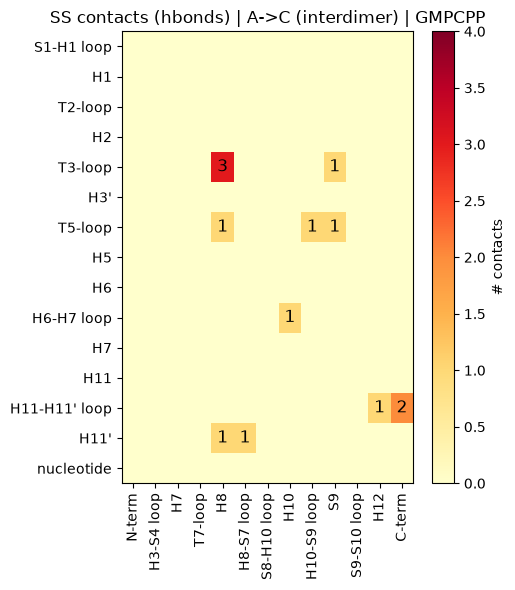

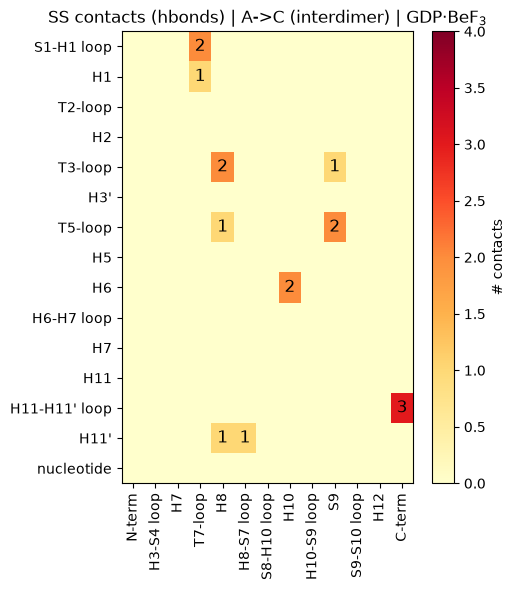

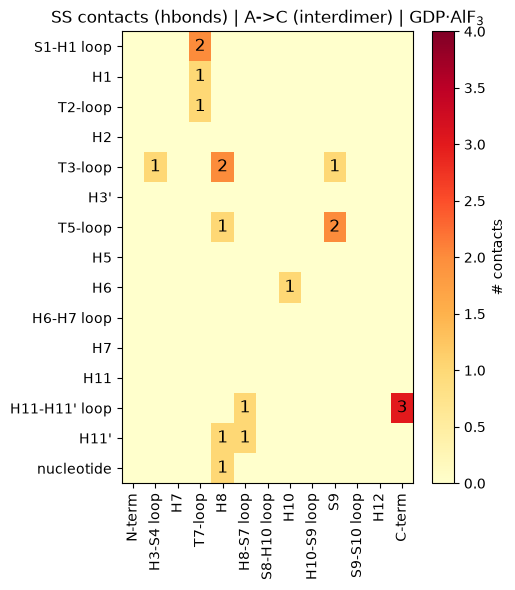

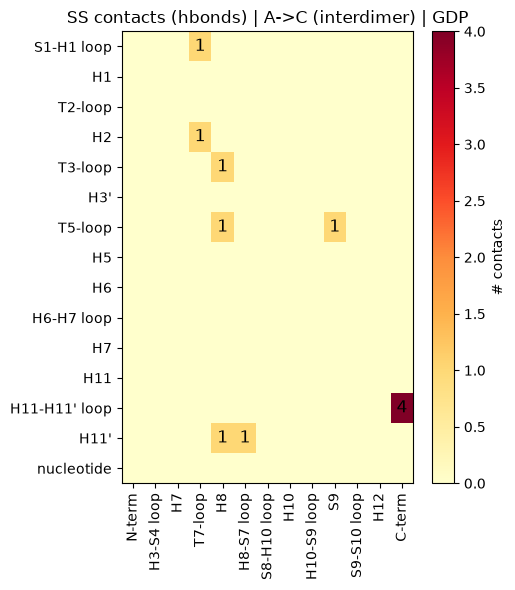

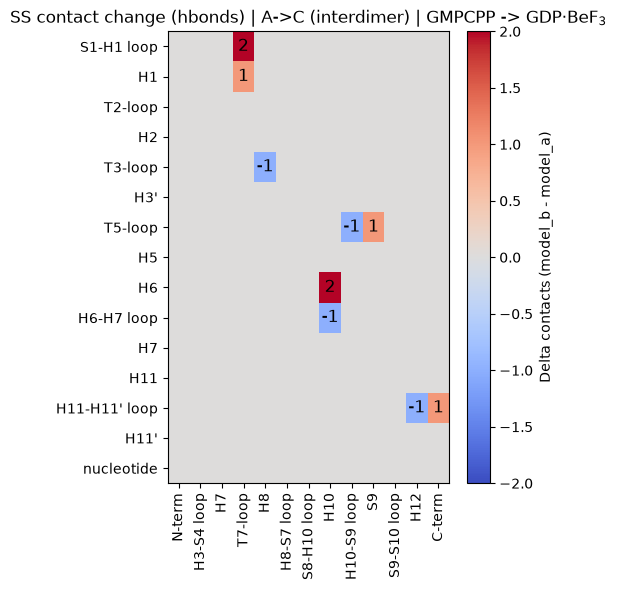

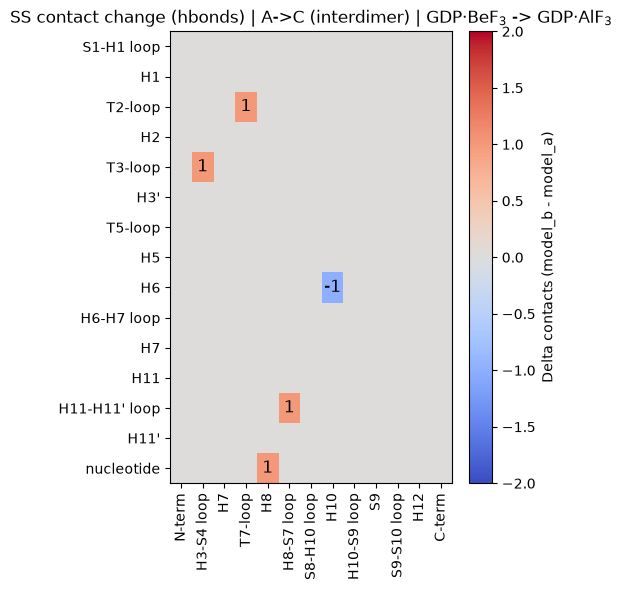

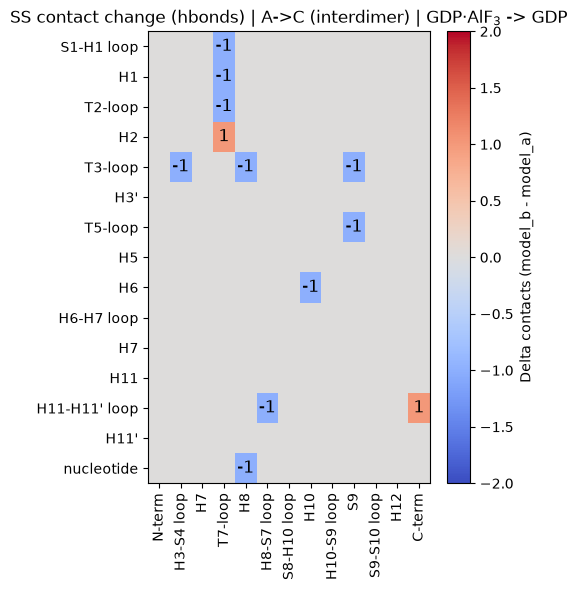

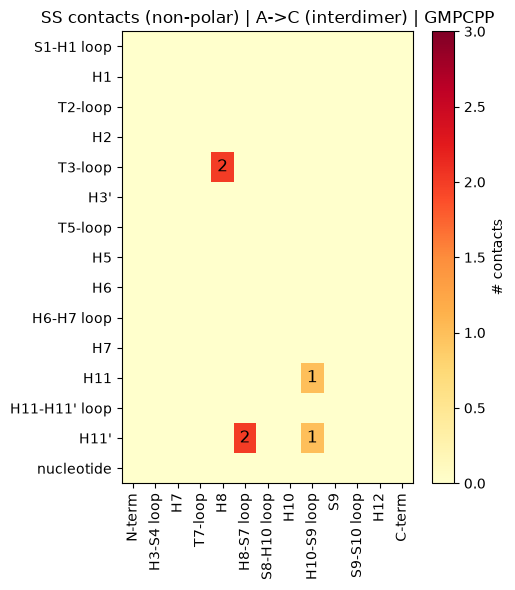

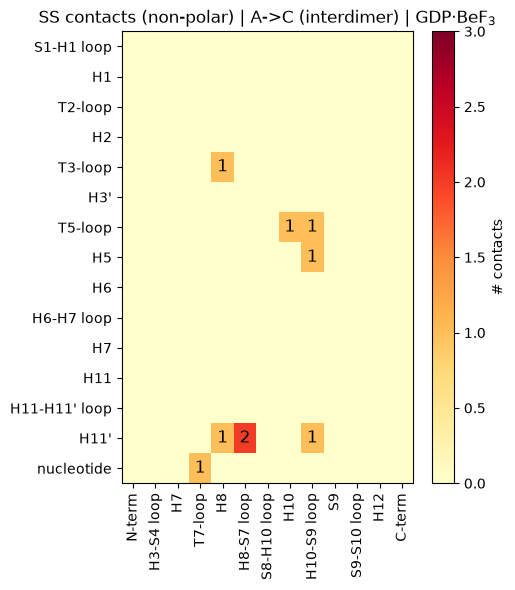

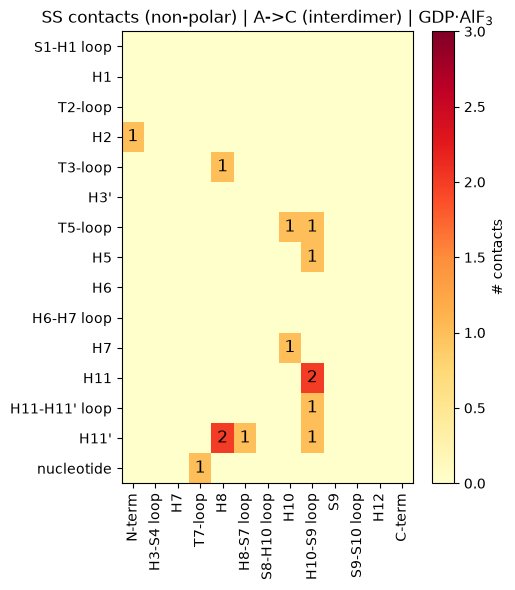

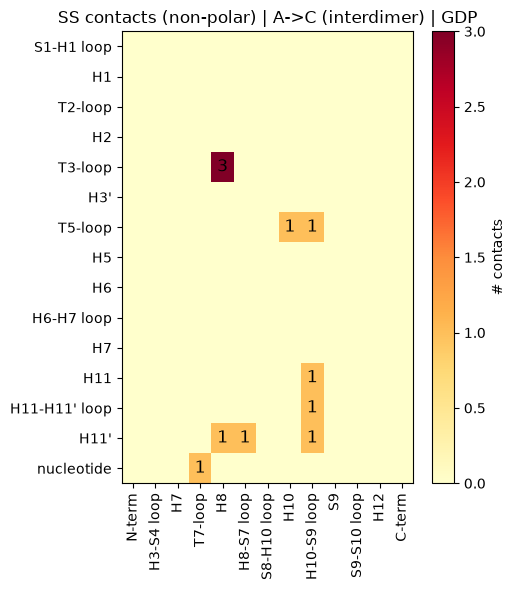

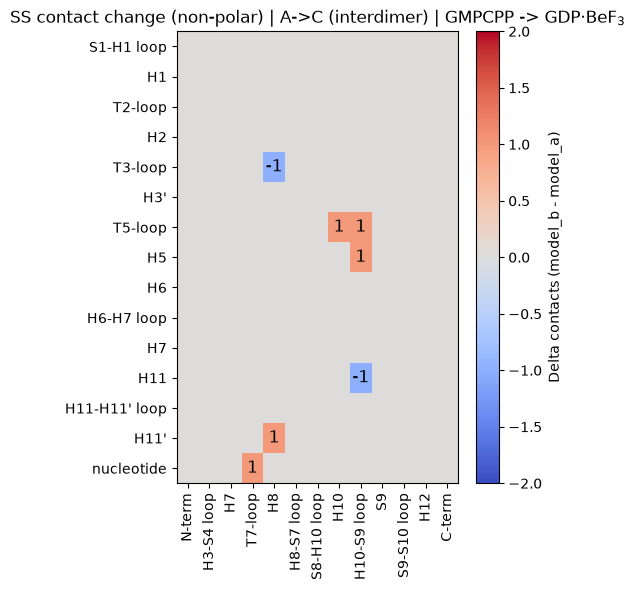

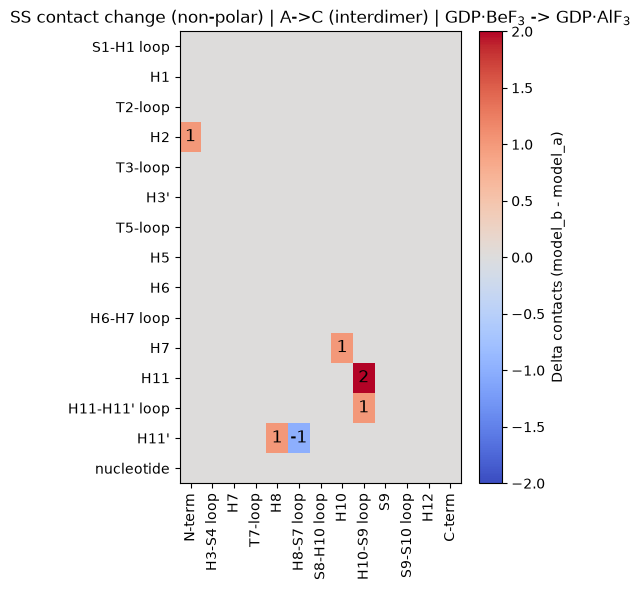

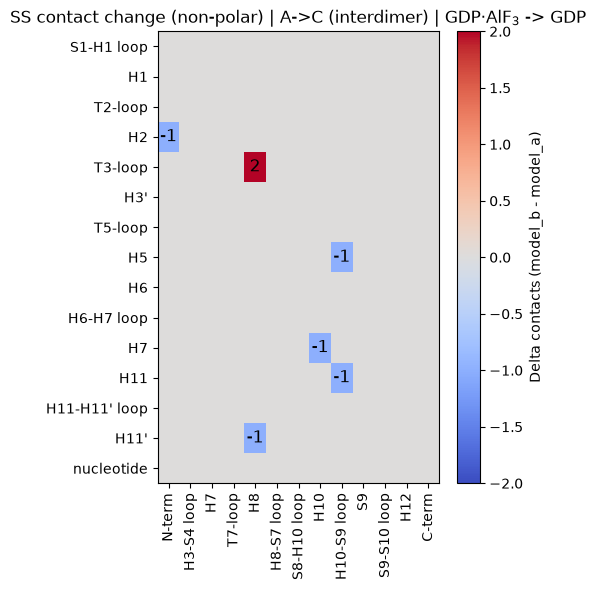

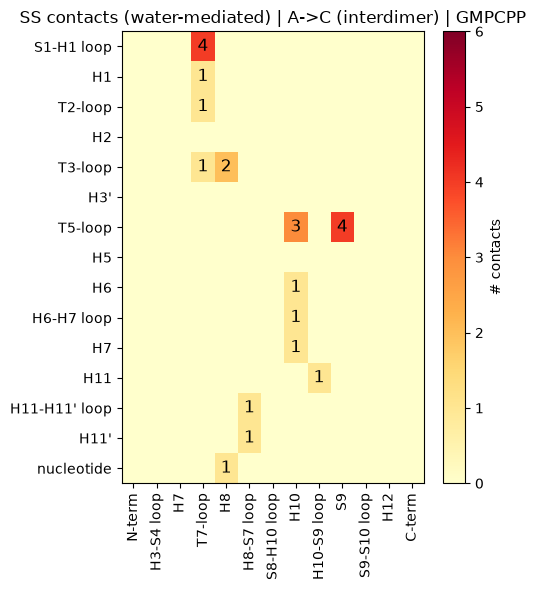

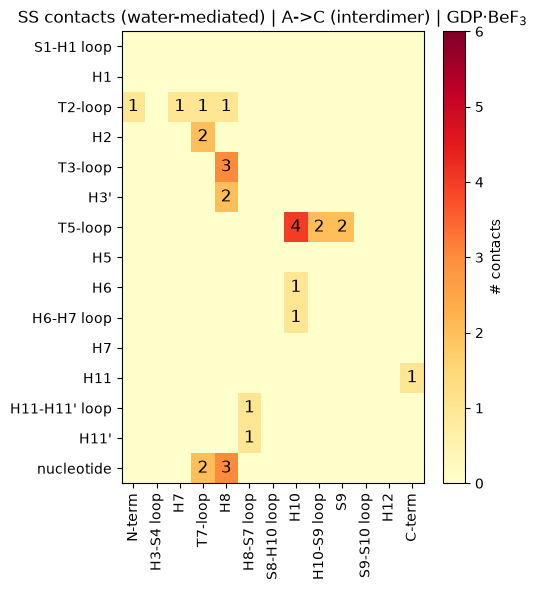

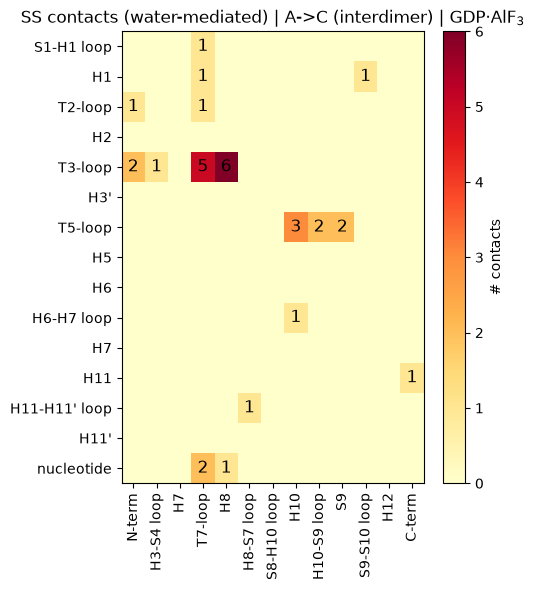

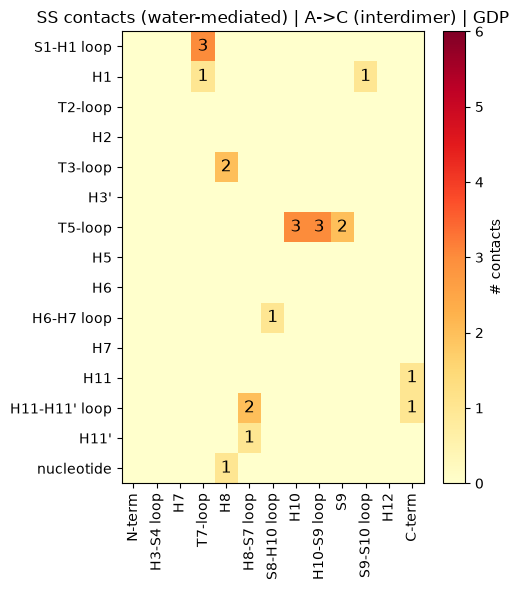

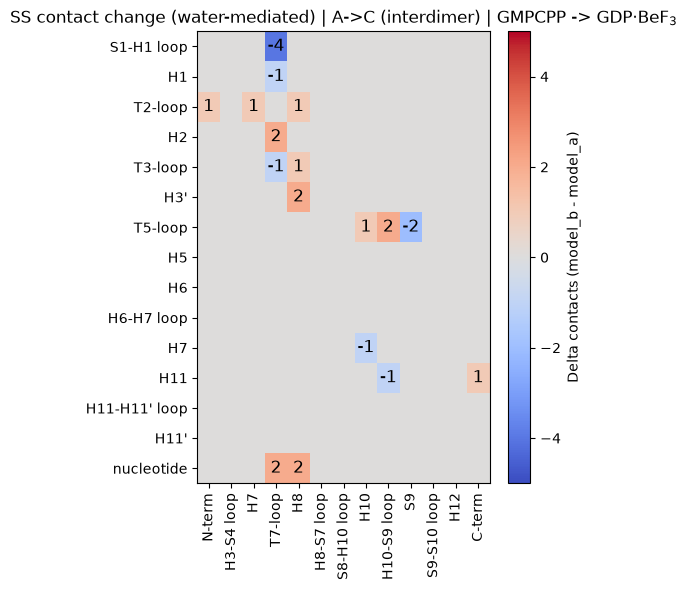

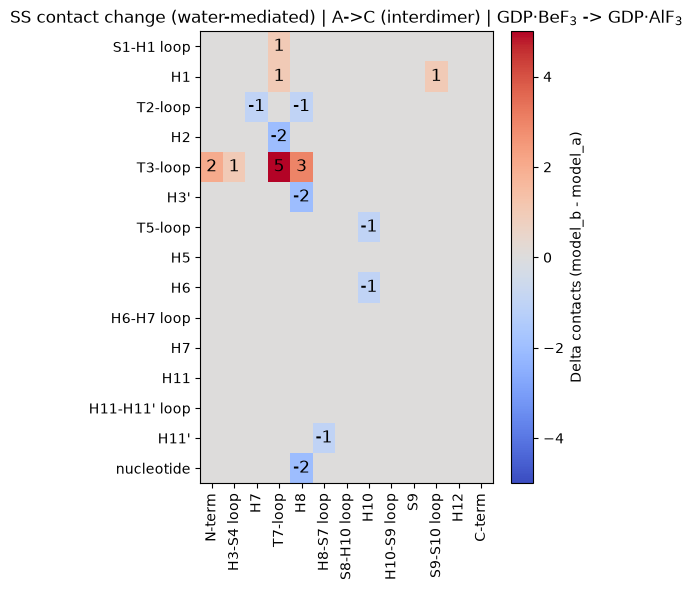

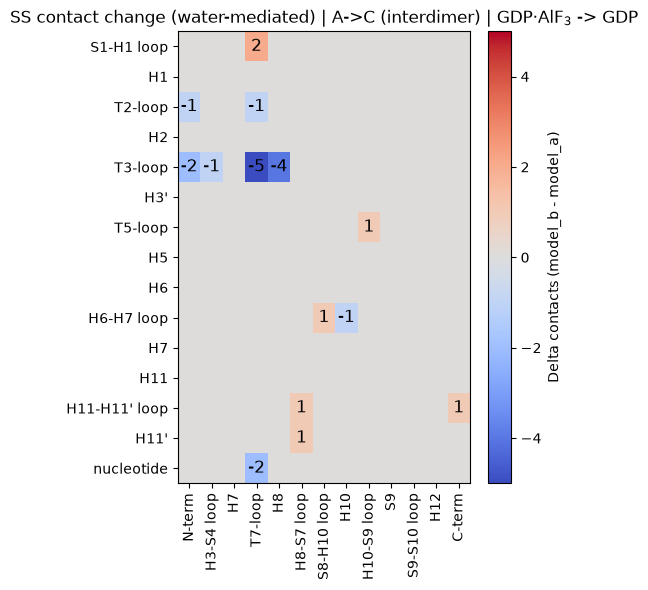

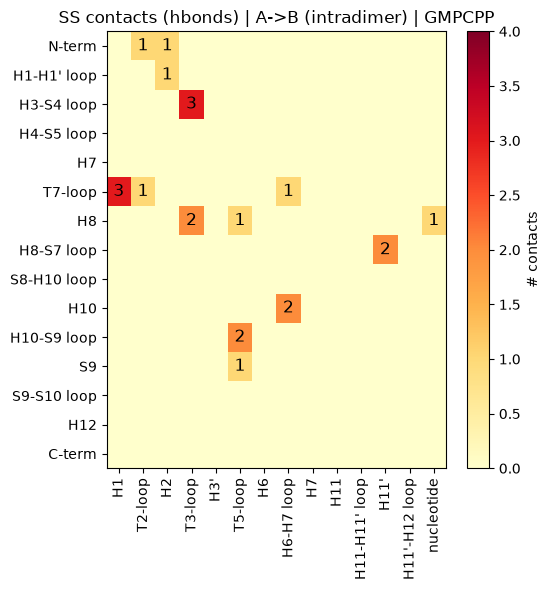

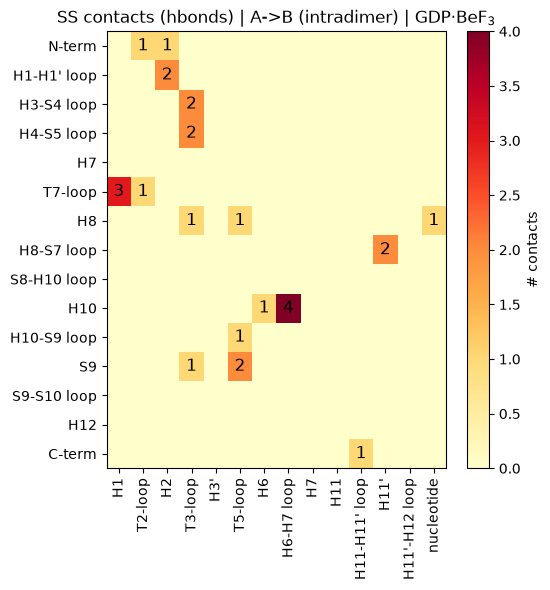

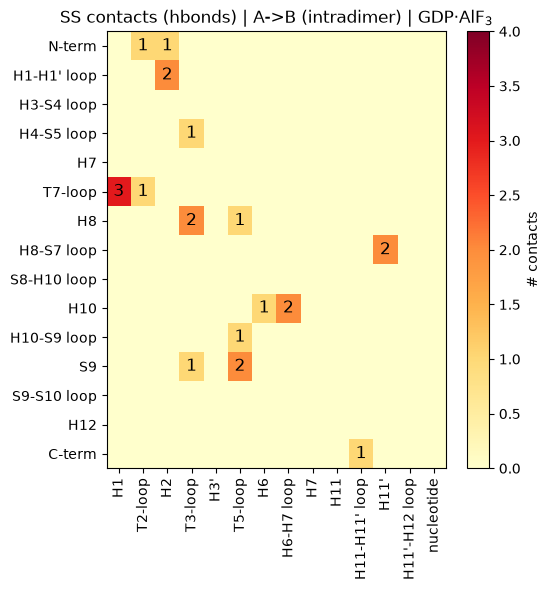

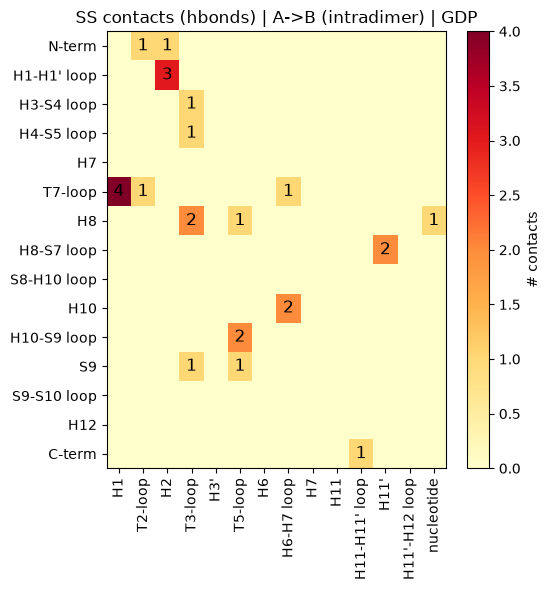

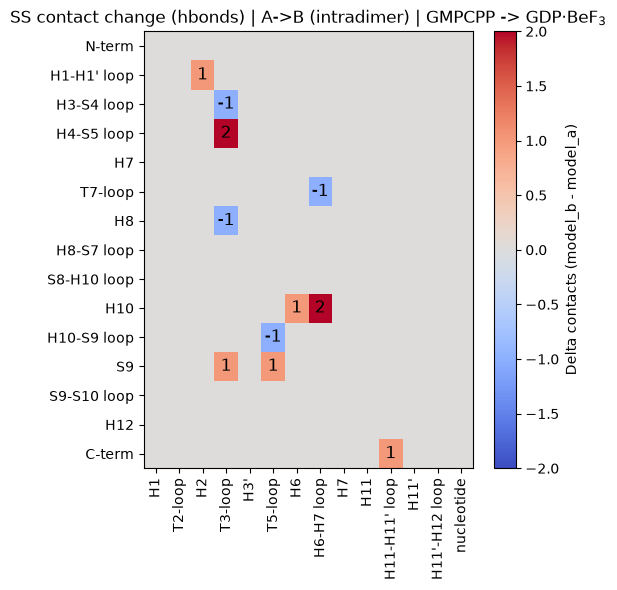

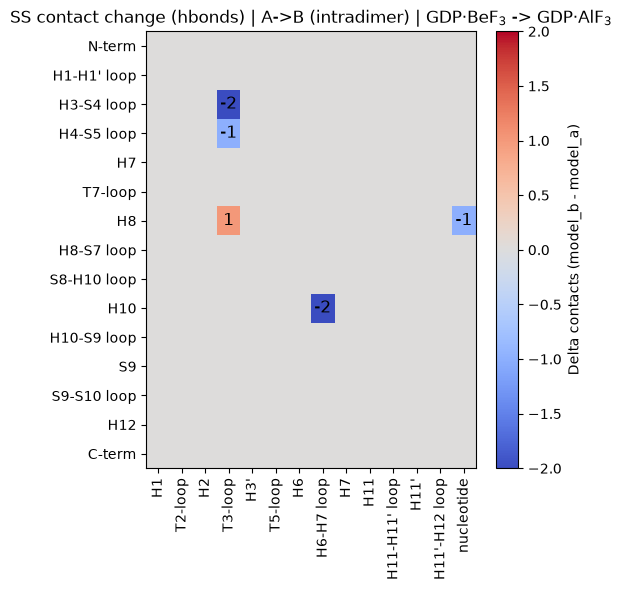

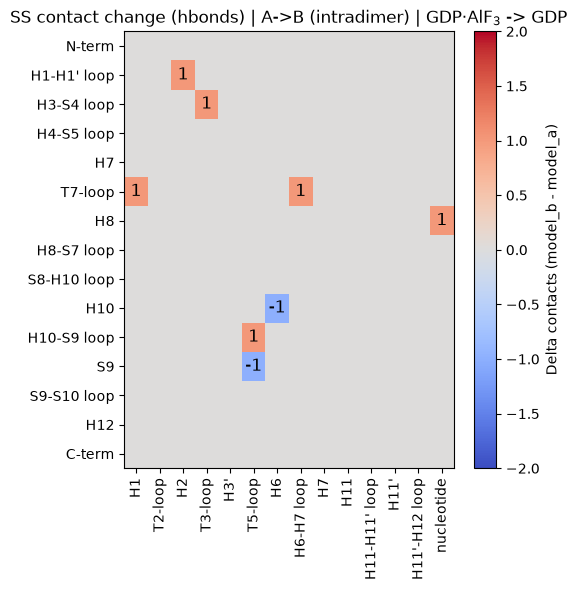

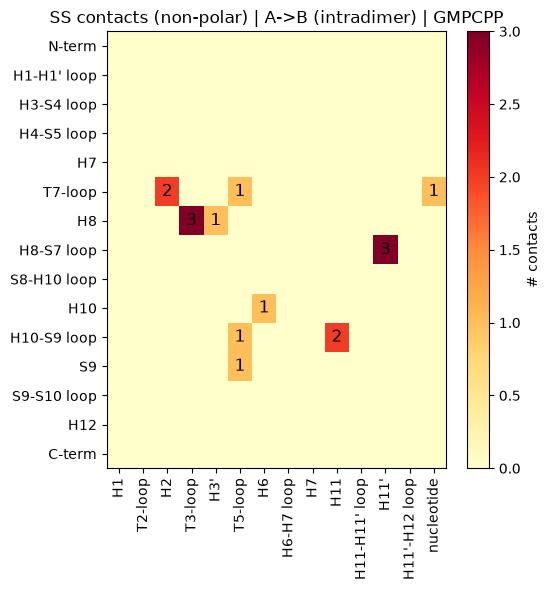

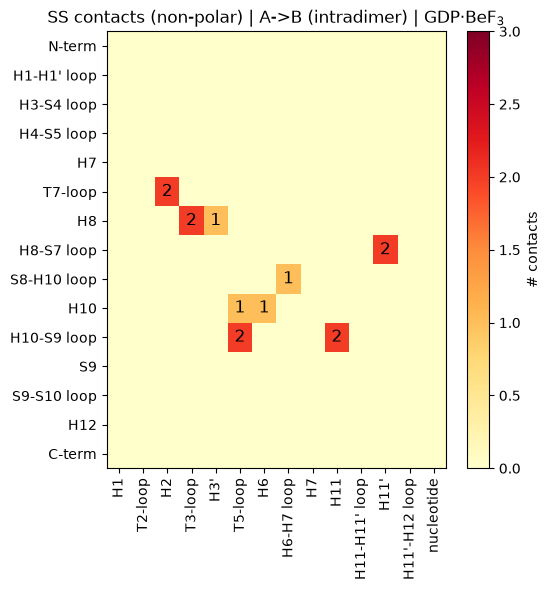

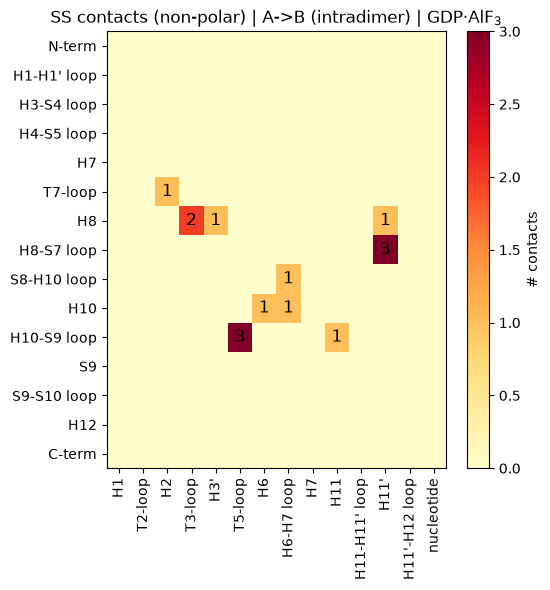

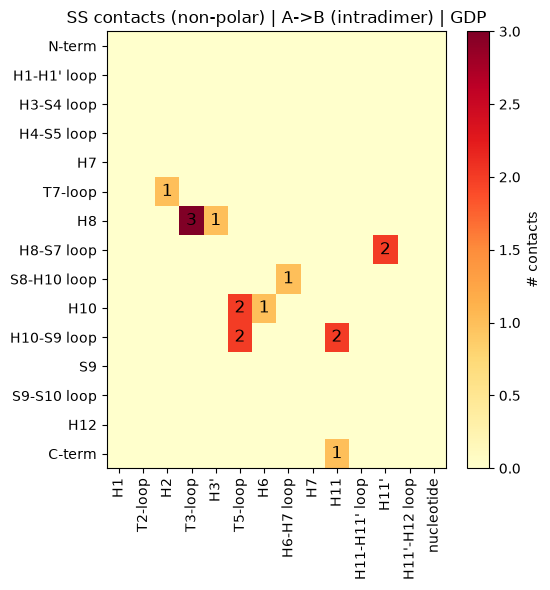

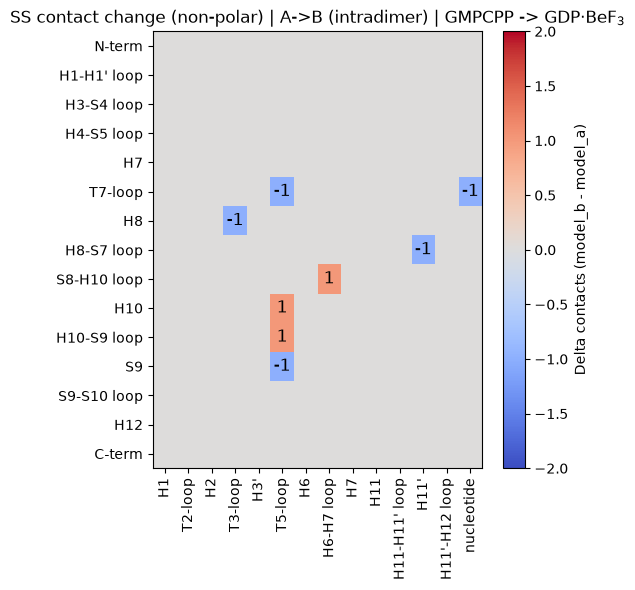

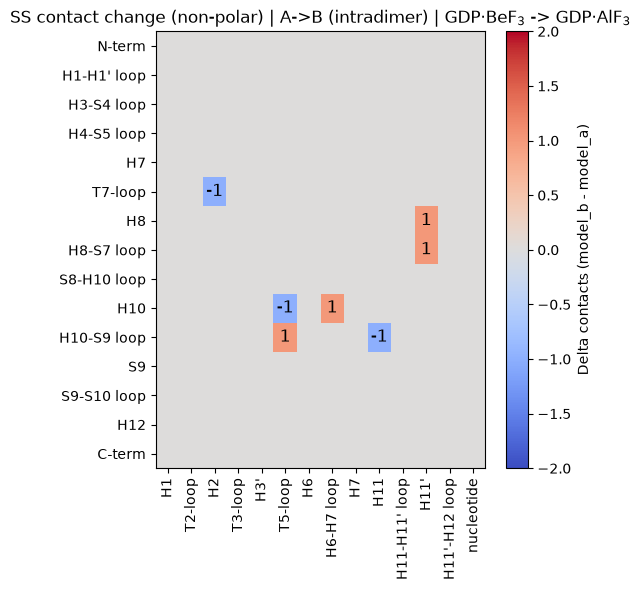

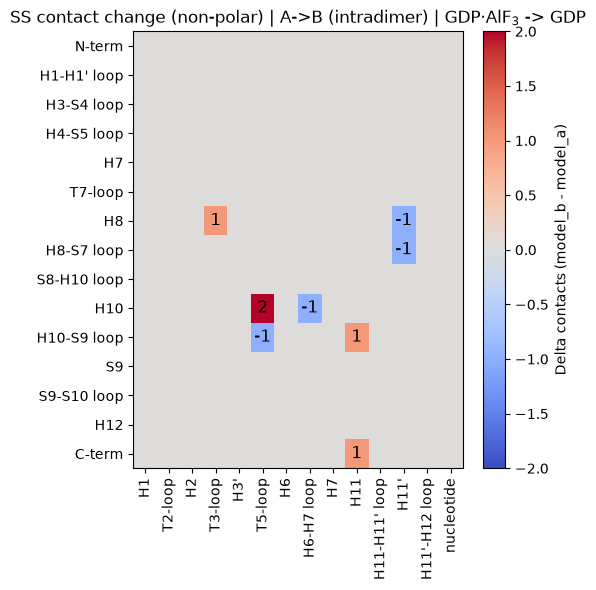

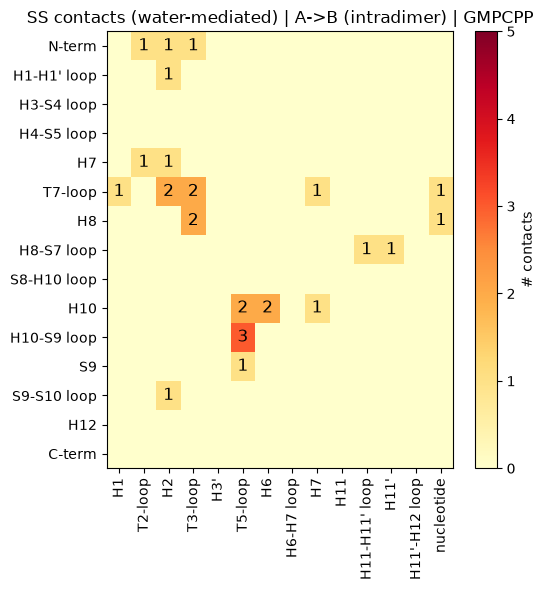

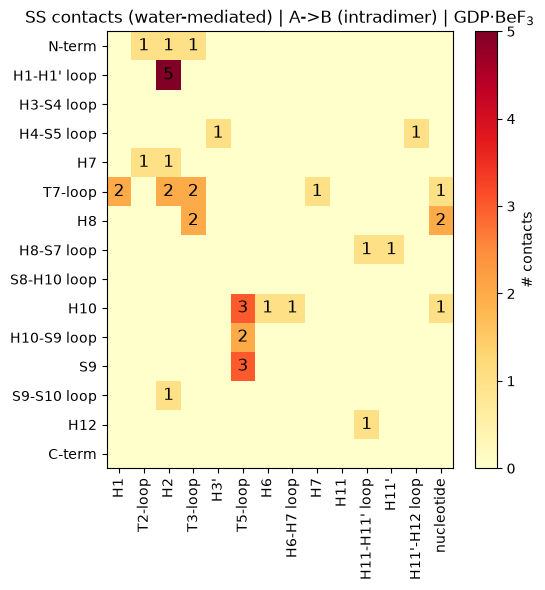

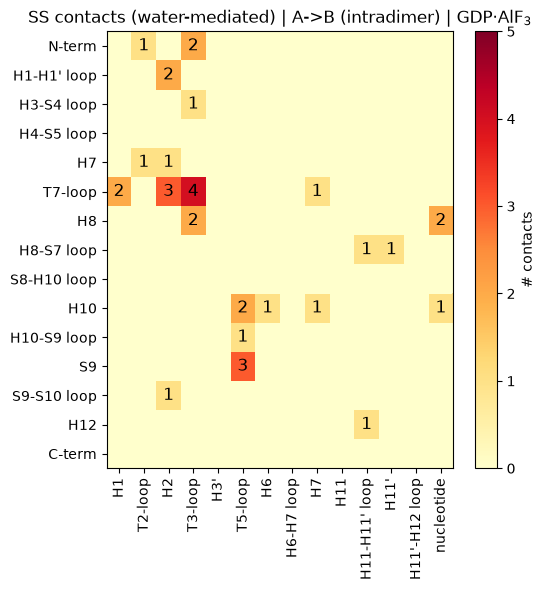

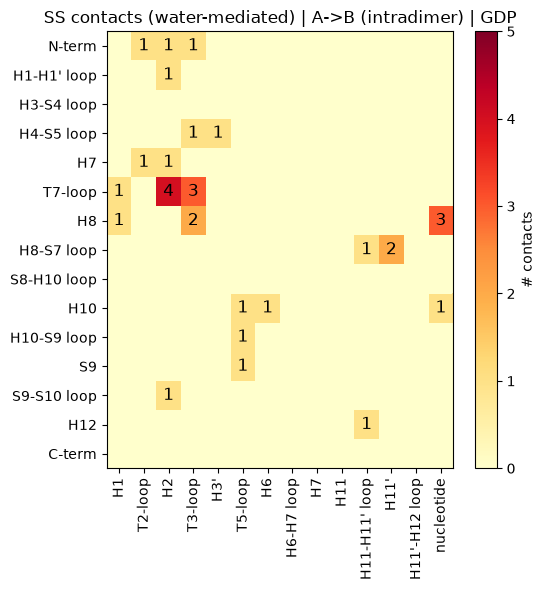

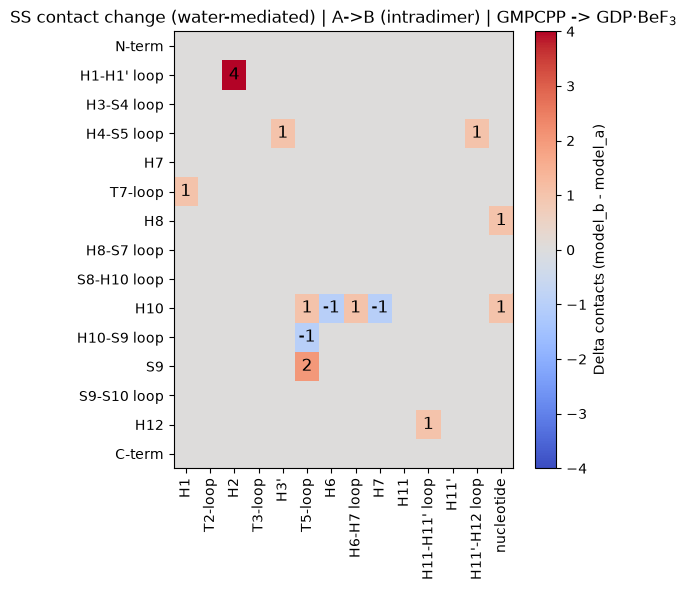

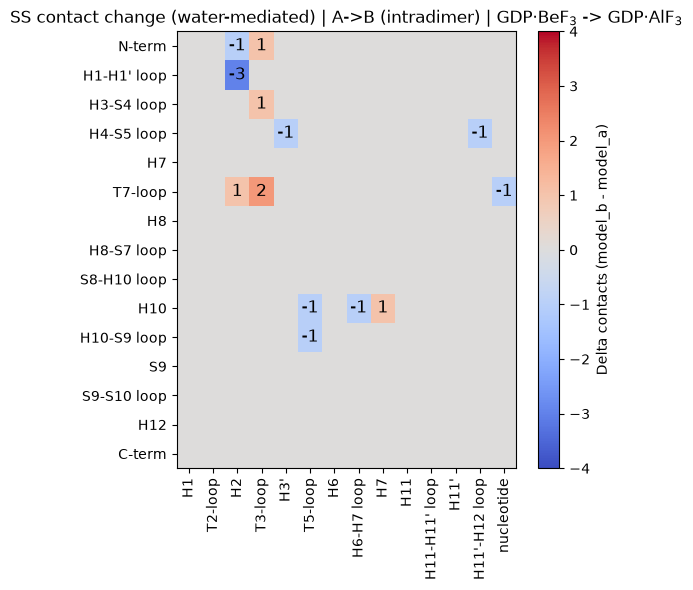

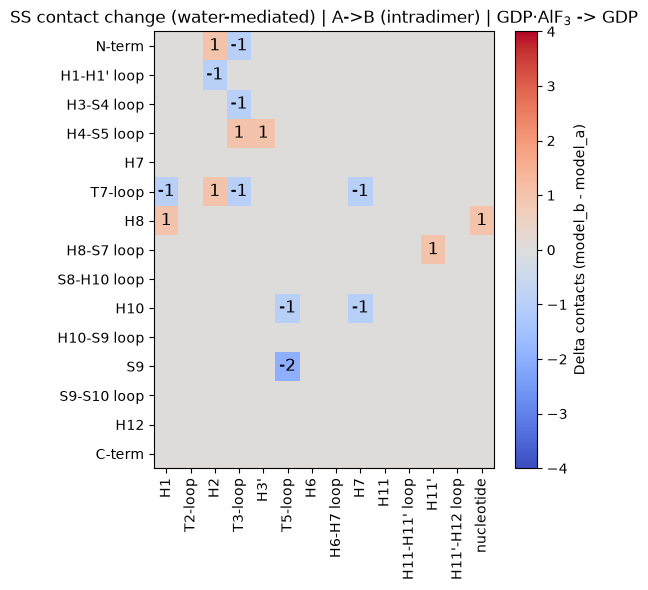

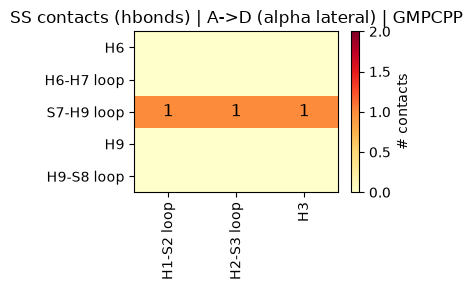

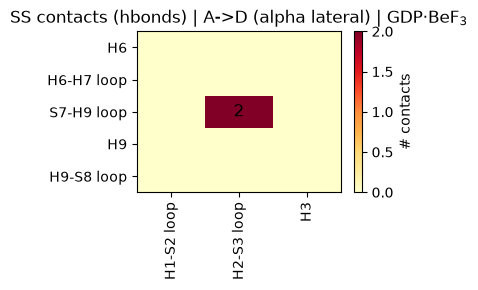

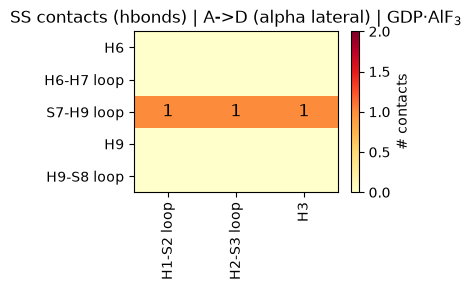

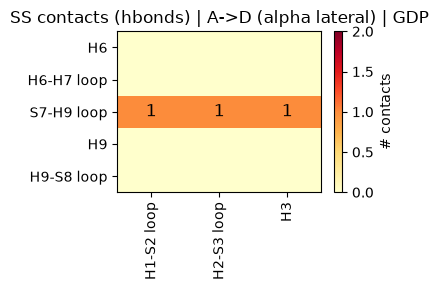

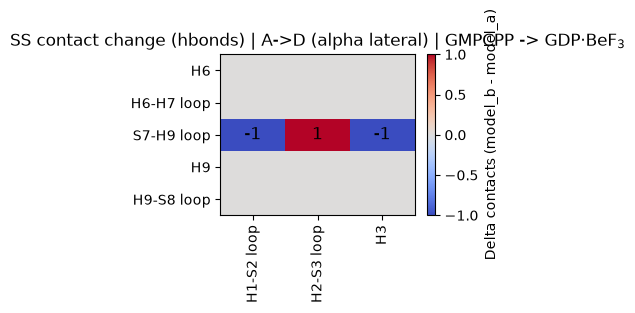

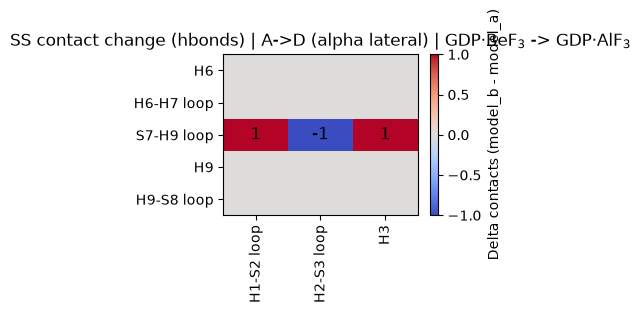

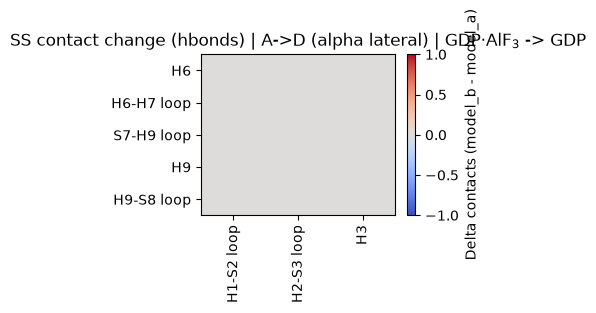

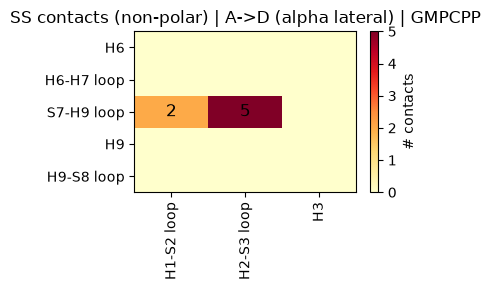

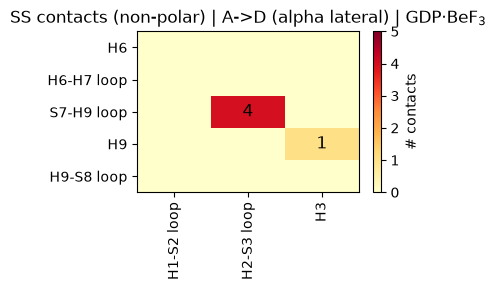

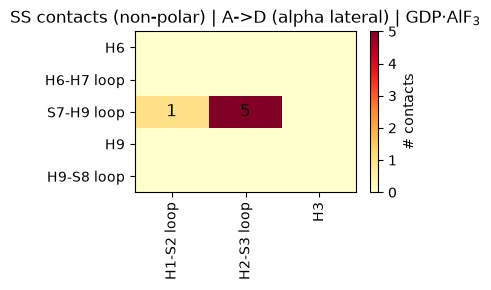

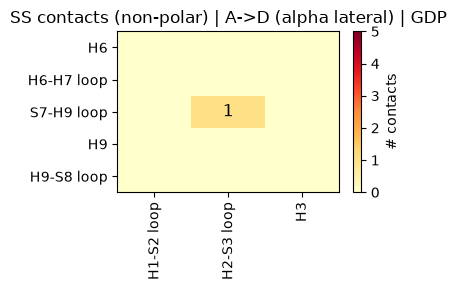

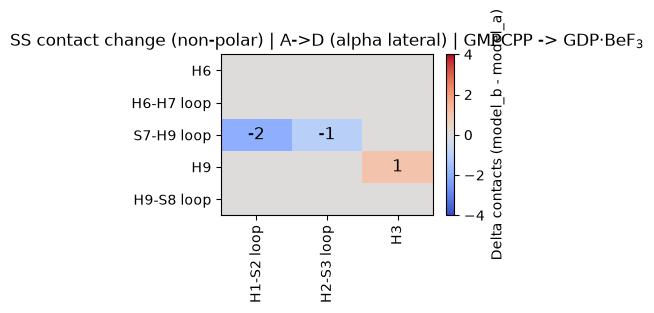

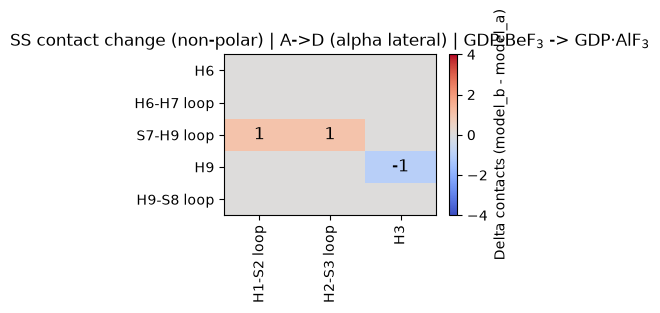

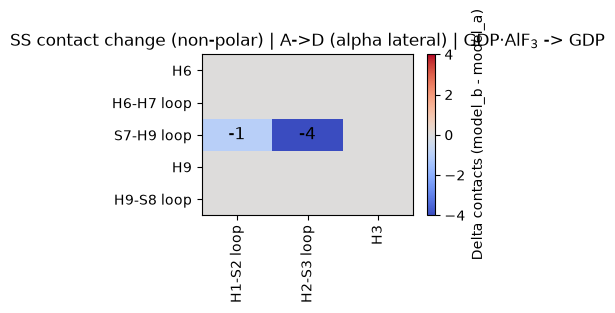

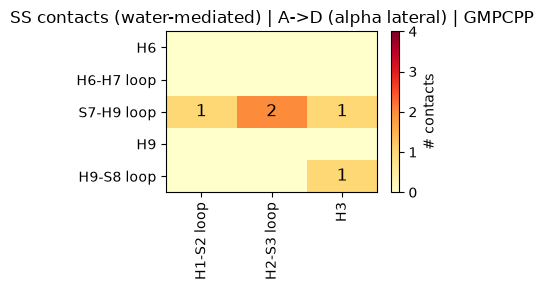

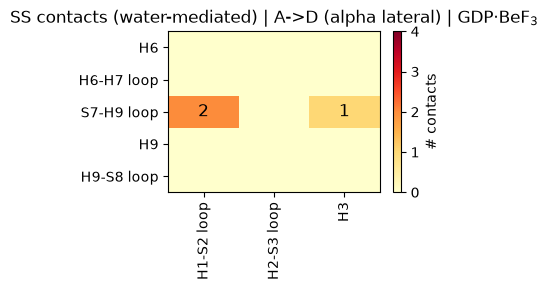

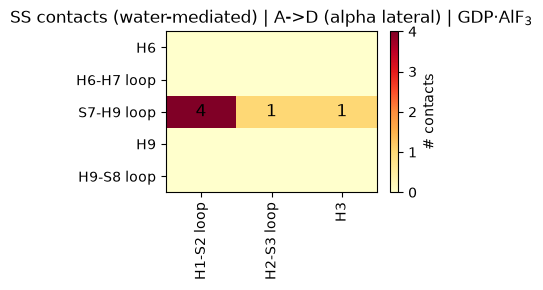

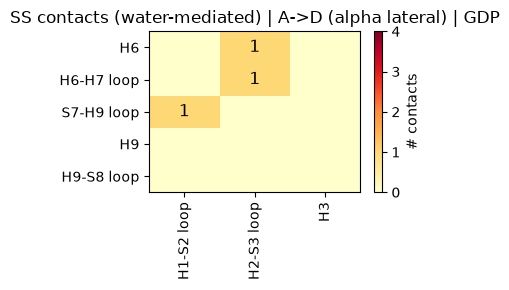

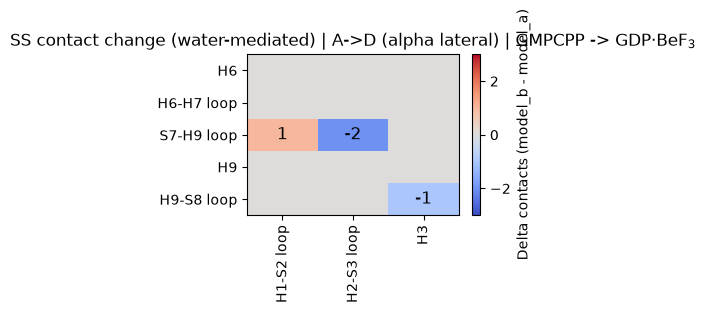

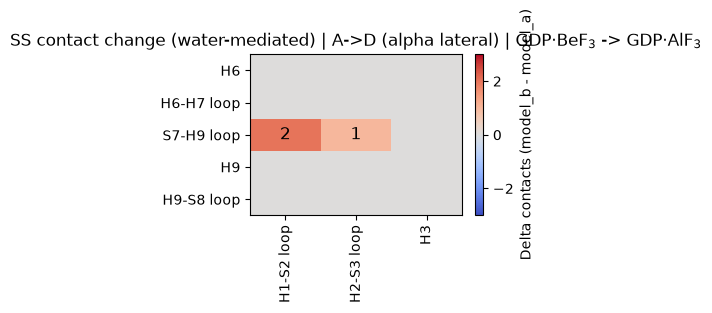

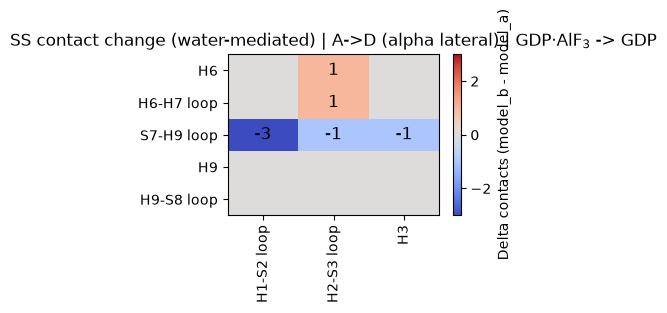

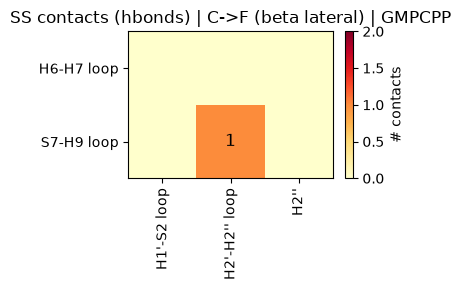

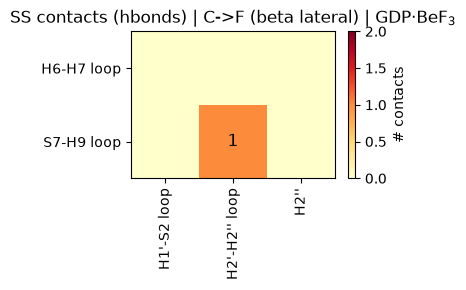

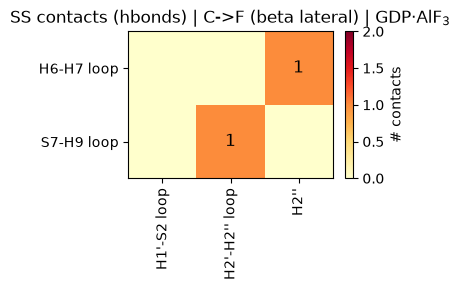

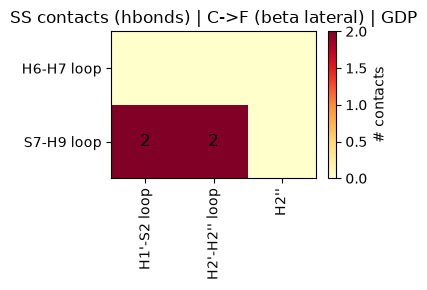

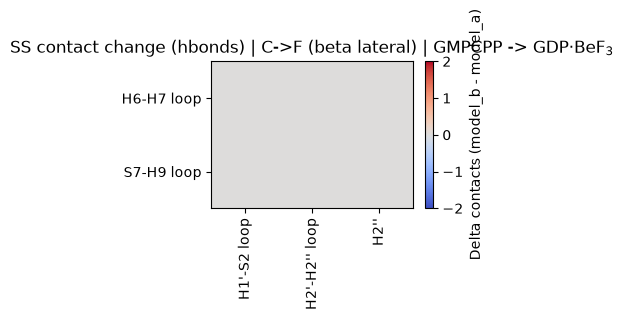

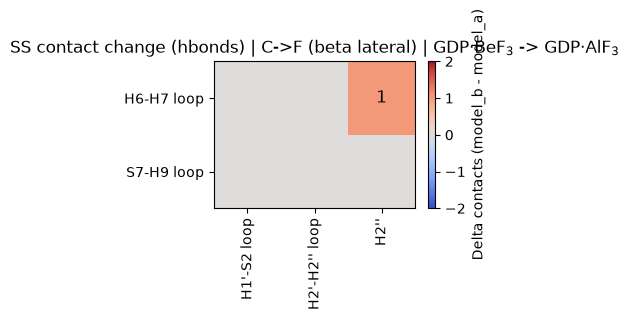

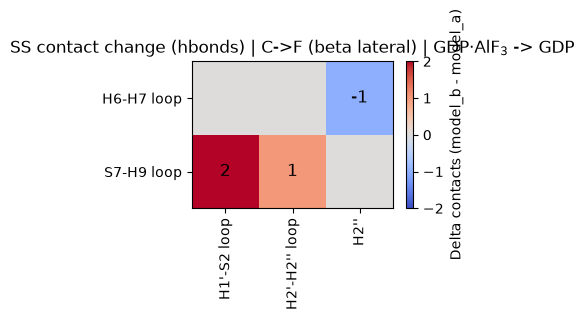

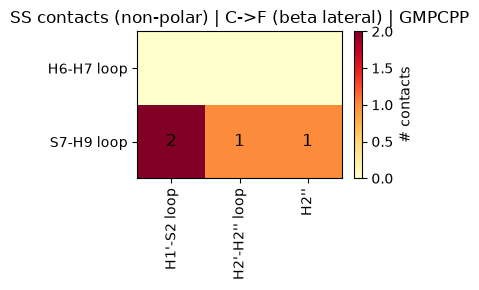

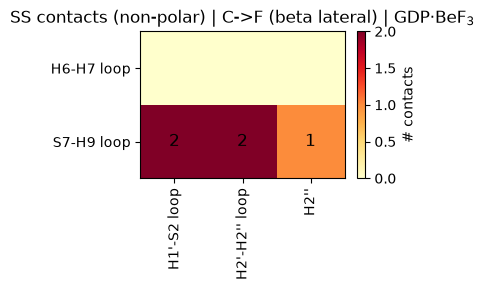

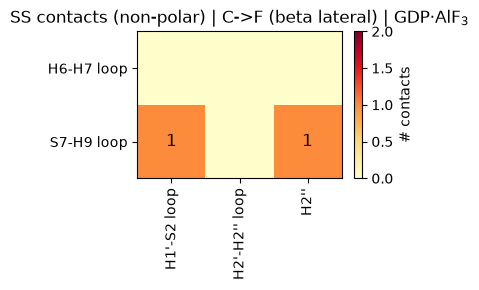

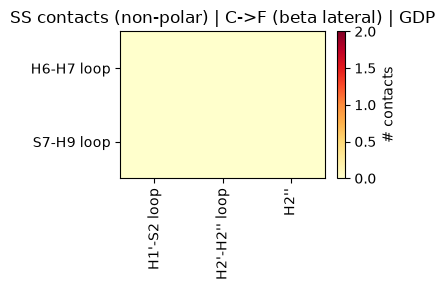

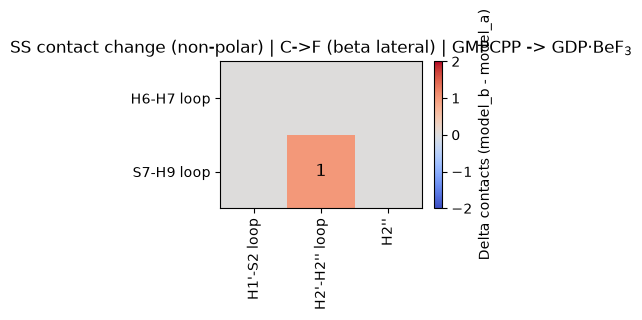

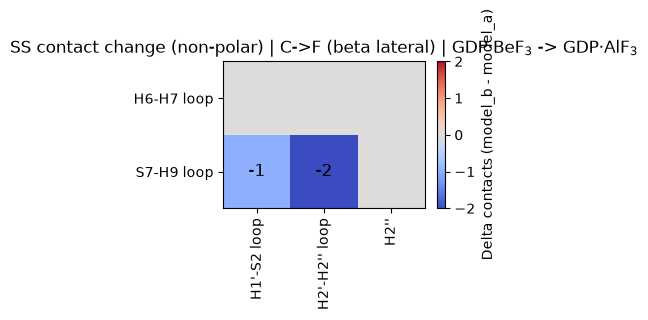

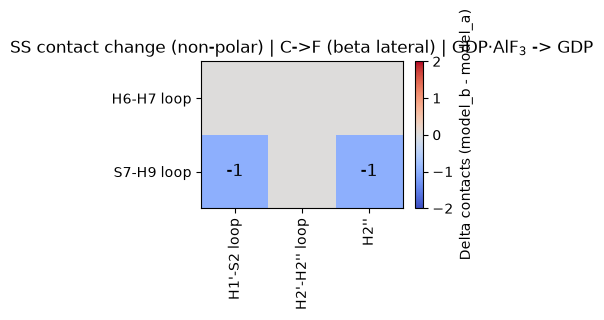

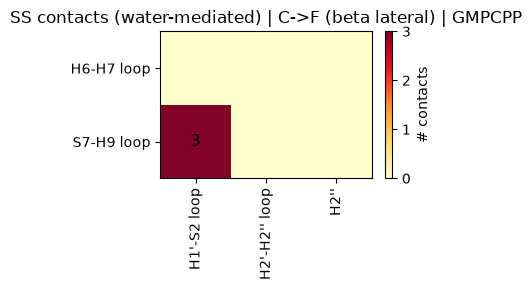

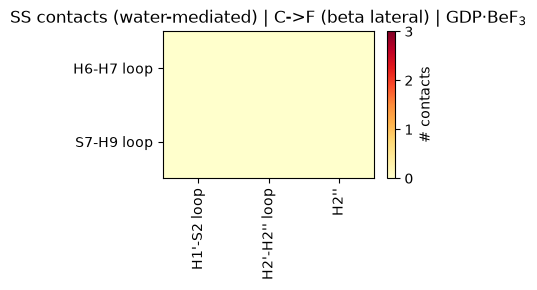

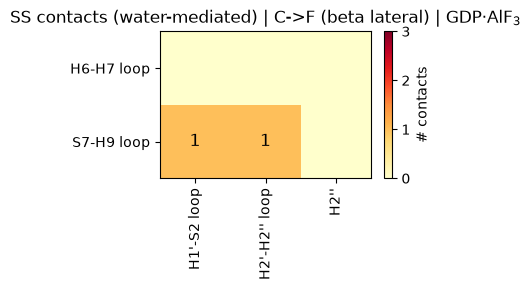

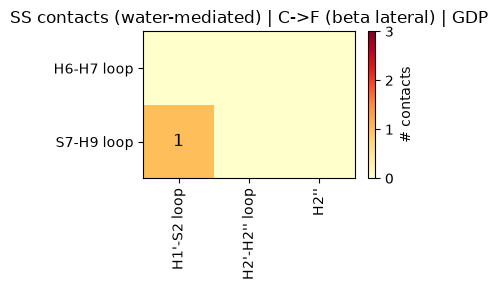

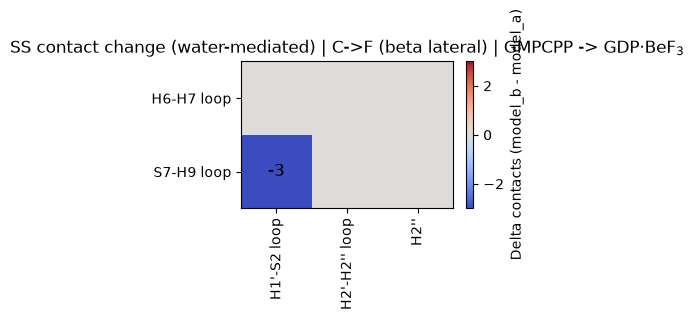

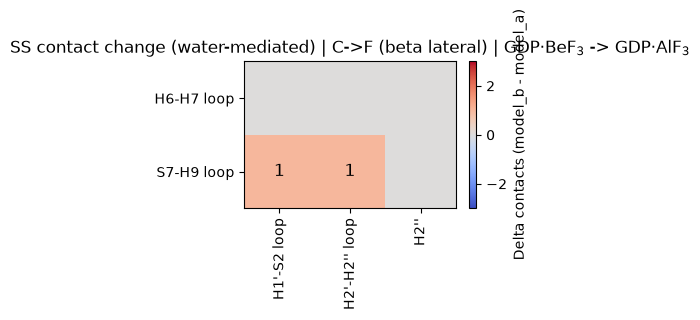

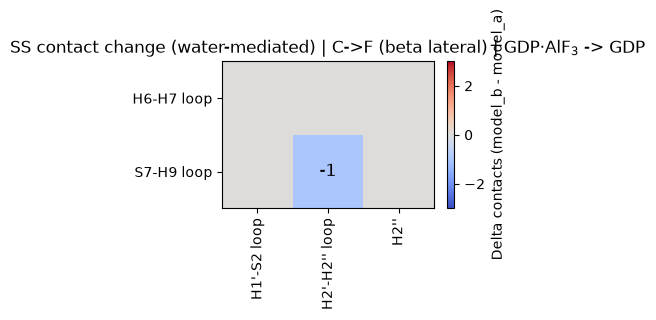

In [10]:
# SS-level contact-count heatmaps by category and transition deltas.
# Categories counted between SS-element pairs:
#   - hbonds         : direct hbonds (non-water residue pairs)
#   - non-polar      : contacts source with category hydrophobic/other (non-water pairs)
#   - water-mediated : residue pairs connected through at least one water in a given model
#
# Pipeline: (1) aggregate counts -> (2) build aligned DataFrames per interface/category
#           -> (3) plot with identical SS axes and shared color limits per group.


if "unified_edges_df" not in globals() or unified_edges_df.empty:
    raise RuntimeError("unified_edges_df is empty/undefined. Run unified-edge construction first.")

if "node1_ss" not in unified_edges_df.columns or "node2_ss" not in unified_edges_df.columns:
    raise RuntimeError("node1_ss/node2_ss missing. Run the SS-annotation cell first.")



if "display_model_name" not in globals():
    def display_model_name(model_name):
        return str(model_name)

if "CHAIN_TO_SUBUNIT" not in globals():
    CHAIN_TO_SUBUNIT = {
        "A": "alpha", "D": "alpha",
        "E": "beta",  "B": "beta", "C": "beta", "F": "beta",
    }

interface_specs = [
    {"label": "A->C (interdimer)", "pairs": [("A", "C")]},
    {"label": "A->B (intradimer)", "pairs": [("A", "B")]},
    {"label": "A->D (alpha lateral)", "pairs": [("A", "D")]},
    {"label": "C->F (beta lateral)", "pairs": [("C", "F")]},
]


def _split_node_local(node):
    parts = str(node).split(":", 3)
    if len(parts) != 4:
        return None, None, None, None
    c, res, rn, atom = parts
    try:
        rn = int(rn)
    except ValueError:
        rn = None
    return c, res, rn, atom


def _ordered_ss_labels(subunit, labels):
    base = []
    if subunit == "alpha" and "alpha_ss_ranges" in globals():
        base = [name for name, _s, _e in alpha_ss_ranges]
    elif subunit == "beta" and "beta_ss_ranges" in globals():
        base = [name for name, _s, _e in beta_ss_ranges]

    labels = [x for x in labels if pd.notna(x)]
    labels_set = set(labels)
    special = ["nucleotide", "water", "unknown_chain", "unassigned"]

    # Keep source text-file SS order as backbone.
    ordered = [x for x in base if x in labels_set]

    # Place derived loop labels between flanking SS elements when possible,
    # e.g. "S9-S10 loop" appears between S9 and S10.
    loop_pat = re.compile(r"^(.+)-(.+) loop$")
    base_idx = {name: i for i, name in enumerate(base)}

    between = []
    unresolved = []
    for lab in labels:
        m = loop_pat.match(str(lab))
        if not m:
            continue
        left = m.group(1).strip()
        right = m.group(2).strip()
        if left in base_idx and right in base_idx and base_idx[left] < base_idx[right]:
            between.append((base_idx[left], base_idx[right], str(lab)))
        else:
            unresolved.append(str(lab))

    between.sort(key=lambda t: (t[0], t[1], t[2]))

    out = []
    used = set()
    for i, name in enumerate(base):
        if name in labels_set:
            out.append(name)
            used.add(name)
        # Insert loops anchored after this element and before later element(s).
        for left_i, _right_i, lab in between:
            if left_i == i and lab not in used and lab in labels_set:
                out.append(lab)
                used.add(lab)

    # Add any labels not consumed (including before/after and unresolved loops).
    for lab in labels:
        lab = str(lab)
        if lab in labels_set and lab not in used and lab not in special:
            out.append(lab)
            used.add(lab)

    # Keep special labels last, in fixed order.
    for lab in special:
        if lab in labels_set and lab not in used:
            out.append(lab)
            used.add(lab)

    # Final safety for anything remaining.
    for lab in labels:
        lab = str(lab)
        if lab not in used:
            out.append(lab)
            used.add(lab)

    return out


def _collect_ss_contact_counts_for_interface(df_model, interface_pairs):
    counts = {
        "hbonds": {},
        "non-polar": {},
        "water-mediated": {},
    }

    for chain_x, chain_y in interface_pairs:
        # Deduplicate only non-polar events at residue-pair level.
        seen_nonpolar_respairs = set()

        for _, r in df_model.iterrows():
            c1, res1, rn1, _a1 = _split_node_local(r["node1"])
            c2, res2, rn2, _a2 = _split_node_local(r["node2"])
            if None in {c1, res1, c2, res2}:
                continue
            if {c1, c2} != {chain_x, chain_y}:
                continue

            direct_pair = (c1 == chain_x and c2 == chain_y)
            x_ss = r["node1_ss"] if direct_pair else r["node2_ss"]
            y_ss = r["node2_ss"] if direct_pair else r["node1_ss"]

            src = r.get("interaction_source", None)
            cat = r.get("interaction_category", None)

            if res1 != "HOH" and res2 != "HOH":
                key = (x_ss, y_ss)
                if src == "hbonds":
                    counts["hbonds"][key] = counts["hbonds"].get(key, 0) + 1
                elif src == "contacts" and cat in {"hydrophobic"}:
                    if rn1 is None or rn2 is None:
                        continue
                    res_pair = (int(rn1), int(rn2)) if direct_pair else (int(rn2), int(rn1))
                    if res_pair in seen_nonpolar_respairs:
                        continue
                    seen_nonpolar_respairs.add(res_pair)
                    counts["non-polar"][key] = counts["non-polar"].get(key, 0) + 1

        water_to_x = {}
        water_to_y = {}
        res_to_ss_x = {}
        res_to_ss_y = {}

        for _, r in df_model.iterrows():
            src = r.get("interaction_source", None)
            if src not in {"hbonds"}:
                continue

            c1, res1, rn1, _a1 = _split_node_local(r["node1"])
            c2, res2, rn2, _a2 = _split_node_local(r["node2"])
            if None in {c1, res1, rn1, c2, res2, rn2}:
                continue

            if res1 == "HOH":
                w = f"{c1}:{rn1}"
                if c2 == chain_x and res2 != "HOH":
                    water_to_x.setdefault(w, set()).add(int(rn2))
                    res_to_ss_x[int(rn2)] = r["node2_ss"]
                if c2 == chain_y and res2 != "HOH":
                    water_to_y.setdefault(w, set()).add(int(rn2))
                    res_to_ss_y[int(rn2)] = r["node2_ss"]

            if res2 == "HOH":
                w = f"{c2}:{rn2}"
                if c1 == chain_x and res1 != "HOH":
                    water_to_x.setdefault(w, set()).add(int(rn1))
                    res_to_ss_x[int(rn1)] = r["node1_ss"]
                if c1 == chain_y and res1 != "HOH":
                    water_to_y.setdefault(w, set()).add(int(rn1))
                    res_to_ss_y[int(rn1)] = r["node1_ss"]

        for w in set(water_to_x.keys()) & set(water_to_y.keys()):
            for rx in water_to_x[w]:
                for ry in water_to_y[w]:
                    x_ss = res_to_ss_x.get(rx, "unassigned")
                    y_ss = res_to_ss_y.get(ry, "unassigned")
                    key = (x_ss, y_ss)
                    counts["water-mediated"][key] = counts["water-mediated"].get(key, 0) + 1

    return counts


def _counts_dict_to_heat(counts_dict, x_order=None, y_order=None):
    """Pivot counts to a matrix; if counts are empty but orders are given, return zeros on that grid."""
    if not counts_dict:
        if x_order is not None and y_order is not None:
            return pd.DataFrame(0.0, index=list(y_order), columns=list(x_order))
        return pd.DataFrame()
    rows = [{"x_ss": k[0], "y_ss": k[1], "count": v} for k, v in counts_dict.items()]
    df = pd.DataFrame(rows)
    heat = df.pivot_table(index="y_ss", columns="x_ss", values="count", aggfunc="sum", fill_value=0)
    if y_order is not None or x_order is not None:
        heat = heat.reindex(
            index=y_order if y_order is not None else heat.index,
            columns=x_order if x_order is not None else heat.columns,
            fill_value=0,
        )
    return heat


def _plot_heat(heat, title, cbar_label, cmap="viridis", delta=False, vmin=None, vmax=None):
    if heat.empty:
        print(f"No data for {title}")
        return

    fig_w = max(4.0, 0.4 * len(heat.columns))
    fig_h = max(3.0, 0.4 * len(heat.index))
    plt.figure(figsize=(fig_w, fig_h))

    arr = heat.to_numpy(dtype=float)
    if delta:
        if vmin is None or vmax is None:
            vmax_abs = float(np.abs(arr).max()) if arr.size else 1.0
            if vmax_abs == 0:
                vmax_abs = 1.0
            vmin, vmax = -10, 10
        im = plt.imshow(arr, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    else:
        if vmin is None:
            vmin = 0.0
        if vmax is None:
            vmax = float(10) if arr.size else 1.0
            if vmax == 0:
                vmax = 1.0
        im = plt.imshow(arr, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)

    cbar = plt.colorbar(im)
    cbar.set_label(cbar_label)

    plt.xticks(range(len(heat.columns)), heat.columns, rotation=90)
    plt.yticks(range(len(heat.index)), heat.index)

    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v = int(round(heat.iat[i, j]))
            if v != 0:
                txt_color = "black"
                plt.text(j, i, str(v), ha="center", va="center", fontsize=12, color=txt_color)

    plt.title(title)
    plt.tight_layout()
    # Fix: join is a string method, not a list method
    heatmap_folder = 'heatmaps/' + "/".join(title.split("|")[:-2])
    os.makedirs(heatmap_folder, exist_ok=True)
    safe = re.sub(r"[^\w\-.]+", "_", title).strip("_")[:200]
    plt.savefig(heatmap_folder + "/" + safe + ".svg", format="svg")
    plt.show()


# ----- (1) Raw counts per model / interface / category -----
categories = ["hbonds", "non-polar", "water-mediated"]
model_iface_counts = {}
for model in model_order:
    df_model = unified_edges_df[unified_edges_df["source_pdb"] == model].copy()
    model_iface_counts[model] = {}
    for spec in interface_specs:
        model_iface_counts[model][spec["label"]] = _collect_ss_contact_counts_for_interface(df_model, spec["pairs"])

# ----- (2) One SS axis system per interface; aligned tables + deltas -----
iface_ss_axes = {}
for spec in interface_specs:
    iface_label = spec["label"]
    primary_x, primary_y = spec["pairs"][0]
    x_sub = CHAIN_TO_SUBUNIT.get(primary_x)
    y_sub = CHAIN_TO_SUBUNIT.get(primary_y)

    all_x = set()
    all_y = set()
    for model in model_order:
        for cat in categories:
            for k in model_iface_counts[model][iface_label][cat].keys():
                all_x.add(k[0])
                all_y.add(k[1])

    iface_ss_axes[iface_label] = {
        "x_order": _ordered_ss_labels(x_sub, sorted(all_x)),
        "y_order": _ordered_ss_labels(y_sub, sorted(all_y)),
    }

ss_per_model_heats = {}
ss_delta_heats = {}
for spec in interface_specs:
    il = spec["label"]
    x_order = iface_ss_axes[il]["x_order"]
    y_order = iface_ss_axes[il]["y_order"]
    ss_per_model_heats[il] = {}
    ss_delta_heats[il] = {}
    for cat in categories:
        ss_per_model_heats[il][cat] = {}
        for model in model_order:
            raw = model_iface_counts[model][il][cat]
            ss_per_model_heats[il][cat][model] = _counts_dict_to_heat(raw, x_order=x_order, y_order=y_order)
        ss_delta_heats[il][cat] = {}
        for i in range(len(model_order) - 1):
            ma, mb = model_order[i], model_order[i + 1]
            ha = ss_per_model_heats[il][cat][ma]
            hb = ss_per_model_heats[il][cat][mb]
            ss_delta_heats[il][cat][(ma, mb)] = hb - ha

# Optional: inspect limits used below
ss_heatmap_plot_limits = {}

# ----- (3) Plot: same SS labels per interface; shared color scale per (interface, category) -----
for spec in interface_specs:
    il = spec["label"]
    for cat in categories:
        abs_heats = [ss_per_model_heats[il][cat][m] for m in model_order]
        vmax_counts = max((float(h.to_numpy().max()) for h in abs_heats if not h.empty), default=0.0)
        if vmax_counts <= 0:
            vmax_counts = 1.0

        delta_heats = [
            ss_delta_heats[il][cat][(model_order[i], model_order[i + 1])]
            for i in range(len(model_order) - 1)
        ]
        vmax_delta = max((float(np.abs(h.to_numpy()).max()) for h in delta_heats if not h.empty), default=0.0)
        if vmax_delta <= 0:
            vmax_delta = 1.0

        ss_heatmap_plot_limits[(il, cat)] = {"abs_vmax": vmax_counts, "delta_abs_vmax": vmax_delta}

        for model in model_order:
            heat = ss_per_model_heats[il][cat][model]
            _plot_heat(
                heat,
                title=f"SS contacts ({cat}) | {il} | {display_model_name(model)}",
                cbar_label="# contacts",
                cmap="YlOrRd",
                delta=False,
                vmin=0.0,
                vmax=vmax_counts,
            )

        for i in range(len(model_order) - 1):
            ma, mb = model_order[i], model_order[i + 1]
            heat_d = ss_delta_heats[il][cat][(ma, mb)]
            _plot_heat(
                heat_d,
                title=(
                    f"SS contact change ({cat}) | {il} | "
                    f"{display_model_name(ma)} -> {display_model_name(mb)}"
                ),
                cbar_label="Delta contacts (model_b - model_a)",
                cmap="coolwarm",
                delta=True,
                vmin=-vmax_delta,
                vmax=vmax_delta,
            )


In [11]:
# Export SS contact-count analysis to Excel.
# Requires variables from the previous SS-count analysis cell.
required_vars = ["model_iface_counts", "categories", "interface_specs", "model_order"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Missing variables from previous cell: {missing}. Run the SS count-analysis cell first.")
if "display_model_name" not in globals():
    def display_model_name(model_name):
        return str(model_name)
out_xlsx = Path("ss_contact_count_analysis3.xlsx")
# ---------- Long-form tables ----------
absolute_rows = []
for model in model_order:
    model_disp = display_model_name(model)
    for spec in interface_specs:
        iface = spec["label"]
        for cat in categories:
            counts_dict = model_iface_counts[model][iface][cat]
            for (x_ss, y_ss), count in counts_dict.items():
                absolute_rows.append({
                    "model": model,
                    "model_display": model_disp,
                    "interface": iface,
                    "category": cat,
                    "x_ss": x_ss,
                    "y_ss": y_ss,
                    "count": int(count),
                })
absolute_long_df = pd.DataFrame(absolute_rows)
if absolute_long_df.empty:
    absolute_long_df = pd.DataFrame(columns=["model", "model_display", "interface", "category", "x_ss", "y_ss", "count"])
transition_rows = []
for i in range(len(model_order) - 1):
    model_a = model_order[i]
    model_b = model_order[i + 1]
    transition_label = f"{display_model_name(model_a)} -> {display_model_name(model_b)}"
    for spec in interface_specs:
        iface = spec["label"]
        for cat in categories:
            a_dict = model_iface_counts[model_a][iface][cat]
            b_dict = model_iface_counts[model_b][iface][cat]
            all_keys = set(a_dict.keys()) | set(b_dict.keys())
            for key in all_keys:
                a_count = int(a_dict.get(key, 0))
                b_count = int(b_dict.get(key, 0))
                transition_rows.append({
                    "model_a": model_a,
                    "model_b": model_b,
                    "transition": transition_label,
                    "interface": iface,
                    "category": cat,
                    "x_ss": key[0],
                    "y_ss": key[1],
                    "count_a": a_count,
                    "count_b": b_count,
                    "delta": int(b_count - a_count),
                })
transition_long_df = pd.DataFrame(transition_rows)
if transition_long_df.empty:
    transition_long_df = pd.DataFrame(columns=["model_a", "model_b", "transition", "interface", "category", "x_ss", "y_ss", "count_a", "count_b", "delta"])
def _safe_sheet_name(name):
    invalid = set('[]:*?/\\')
    clean = ''.join('-' if ch in invalid else ch for ch in str(name))
    return clean[:31]
with pd.ExcelWriter(out_xlsx) as writer:
    absolute_long_df.to_excel(writer, sheet_name="absolute_long", index=False)
    transition_long_df.to_excel(writer, sheet_name="transition_long", index=False)
    # Compact matrices per (interface, category)
    for spec in interface_specs:
        iface = spec["label"]
        iface_short = iface.split("(")[0].strip().replace(" ", "_")
        for cat in categories:
            abs_sub = absolute_long_df[(absolute_long_df["interface"] == iface) & (absolute_long_df["category"] == cat)].copy()
            if not abs_sub.empty:
                abs_sub["ss_pair"] = abs_sub["x_ss"].astype(str) + " <-> " + abs_sub["y_ss"].astype(str)
                abs_mat = abs_sub.pivot_table(
                    index="ss_pair",
                    columns="model_display",
                    values="count",
                    aggfunc="sum",
                    fill_value=0,
                )
                desired_cols = [display_model_name(m) for m in model_order]
                abs_mat = abs_mat.reindex(columns=[c for c in desired_cols if c in abs_mat.columns], fill_value=0)
            else:
                abs_mat = pd.DataFrame()
            tr_sub = transition_long_df[(transition_long_df["interface"] == iface) & (transition_long_df["category"] == cat)].copy()
            if not tr_sub.empty:
                tr_sub["ss_pair"] = tr_sub["x_ss"].astype(str) + " <-> " + tr_sub["y_ss"].astype(str)
                tr_mat = tr_sub.pivot_table(
                    index="ss_pair",
                    columns="transition",
                    values="delta",
                    aggfunc="sum",
                    fill_value=0,
                )
            else:
                tr_mat = pd.DataFrame()
            abs_mat.to_excel(writer, sheet_name=_safe_sheet_name(f"abs_{iface_short}_{cat}"))
            tr_mat.to_excel(writer, sheet_name=_safe_sheet_name(f"delta_{iface_short}_{cat}"))
print(f"Exported SS contact-count analysis to: {out_xlsx.resolve()}")

Exported SS contact-count analysis to: /Users/filipc_p/Documents/work/PSI/Papers/GTP_cycle/ContactsAnalysis3/ss_contact_count_analysis3.xlsx


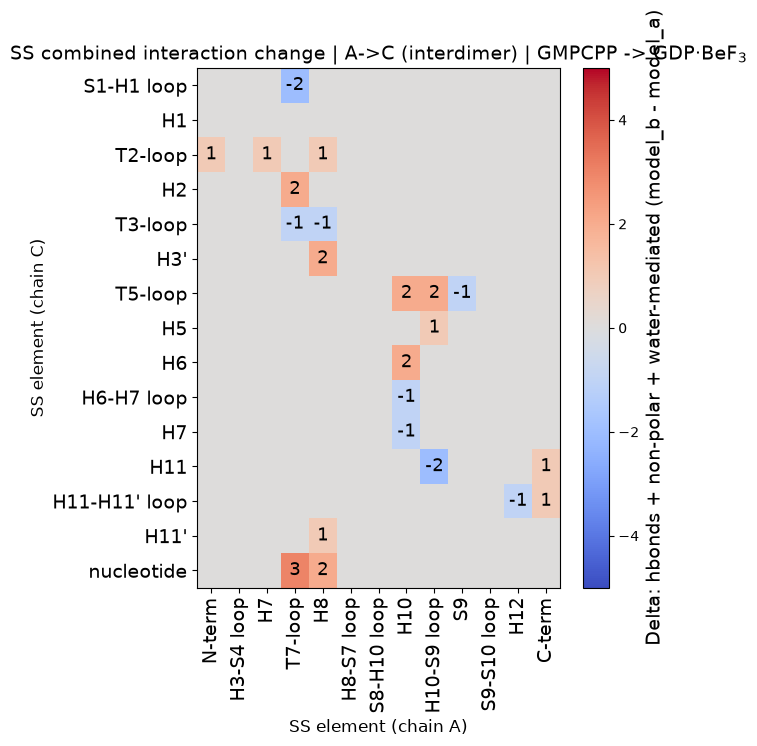

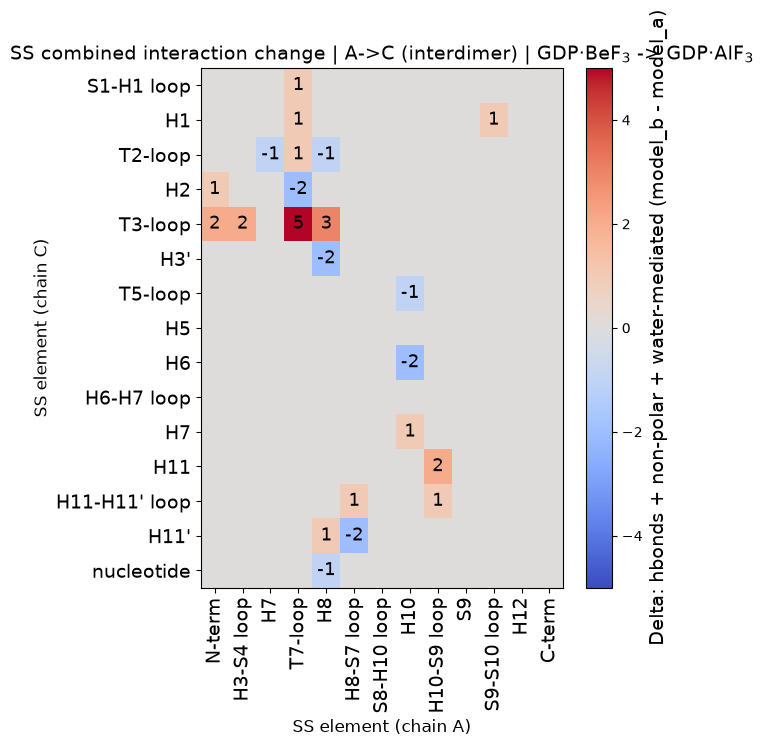

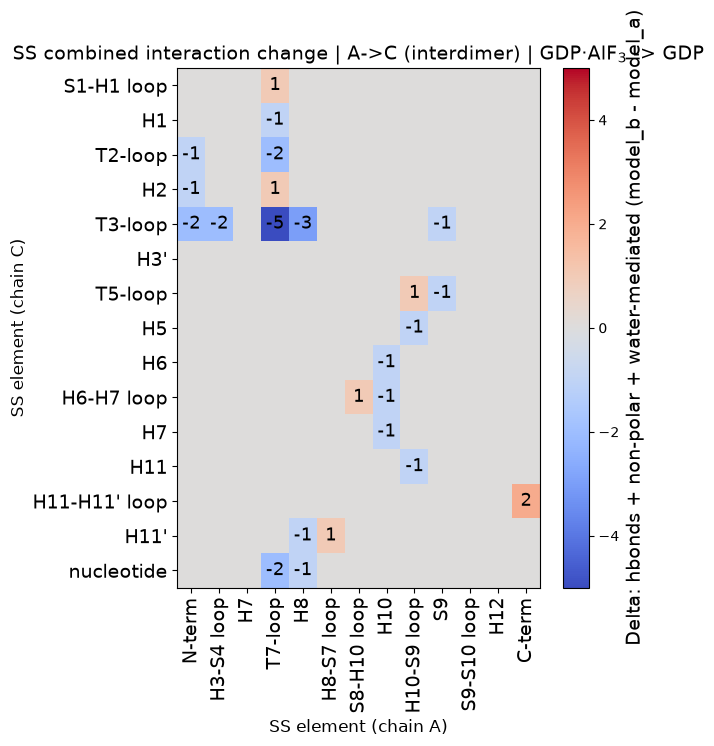

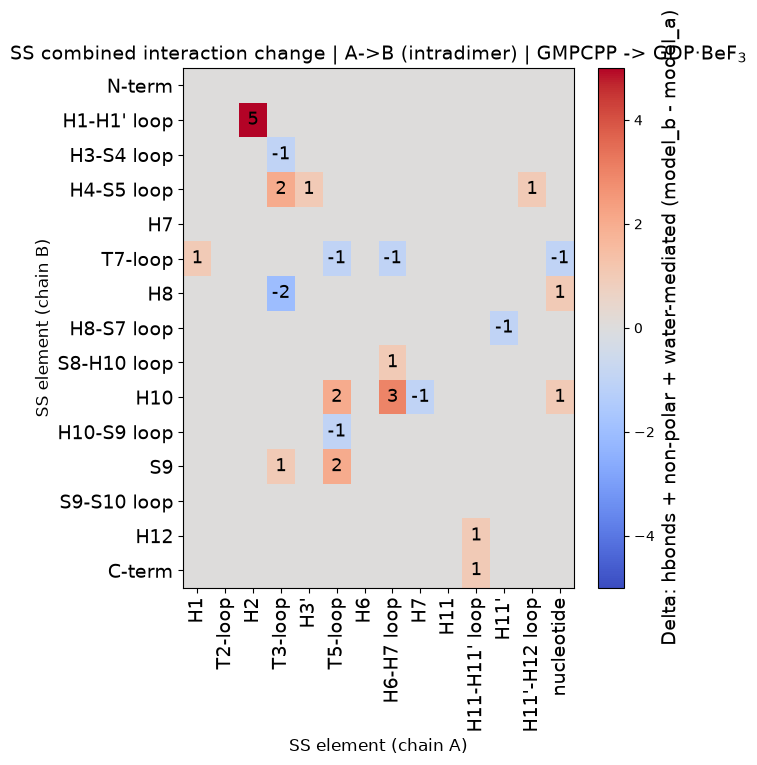

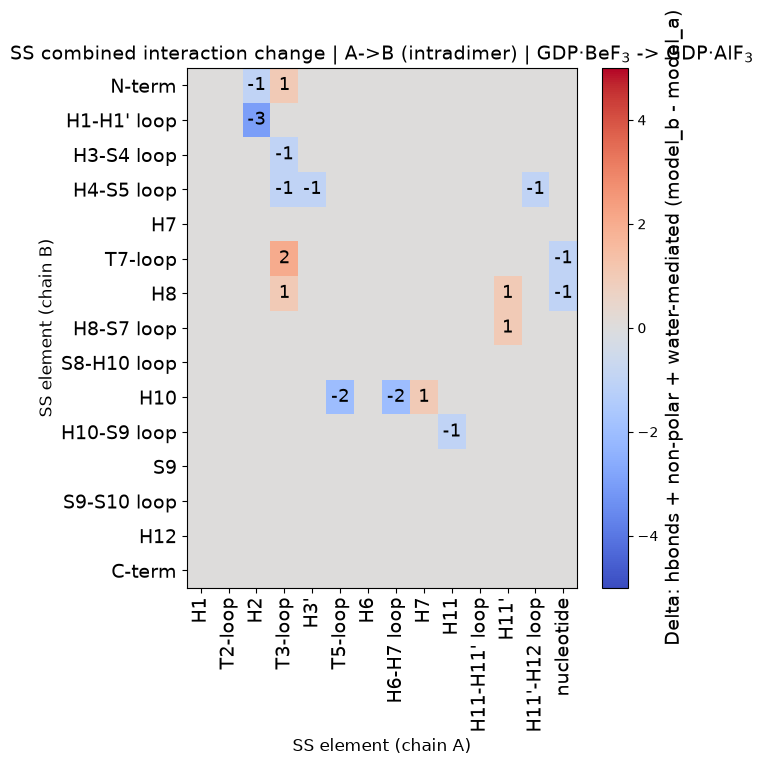

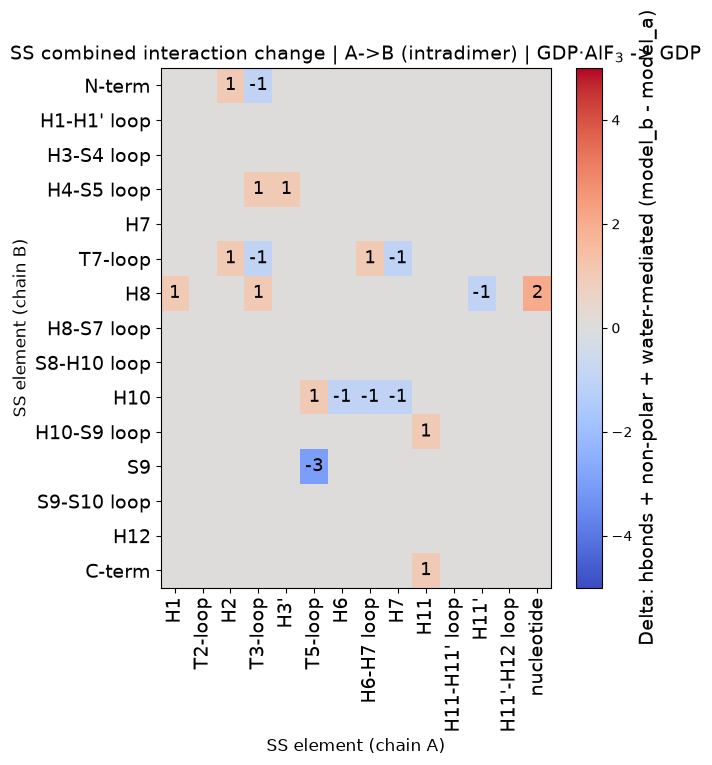

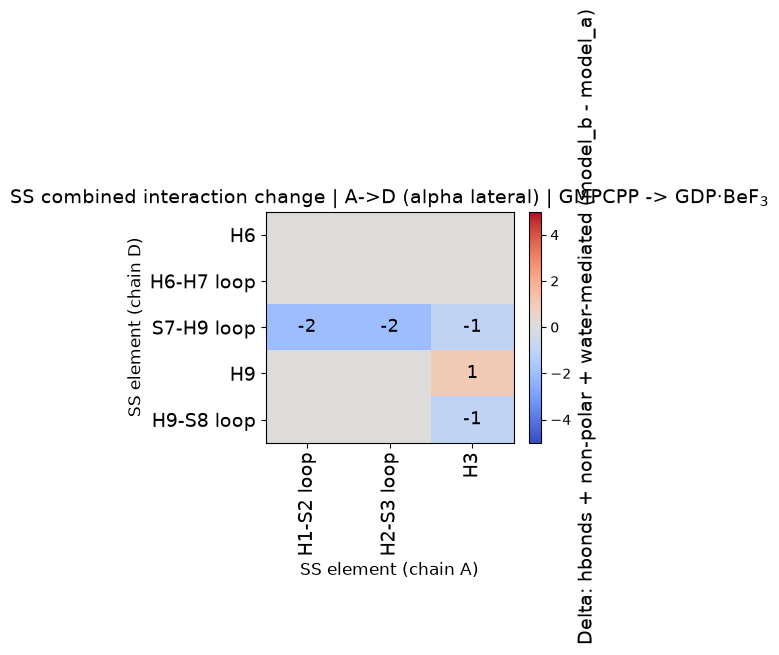

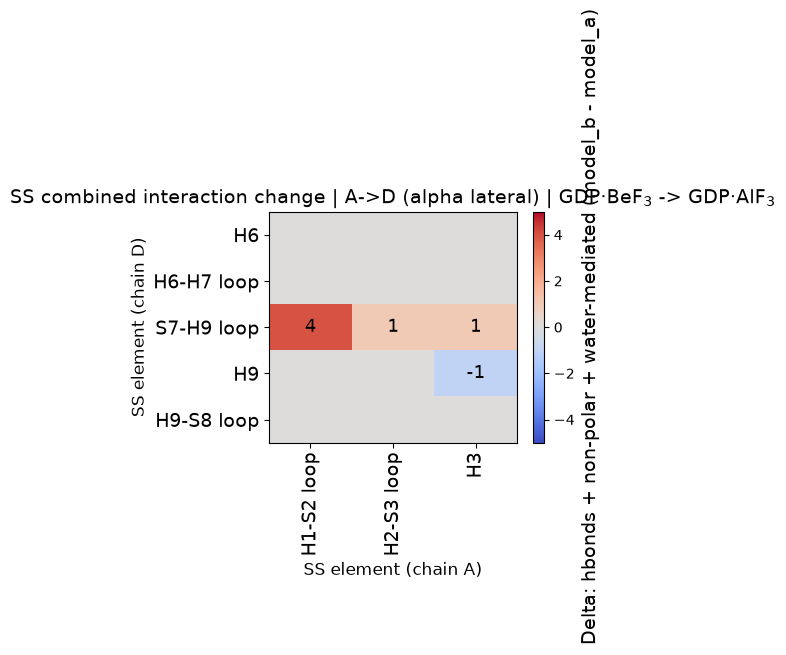

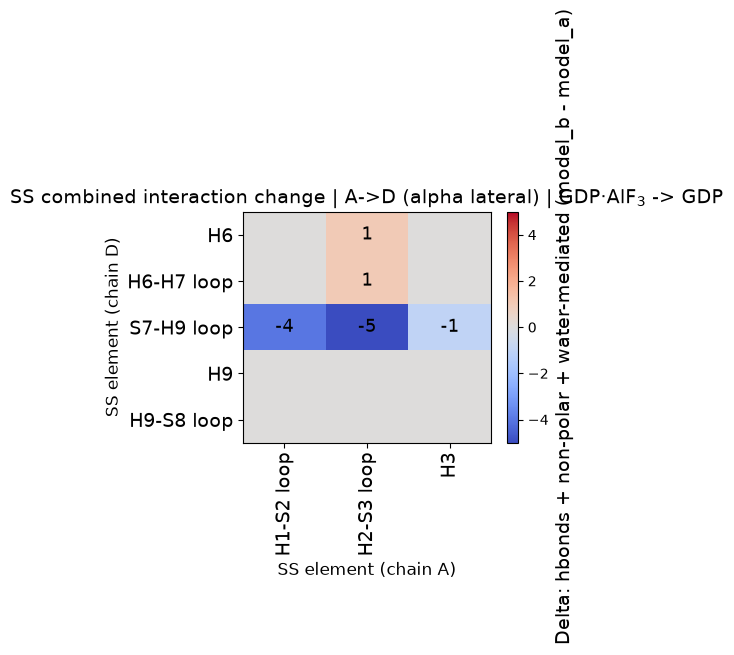

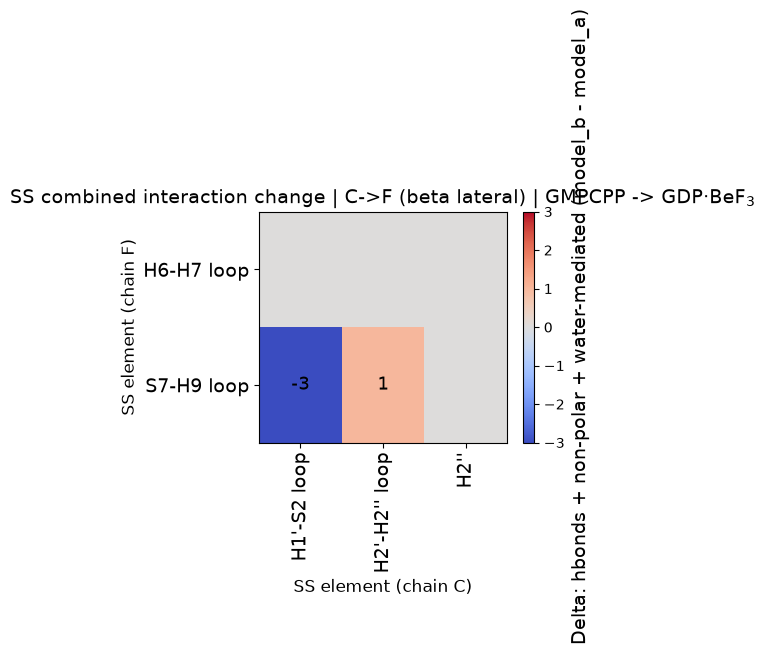

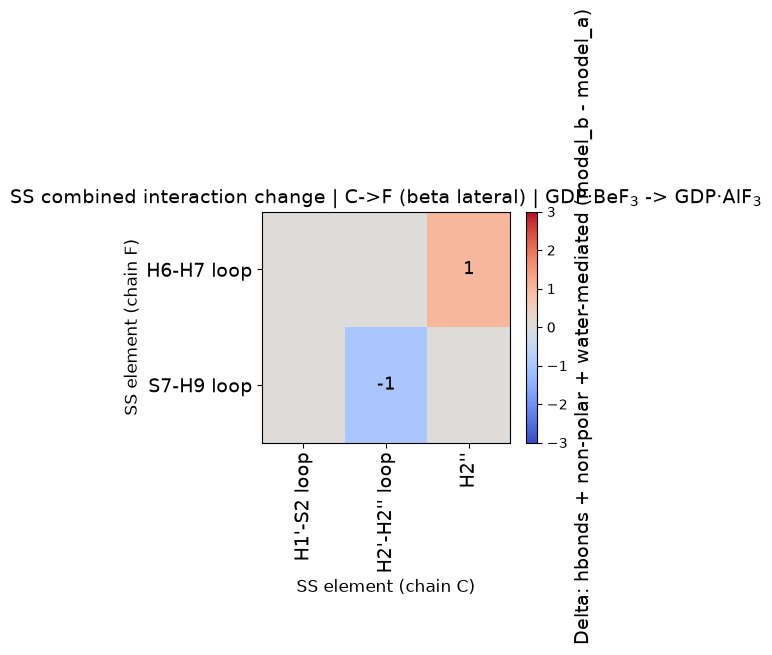

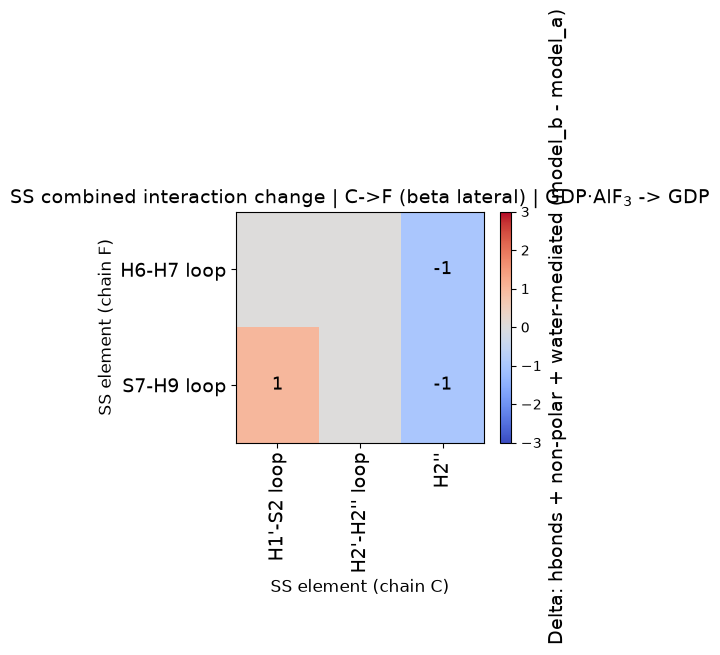

In [12]:
# Combined SS delta heatmaps (cell below SS pipeline): sum hbonds + non-polar + water-mediated
# deltas using the same SS grid as the pipeline (`iface_ss_axes` / `ss_delta_heats`).

mpl.rcParams["path.simplify"] = True
mpl.rcParams["path.simplify_threshold"] = 0.5  # try 0.1–1.0; higher = simpler
mpl.rcParams["agg.path.chunksize"] = 10000
mpl.rcParams["svg.fonttype"] = "none"  
os.makedirs("heatmaps", exist_ok=True)
os.makedirs("heatmaps/combined_delta", exist_ok=True)

if "ss_delta_heats" not in globals() or "iface_ss_axes" not in globals() or "ss_per_model_heats" not in globals():
    raise RuntimeError(
        "Missing ss_delta_heats / iface_ss_axes / ss_per_model_heats. Run the SS heatmap pipeline cell first."
    )
if "model_order" not in globals():
    raise RuntimeError("model_order is not defined.")

if "display_model_name" not in globals():
    def display_model_name(m):
        return str(m)

_SS_COMBO_CATEGORIES = ("hbonds", "non-polar", "water-mediated")

_iface_chain_xy = {}
for _spec in globals().get("interface_specs") or []:
    _lab = _spec.get("label")
    _pairs = _spec.get("pairs") or []
    if _lab and _pairs:
        _iface_chain_xy[_lab] = _pairs[0]


def _combined_counts_dict_pipeline(il, model):
    """(x_ss, y_ss) -> count summed over the three pipeline categories (per model)."""
    acc = defaultdict(int)
    for cat in _SS_COMBO_CATEGORIES:
        h = ss_per_model_heats[il][cat][model]
        for y_ss in h.index:
            for x_ss in h.columns:
                acc[(x_ss, y_ss)] += int(h.at[y_ss, x_ss])
    return dict(acc)


def _aligned_category_delta(il, model_a, model_b, cat):
    xo = iface_ss_axes[il]["x_order"]
    yo = iface_ss_axes[il]["y_order"]
    h = ss_delta_heats[il][cat][(model_a, model_b)]
    return h.reindex(index=yo, columns=xo, fill_value=0)


# ----- (1) Build: summed delta tables (reuse iface_ss_axes for every matrix) -----
ss_combined_delta_heats = {}
for il in iface_ss_axes:
    ss_combined_delta_heats[il] = {}
    for i in range(len(model_order) - 1):
        ma, mb = model_order[i], model_order[i + 1]
        parts = [_aligned_category_delta(il, ma, mb, cat) for cat in _SS_COMBO_CATEGORIES]
        ss_combined_delta_heats[il][(ma, mb)] = sum(parts[1:], start=parts[0])

# ----- (2) Plot: one heatmap per interface / transition; shared symmetric scale per interface -----
def _plot_ss_delta_combined(heat, title, chain_x="X", chain_y="Y", vmin=None, vmax=None):
    if heat.empty:
        print(f"No data: {title}")
        return

    arr = heat.to_numpy(dtype=float)
    if vmin is None or vmax is None:
        m = float(np.abs(arr).max()) if arr.size else 0.0
        if m == 0:
            m = 1.0
        vmin, vmax = -m, m

    plt.figure(figsize=(max(4.0, 0.45 * len(heat.columns)), max(3.0, 0.45 * len(heat.index))))
    im = plt.imshow(arr, aspect="auto", cmap="coolwarm", vmin=vmin, vmax=vmax)
    cbar = plt.colorbar(im)
    cbar.set_label(
        "Delta: hbonds + non-polar + water-mediated (model_b - model_a)",
        fontsize=14,
    )
    plt.xticks(range(len(heat.columns)), heat.columns, rotation=90, fontsize=14)
    plt.yticks(range(len(heat.index)), heat.index, fontsize=14)
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v = int(round(heat.iat[i, j]))
            if v != 0:
                plt.text(j, i, str(v), ha="center", va="center", fontsize=13, color="black")
    plt.title(title, fontsize=14)
    plt.xlabel(f"SS element (chain {chain_x})", fontsize=12)
    plt.ylabel(f"SS element (chain {chain_y})", fontsize=12)
    safe = re.sub(r"[^\w\-.]+", "_", title).strip("_")[:200]
    plt.savefig(f"heatmaps/combined_delta/{safe}.svg", dpi=300, format="svg", bbox_inches="tight")
    plt.show()


iface_list = list(iface_ss_axes.keys())

for il in iface_list:
    vmax_iface = 0.0
    for i in range(len(model_order) - 1):
        ma, mb = model_order[i], model_order[i + 1]
        d = ss_combined_delta_heats[il][(ma, mb)]
        if not d.empty:
            vmax_iface = max(vmax_iface, float(np.abs(d.to_numpy()).max()))
    if vmax_iface == 0:
        vmax_iface = 1.0

    primary_x, primary_y = _iface_chain_xy.get(il, ("X", "Y"))

    for i in range(len(model_order) - 1):
        ma, mb = model_order[i], model_order[i + 1]
        la = display_model_name(ma)
        lb = display_model_name(mb)
        delta = ss_combined_delta_heats[il][(ma, mb)]
        title = f"SS combined interaction change | {il} | {la} -> {lb}"
        _plot_ss_delta_combined(
            delta,
            title,
            chain_x=primary_x,
            chain_y=primary_y,
            vmin=-vmax_iface,
            vmax=vmax_iface,
        )



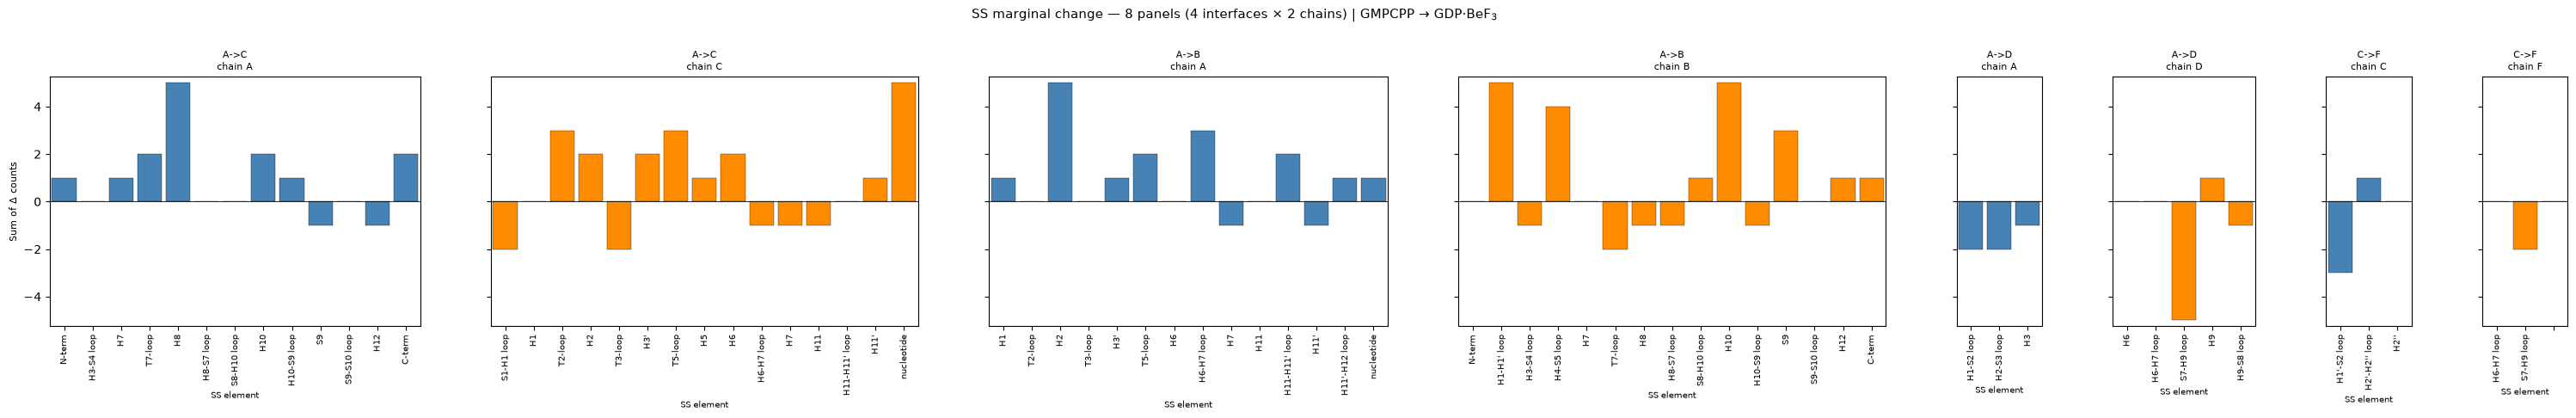

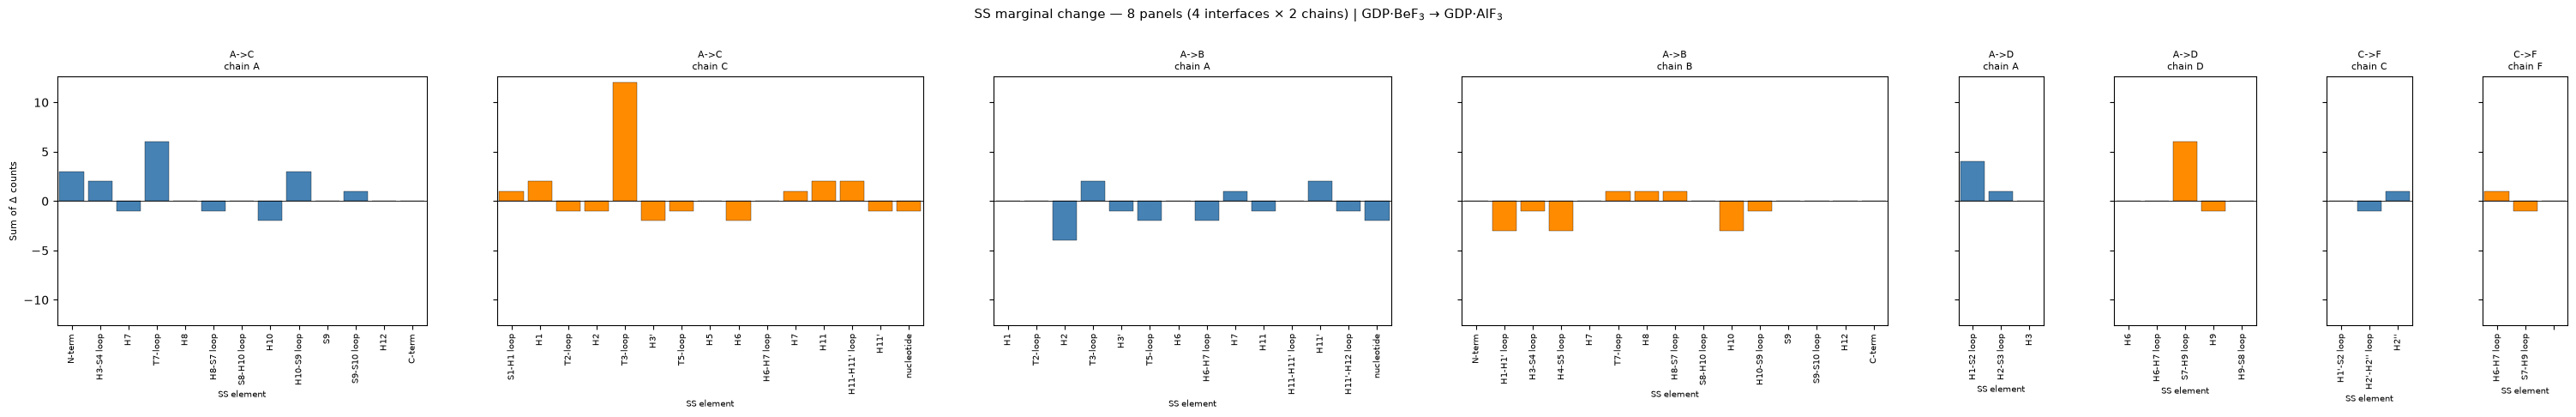

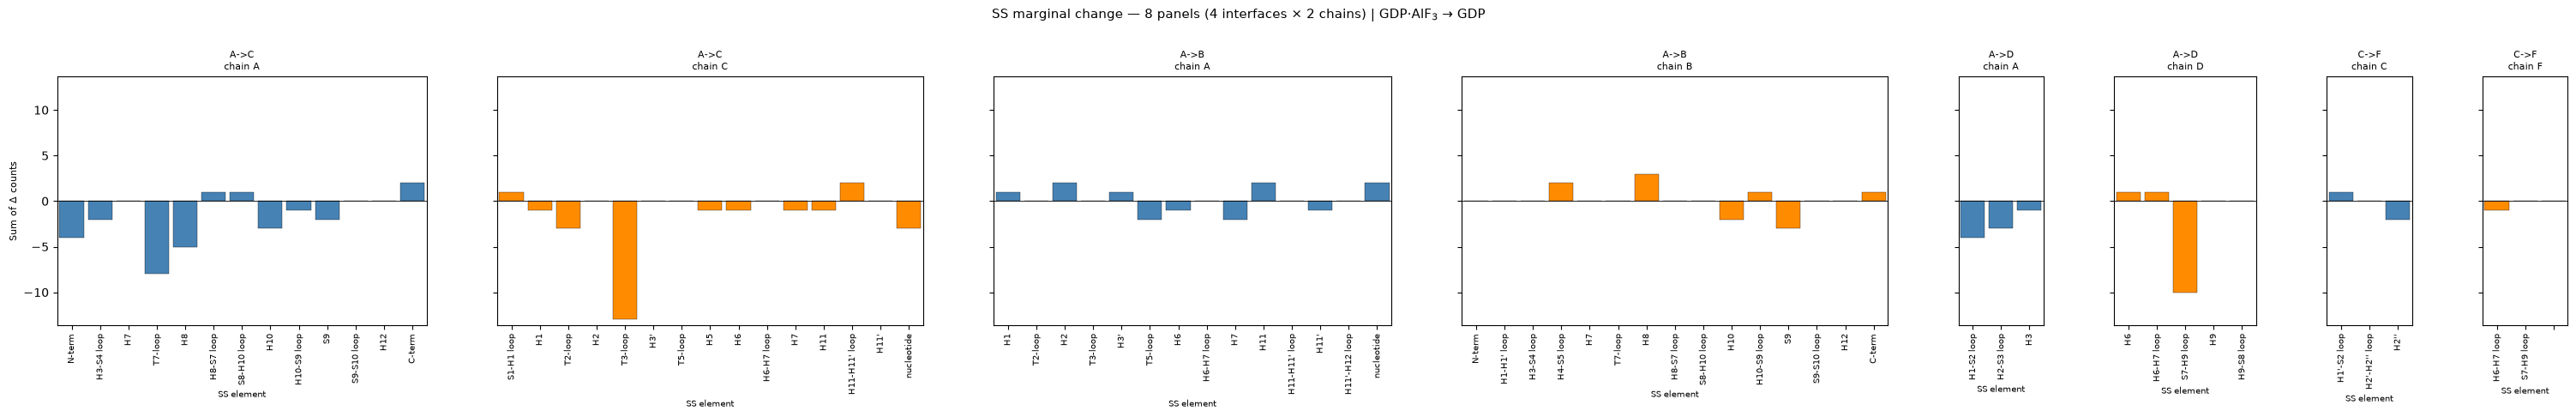

In [13]:
# SS marginal totals per chain (all interfaces on one row per transition)
# One figure per transition: 1 row × 8 axes. Lateral interfaces use a narrow width (3 "slots");
# inter/intradimer axis width scales with #SS labels. Shared y-axis; fixed BAR_WIDTH in data units.

if "ss_per_model_heats" not in globals() or "iface_ss_axes" not in globals():
    raise RuntimeError(
        "Run the SS heatmap pipeline cell and the combined-delta cell first "
        "(needs ss_per_model_heats, iface_ss_axes, and _combined_counts_dict_pipeline)."
    )
if "_combined_counts_dict_pipeline" not in globals():
    raise RuntimeError("Run the combined SS delta cell first (defines _combined_counts_dict_pipeline).")


if "display_model_name" not in globals():
    def display_model_name(m):
        return str(m)

if "CHAIN_TO_SUBUNIT" not in globals():
    CHAIN_TO_SUBUNIT = {
        "A": "alpha", "C": "beta", "E": "beta",
        "B": "beta", "D": "alpha", "F": "beta",
    }

interface_specs = [
    {"label": "A->C (interdimer)", "pairs": [("A", "C")]},
    {"label": "A->B (intradimer)", "pairs": [("A", "B")]},
    {"label": "A->D (alpha lateral)", "pairs": [("A", "D")]},
    {"label": "C->F (beta lateral)", "pairs": [("C", "F")]},
]

BAR_WIDTH = 0.85
LATERAL_WIDTH_RATIO = 3.0  # subplot column width for lateral panels (~3 SS slots)


def _dict_to_heat_marginal(counts_dict, x_order, y_order):
    if not counts_dict:
        return pd.DataFrame()
    rows = [{"x_ss": k[0], "y_ss": k[1], "n": v} for k, v in counts_dict.items()]
    heat = pd.DataFrame(rows).pivot_table(index="y_ss", columns="x_ss", values="n", aggfunc="sum", fill_value=0)
    return heat.reindex(index=y_order, columns=x_order, fill_value=0)


def _iface_short(lab):
    return lab.split("(")[0].strip()[:28]


def _is_lateral_interface(iface_label):
    return "lateral" in str(iface_label).lower()


def _x_slots_for_panel(iface_label, n_labels):
    """Number of x slots (and GridSpec width ratio) for this panel."""
    n = int(n_labels)
    if _is_lateral_interface(iface_label):
        return max(int(LATERAL_WIDTH_RATIO), n, 1)
    return max(n, 1)


marginal_specs = interface_specs
assert len(marginal_specs) == 4
ncols = 2 * len(marginal_specs)

for ti in range(len(model_order) - 1):
    model_a = model_order[ti]
    model_b = model_order[ti + 1]
    la = display_model_name(model_a)
    lb = display_model_name(model_b)

    panels = []
    all_abs = []

    for spec in marginal_specs:
        iface = spec["label"]
        primary_x, primary_y = spec["pairs"][0]
        x_sub = CHAIN_TO_SUBUNIT.get(primary_x)
        y_sub = CHAIN_TO_SUBUNIT.get(primary_y)

        ca = _combined_counts_dict_pipeline(iface, model_a)
        cb = _combined_counts_dict_pipeline(iface, model_b)
        x_order = iface_ss_axes[iface]["x_order"]
        y_order = iface_ss_axes[iface]["y_order"]

        heat_a = _dict_to_heat_marginal(ca, x_order, y_order)
        heat_b = _dict_to_heat_marginal(cb, x_order, y_order)
        delta = heat_b - heat_a

        col_sum = delta.sum(axis=0)
        row_sum = delta.sum(axis=1)

        xv = col_sum.reindex(x_order, fill_value=0).values.astype(float)
        yv = row_sum.reindex(y_order, fill_value=0).values.astype(float)
        x_labels_ord = [str(x) for x in x_order]
        y_labels_ord = [str(y) for y in y_order]

        all_abs.extend(np.abs(xv).tolist())
        all_abs.extend(np.abs(yv).tolist())

        short = _iface_short(iface)
        panels.append((short, iface, primary_x, primary_y, x_labels_ord, xv, "col"))
        panels.append((short, iface, primary_x, primary_y, y_labels_ord, yv, "row"))

    ymax = float(np.max(all_abs)) if all_abs else 1.0
    if ymax == 0:
        ymax = 1.0
    ymax *= 1.05

    widths = [_x_slots_for_panel(iface, len(labels)) for (_s, iface, _px, _py, labels, _vals, _k) in panels]
    fig_w = max(14, 0.42 * sum(widths) + 1.5)
    fig = plt.figure(figsize=(fig_w, 5.0), constrained_layout=False)
    gs = gridspec.GridSpec(1, ncols, figure=fig, width_ratios=widths, wspace=0.28)

    axes = []
    for i in range(ncols):
        if i == 0:
            ax = fig.add_subplot(gs[0, i])
        else:
            ax = fig.add_subplot(gs[0, i], sharey=axes[0])
        axes.append(ax)

    for j, (ax, (short, iface, px, py, labels, vals, kind)) in enumerate(zip(axes, panels)):
        labels = list(labels)
        vals = np.asarray(vals, dtype=float).tolist()
        slot_n = _x_slots_for_panel(iface, len(labels))
        n = len(labels)
        if n < slot_n:
            labels = labels + [""] * (slot_n - n)
            vals = vals + [0.0] * (slot_n - n)

        xpos = np.arange(slot_n)
        if len(vals) != slot_n or len(labels) != slot_n:
            vals = (list(vals) + [0.0] * slot_n)[:slot_n]
            labels = (list(labels) + [""] * slot_n)[:slot_n]
        color = "steelblue" if kind == "col" else "darkorange"
        ax.bar(xpos, vals, width=BAR_WIDTH, color=color, edgecolor="k", linewidth=0.25)
        ax.set_xticks(xpos)
        ax.set_xticklabels(labels, rotation=90, fontsize=7)
        ax.set_xlim(-0.5, slot_n - 0.5)
        ax.axhline(0, color="k", linewidth=0.6)
        ax.set_ylim(-ymax, ymax)
        who = f"chain {px}" if kind == "col" else f"chain {py}"
        ax.set_title(f"{short}\n{who}", fontsize=8)
        ax.set_xlabel("SS element", fontsize=7)
        if j == 0:
            ax.set_ylabel("Sum of Δ counts", fontsize=8)
        else:
            ax.tick_params(labelleft=False)

    fig.suptitle(
        f"SS marginal change — 8 panels (4 interfaces × 2 chains) | {la} → {lb}",
        fontsize=11,
        y=1.02,
    )
    fig.subplots_adjust(top=0.86, left=0.06, right=0.995, bottom=0.28)
    plt.show()



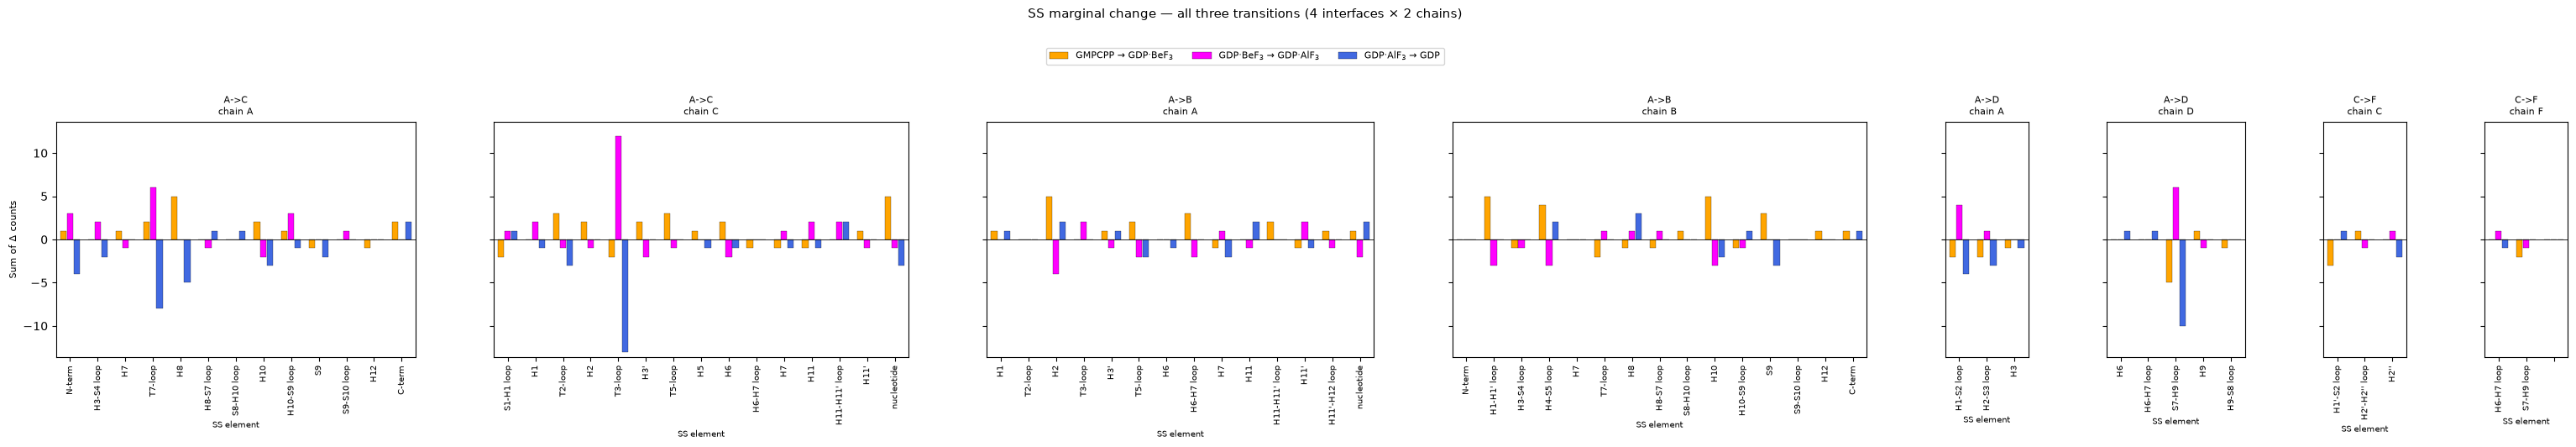

In [14]:
# All three transitions on one 1×8 row (grouped bars per SS element)


if "ss_per_model_heats" not in globals() or "iface_ss_axes" not in globals():
    raise RuntimeError("Run the SS heatmap pipeline cell and the combined-delta cell first.")
if "_combined_counts_dict_pipeline" not in globals():
    raise RuntimeError("Run the combined SS delta cell first (defines _combined_counts_dict_pipeline).")
if "_ordered_ss_labels" not in globals():
    raise RuntimeError("Run a cell that defines _ordered_ss_labels first.")

if "model_order" not in globals():
    model_order = [
        "GMPCPP_13pf_6mer_fitted.pdb",
        "BeF3_6mer_swapAtoms.pdb",
        "AlF3_6mer_swapAtoms.pdb",
        "GDP_13pf_6mer_fitted.pdb",
    ]
if "display_model_name" not in globals():
    def display_model_name(m):
        return str(m)
if "CHAIN_TO_SUBUNIT" not in globals():
    CHAIN_TO_SUBUNIT = {
        "A": "alpha", "C": "beta", "E": "beta",
        "B": "beta", "D": "alpha", "F": "beta",
    }

interface_specs = [
    {"label": "A->C (interdimer)", "pairs": [("A", "C")]},
    {"label": "A->B (intradimer)", "pairs": [("A", "B")]},
    {"label": "A->D (alpha lateral)", "pairs": [("A", "D")]},
    {"label": "C->F (beta lateral)", "pairs": [("C", "F")]},
]

LATERAL_WIDTH_RATIO = 3.0
TRANS_COLORS = ["orange", "magenta", "royalblue"]  # GMPCPP→BeF3, BeF3→AlF3, AlF3→GDP
TRANS_LEGEND = [
    f"{display_model_name(model_order[0])} → {display_model_name(model_order[1])}",
    f"{display_model_name(model_order[1])} → {display_model_name(model_order[2])}",
    f"{display_model_name(model_order[2])} → {display_model_name(model_order[3])}",
]


def _dict_to_heat_marginal(counts_dict, x_order, y_order):
    if not counts_dict:
        return pd.DataFrame()
    rows = [{"x_ss": k[0], "y_ss": k[1], "n": v} for k, v in counts_dict.items()]
    heat = pd.DataFrame(rows).pivot_table(index="y_ss", columns="x_ss", values="n", aggfunc="sum", fill_value=0)
    return heat.reindex(index=y_order, columns=x_order, fill_value=0)


def _iface_short(lab):
    return lab.split("(")[0].strip()[:28]


def _is_lateral_interface(iface_label):
    return "lateral" in str(iface_label).lower()


def _x_slots_for_panel(iface_label, n_labels):
    n = int(n_labels)
    if _is_lateral_interface(iface_label):
        return max(int(LATERAL_WIDTH_RATIO), n, 1)
    return max(n, 1)


def _marginal_series_for_transition(model_a, model_b, spec, kind):
    iface = spec["label"]
    primary_x, primary_y = spec["pairs"][0]
    x_sub = CHAIN_TO_SUBUNIT.get(primary_x)
    y_sub = CHAIN_TO_SUBUNIT.get(primary_y)
    ca = _combined_counts_dict_pipeline(iface, model_a)
    cb = _combined_counts_dict_pipeline(iface, model_b)
    x_order = iface_ss_axes[iface]["x_order"]
    y_order = iface_ss_axes[iface]["y_order"]
    heat_a = _dict_to_heat_marginal(ca, x_order, y_order)
    heat_b = _dict_to_heat_marginal(cb, x_order, y_order)
    delta = heat_b - heat_a
    if kind == "col":
        s = delta.sum(axis=0)
        sub = x_sub
    else:
        s = delta.sum(axis=1)
        sub = y_sub
    return s, sub, primary_x, primary_y

marginal_specs = interface_specs
ncols = 2 * len(marginal_specs)
n_trans = len(model_order) - 1

aligned_panels = []
all_abs = []

for spec in marginal_specs:
    iface = spec["label"]
    short = _iface_short(iface)
    for kind in ("col", "row"):
        series_list = []
        for ti in range(n_trans):
            model_a = model_order[ti]
            model_b = model_order[ti + 1]
            s, sub, px, py = _marginal_series_for_transition(model_a, model_b, spec, kind)
            series_list.append((s.astype(float), sub))
        idx = series_list[0][0].index.union(series_list[1][0].index).union(series_list[2][0].index)
        sub0 = series_list[0][1]
        labels_order = list(_ordered_ss_labels(sub0, idx))
        vals_three = []
        for s, _sub in series_list:
            v = s.reindex(labels_order, fill_value=0.0).values.astype(float)
            vals_three.append(v)
            all_abs.extend(np.abs(v).tolist())
        slot_n = _x_slots_for_panel(iface, len(labels_order))
        n = len(labels_order)
        if n < slot_n:
            labels_order = labels_order + [""] * (slot_n - n)
            vals_three = [np.concatenate([v, np.zeros(slot_n - n)]) for v in vals_three]
        elif n > slot_n:
            labels_order = labels_order[:slot_n]
            vals_three = [v[:slot_n] for v in vals_three]
        aligned_panels.append((short, iface, px, py, kind, labels_order, vals_three, slot_n))

ymax = float(np.max(all_abs)) if all_abs else 1.0
if ymax == 0:
    ymax = 1.0
ymax *= 1.05

widths = [slot_n for (_s, _iface, _px, _py, _k, _lab, _v3, slot_n) in aligned_panels]
fig_w = max(16, 0.42 * sum(widths) + 2.0)
fig = plt.figure(figsize=(fig_w, 5.2), constrained_layout=False)
gs = gridspec.GridSpec(1, ncols, figure=fig, width_ratios=widths, wspace=0.32)

axes = []
for i in range(ncols):
    if i == 0:
        ax = fig.add_subplot(gs[0, i])
    else:
        ax = fig.add_subplot(gs[0, i], sharey=axes[0])
    axes.append(ax)

GROUP_W = 0.24
offsets = np.array([-GROUP_W, 0.0, GROUP_W])

for j, (ax, (short, iface, px, py, kind, labels, vals_three, slot_n)) in enumerate(zip(axes, aligned_panels)):
    xpos = np.arange(slot_n)
    for off, color, vals, leg in zip(offsets, TRANS_COLORS, vals_three, TRANS_LEGEND):
        ax.bar(xpos + off, vals, width=GROUP_W * 0.92, color=color, edgecolor="k", linewidth=0.2, label=leg)
    ax.set_xticks(xpos)
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_xlim(-0.5, slot_n - 0.5)
    ax.axhline(0, color="k", linewidth=0.6)
    ax.set_ylim(-ymax, ymax)
    who = f"chain {px}" if kind == "col" else f"chain {py}"
    ax.set_title(f"{short}\n{who}", fontsize=8)
    ax.set_xlabel("SS element", fontsize=7)
    if j == 0:
        ax.set_ylabel("Sum of Δ counts", fontsize=8)
    else:
        ax.tick_params(labelleft=False)

handles, leg_labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(leg_labels, handles))
fig.legend(
    by_label.values(),
    by_label.keys(),
    loc="upper center",
    ncol=3,
    fontsize=8,
    frameon=True,
    bbox_to_anchor=(0.5, 1.0),
)
fig.suptitle(
    "SS marginal change — all three transitions (4 interfaces × 2 chains)",
    fontsize=11,
    y=1.08,
)
fig.subplots_adjust(top=0.82, left=0.055, right=0.995, bottom=0.28)
plt.show()

